# Project 2.2: Multimodal Skin Lesion Classification

**Dataset:** PAD-UFES-20  
**Modalities:** Clinical lesion photographs and structured patient metadata  
**Task:** Six-class skin lesion classification  
**Project:** Team 10

## Research Objective

This project investigates whether combining clinical lesion photographs with the structured patient metadata improves the skin lesion classification while comparing with individual modalities.

Five modelling approaches are evaluated: metadata-only classification, image-only classification using EfficientNet-B0, early fusion, late fusion and intermediate gated fusion.

The analysis assesses accuracy, balanced accuracy, macro-F1, per-class performance, patient-disjoint data integrity, missingness-related bias, statistical uncertainty and computational efficiency.

The final model is selected using validation performance and evaluated on a held-out patient-disjoint test partition.

**Scope:** Educational research prototype, not intended for clinical diagnosis.


## Changes from the Project 2.1 Proposal

The final implementation preserves the original research question, PAD-UFES-20 dataset, six diagnostic categories, patient-disjoint partitions and comparison of three multimodal fusion approaches.

The following adjustments and extensions were made:

1. **Intermediate fusion:**  The proposed MetaBlock approach was adapted into a singular metadata-conditioned gated neural network. Where the network uses clinical metadata to modulate visual features rather than reproducing the original MetaBlock architecture exactly.

2. **Image preprocessing:** Deterministic image transformations were implemented without the originally proposed training-time augmentation. This enabled consistent extraction and reuse of frozen EfficientNet-B0 embeddings, reducing computational requirements but limiting augmentation-based robustness assessment.

3. **Evaluation methodology:** The five primary models were initially compared using a fixed patient-disjoint training and validation split. Patient-clustered bootstrap confidence intervals were calculated to assess uncertainty. Subsequently, five-fold stratified patient-grouped cross-validation was completed on the development dataset in Section 15.1, comparing metadata-only, image-only and early-fusion approaches while maintaining patient separation.

4. **Feature ablation:** Modality-permutation analysis assessed the dependence of early fusion on image and metadata information. Additionally, Section 15.2 implemented the originally proposed conservative-versus-fuller metadata comparison using five-fold patient-grouped cross-validation. Although fuller metadata improved internal macro-F1, systematic missingness introduced  the potential shortcut-learning concerns.
   

5. **Clinical evaluation:** The primary evaluation reported the six-class classification metrics, including melanoma and squamous cell carcinoma recall. Section 15.3 subsequently introduced a supplementary malignant-versus-benign analysis using existing held-out test predictions. This retrospective analysis excluded true ACK cases and assessed sensitivity, specificity and false negatives without retraining or threshold optimisation.

6. **Additional robustness and fairness investigations:** Section 7.5 assessed the early-fusion training–validation generalisation gap. Section 7.6 examined nine scaling and regularisation configurations, while Section 9.3A evaluated gated-fusion stability across five random seeds. Section 7.7 conducted an exploratory demographic subgroup audit. Section 14.8 additionally compared the unchanged unimodal baselines against early fusion on the held-out test partition. These supplementary analyses did not change the originally selected classifier or its test results.

These adaptations balanced computational feasibilty, methodological rigour and clinical interpretability. The supplementary experiments strengthened evaluation while preserving originally selected early-fusion classifier and its held-out test results.

**Remaining limitations:** Class imbalance, possible metadata-related shortcuts, limited minority-class sensitivity and the absence of external clinical validation.

In [1]:
#Section 1  Environment Setup and Reproducibility

import sys
import platform
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import torch
import torchvision

#Set reproducible random seeds
SEED= 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

#Select available computing device
if torch.backends.mps.is_available():
    DEVICE= torch.device("mps")
elif torch.cuda.is_available():
    DEVICE= torch.device("cuda")
else:
    DEVICE= torch.device("cpu")
                 
#Define project file paths
              
PROJECT_DIR= Path.cwd()

METADATA_PATH= PROJECT_DIR / "metadata.csv"
SPLIT_PATH= PROJECT_DIR / "metadata_with_patient_split.csv"
IMAGE_DIR= PROJECT_DIR / "images"


#Verify required files and directories
assert METADATA_PATH.is_file(), "metadata.csv not found"
assert SPLIT_PATH.is_file(), "Patient split CSV not found"
assert IMAGE_DIR.is_dir(), "images folder not found"


# Display environment information
print("PROJECT 2.2  ENVIRONMENT VERIFICATION")

print("Python:", sys.version.split()[0])
print("Operating system:", platform.system())
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Matplotlib:", matplotlib.__version__)

print("\nSelected device:", DEVICE)
print("Random seed:", SEED)

print("\nProject directory:", PROJECT_DIR)
print("Metadata file:", METADATA_PATH.is_file())
print("Patient split file:", SPLIT_PATH.is_file())
print("Images directory:", IMAGE_DIR.is_dir())

print("\nSECTION 1 COMPLETED SUCCESSFULLY")

PROJECT 2.2  ENVIRONMENT VERIFICATION
Python: 3.12.14
Operating system: Darwin
PyTorch: 2.14.1
Torchvision: 0.29.1
Pandas: 3.0.5
NumPy: 1.26.4
Scikit-learn: 1.9.0
Matplotlib: 3.11.0

Selected device: mps
Random seed: 42

Project directory: /Users/avinashmonteiro/Desktop/PAD_UFES20_Project
Metadata file: True
Patient split file: True
Images directory: True

SECTION 1 COMPLETED SUCCESSFULLY


## 2. Dataset Loading and Integrity Verification
### 2.1 Dataset Overview
PAD-UFES-20 contains clinical images of skin lessions along with corresponding structured data about each patient. Six types of diagnosis are included in this classification problem: actinic keratosis (ACK), basal cell carcinoma (BCC), melanoma (MEL), melanocytic nevus (NEV), squamous cell carcinoma (SCC) and seborreheic keratosis (SEK).

This section loads the original metadata and previously generated patient-level partitions. Dataset dimesnions, identifiers, diagnostic labels and partition integrity are examined before any model develeopment.

Patient-disjoint splitiing is critical since there could be multiple images of one patient. Proper partitioning of patients into training, validation and test sets avoids bias in performance estimation due to patient identity leakage.

In [2]:
#Section  2.1 Load and inspect PAD-UFES-20 metadata

df= pd.read_csv(METADATA_PATH)
split_df= pd.read_csv(SPLIT_PATH)

CLASSES= ["ACK", "BCC", "MEL", "NEV", "SCC", "SEK"]

required_columns= { "patient_id","lesion_id", "img_id", "diagnostic"}

assert required_columns.issubset(df.columns), ("Original metadata is missing required columns.")

assert required_columns.union({"split"}).issubset(split_df.columns
), "Split metadata is missing required columns."

print("PAD-UFES-20 DATASET OVERVIEW")

print("Original metadata shape:",df.shape)
print("Split metadata shape:",split_df.shape)

print("\nUnique patients:",df["patient_id"].nunique())
print("\nUnique lesions:",df["lesion_id"].nunique())
print("\nUnique images:",df["img_id"].nunique())

print("\nDiagnois class distribution:")
print(df["diagnostic"].value_counts().reindex(CLASSES, fill_value=0))

print("\nFirst five metadata records:")
display(df.head())

print("\nSECTION 2.1 COMPLETED SUCCESSFULLY")

PAD-UFES-20 DATASET OVERVIEW
Original metadata shape: (2298, 26)
Split metadata shape: (2298, 27)

Unique patients: 1373

Unique lesions: 1641

Unique images: 2298

Diagnois class distribution:
diagnostic
ACK    730
BCC    845
MEL     52
NEV    244
SCC    192
SEK    235
Name: count, dtype: int64

First five metadata records:


,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed
0,PAT_1516,1765,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,...,NaN,NEV,False,False,False,False,False,False,PAT_1516_1765_530.png,False
1,PAT_46,881,False,False,POMERANIA,POMERANIA,55,False,FEMALE,True,...,5.0,BCC,True,True,False,True,True,True,PAT_46_881_939.png,True
2,PAT_1545,1867,NaN,NaN,NaN,NaN,77,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,False,False,PAT_1545_1867_547.png,False
3,PAT_1989,4061,NaN,NaN,NaN,NaN,75,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,False,False,PAT_1989_4061_934.png,False
4,PAT_684,1302,False,True,POMERANIA,POMERANIA,79,False,MALE,True,...,5.0,BCC,True,True,False,False,True,True,PAT_684_1302_588.png,True



SECTION 2.1 COMPLETED SUCCESSFULLY


In [3]:
#Section 2.2  Patient-disjoint partition verification

#Check permitted partition labels
expected_splits= {"train", "validation", "test"}

assert set(split_df["split"])== expected_splits, ( "Unexpected or missing split labels.")

#Verify unique image identifiers
assert df["img_id"].is_unique
assert split_df["img_id"].is_unique

#Verify original metadata matches split metadata
audit_columns= ["img_id","patient_id","lesion_id","diagnostic"]

comparison= df[audit_columns].merge(
    split_df[audit_columns],
    on= "img_id",
    how= "outer",
    validate= "one_to_one",
    indicator= True,
    suffixes= ("_original", "_split")
)

assert (comparison["_merge"]== "both").all()

for col in ["patient_id", "lesion_id", "diagnostic"]:
    assert (
        comparison[f"{col}_original"]
        == comparison[f"{col}_split"]
    ).all(), f"Metadata mismatch in {col}"

#Create DataFrames used throughout the notebook
train_df= split_df.loc[
    split_df["split"]== "train"
].copy().reset_index(drop=True)

val_df= split_df.loc[
    split_df["split"]== "validation"
].copy().reset_index(drop=True)

test_df= split_df.loc[
    split_df["split"]== "test"
].copy().reset_index(drop=True)

#Extract patient groups
train_patients= set(train_df["patient_id"])
val_patients= set(val_df["patient_id"])
test_patients= set(test_df["patient_id"])

#Prevent patients appearing across partitions
assert train_patients.isdisjoint(val_patients)
assert train_patients.isdisjoint(test_patients)
assert val_patients.isdisjoint(test_patients)

print("PATIENT-LEVEL PARTITION VERIFICATION")

for name, part in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        f"{name:12s}: {len(part):4d} images, "
        f"{part['patient_id'].nunique():3d} patients"
    )

print("\nPatient overlaps:")
print("Train vs Validation:",len(train_patients & val_patients))
print("Train vs Test:",len(train_patients & test_patients))
print("Validation vs Test:", len(val_patients & test_patients))
print("\nAll patient-disjoint integrity checks PASSED.")

PATIENT-LEVEL PARTITION VERIFICATION
Training    : 1640 images, 980 patients
Validation  :  329 images, 196 patients
Test        :  329 images, 197 patients

Patient overlaps:
Train vs Validation: 0
Train vs Test: 0
Validation vs Test: 0

All patient-disjoint integrity checks PASSED.


### 2.2A Dataset Split Provenance and Reproducibility

The study makes use of the existing patient disjoint partition file with metadata_with_patient_split.csv which was created before the start of Project 2.2

This file provides fixed training, validation and test assignments. The original split-generation algorithm is not included in this notebook.

In order to ensure that the experiment partitions are reproducible, this process entails the following:

1. Confirms that every image has exactly one partition.
2. Verifies that each patient belongs to only one partition.
3. Records image, patient and class counts.
4. Clculates a SHA-256 checksum for the partition file.
5. Exports a manifest containing partition summaries, class distributions and a SHA-256 checksum of the original split file.

The manifest verifiies the identity and summary of the fixed partition file but it does not contain individual image-to--split assignments. Exact reproduction therefore requires the corresponding CSV.

The same partition file must be used to reproduce the reported model comparisons and held-out evaluation.

The original splitting method and its parameters should be documented separately if the original project 2.1 split-generation code is available.


In [4]:
#Section 2.2A Dataset split provenance and reproducibility

import hashlib
import json
from pathlib import Path
import pandas as pd

#Verify unique image assignments.
assert split_df["img_id"].is_unique
assert split_df["img_id"].notna().all()
assert split_df["patient_id"].notna().all()

#Verify each patient has only one split assignment.
patient_split_counts= ( split_df.groupby("patient_id")["split"].nunique())

assert (patient_split_counts== 1).all(), ("A patient occurs in multiple partitions.")

#Confirm original records and split records match.
assert set(split_df["img_id"])== set(df["img_id"])

# Generate the fixed split summary.
split_summary= (
    split_df.groupby("split")
    .agg(
        images= ("img_id", "size"),
        patients= ("patient_id", "nunique"),
        lesions= ("lesion_id", "nunique")
    )
    .reindex(["train", "validation", "test"])
)

class_summary= pd.crosstab(
    split_df["diagnostic"],
    split_df["split"]
).reindex(
    index= CLASSES,
    columns= ["train", "validation", "test"],
    fill_value= 0
)

#Compute the SHA-256 fingerprint of the exact input file.
sha256= hashlib.sha256()

with open(SPLIT_PATH, "rb") as file:
    for chunk in iter(lambda: file.read(1024 * 1024), b""):
        sha256.update(chunk)

split_checksum= sha256.hexdigest()

#Create reproducibility documentation.
manifest= {
    "dataset": "PAD-UFES-20",
    "split_file": SPLIT_PATH.name,
    "split_sha256": split_checksum,
    "partition_source": "Pre-existing fixed partition file",
    "partition_generation": (
        "Original generation code not included in "
        "this notebook"
    ),
    "image_count": int(len(split_df)),
    "patient_count": int(split_df["patient_id"].nunique()),
    "patient_disjoint": True,
    "splits": {
        partition: {
            "images": int(split_summary.loc[partition, "images"]),
            "patients": int(split_summary.loc[partition, "patients"]),
            "lesions": int(split_summary.loc[partition, "lesions"])
        }
        for partition in ["train", "validation", "test"]
    },
    "class_counts": {
        cls: {
            partition: int(class_summary.loc[cls, partition])
            for partition in ["train", "validation", "test"]
        }
        for cls in CLASSES
    }
}

#Store the manifest in the exisiting project output folder.
manifest_dir= PROJECT_DIR/"project2_2_outputs"
manifest_dir.mkdir(parents=True, exist_ok=True)

manifest_path= manifest_dir / "patient_split_manifest.json"

with open(manifest_path, "w", encoding="utf-8") as file:
    json.dump(manifest, file, indent=2)

print("DATASET SPLIT PROVENANCE VERIFICATION")

print("Split file:", SPLIT_PATH.name)
print("SHA-256:", split_checksum)

print("\nPartition summary:")
display(split_summary)

print("\nClass distribution:")
display(class_summary)

print("\nUnique patients:", split_df["patient_id"].nunique())
print("Patient overlap:",0)
print("Manifest saved:",manifest_path)

print("\nPASS: Fixed patient-disjoint partitions verified.")
print("SECTION 2.2A COMPLETED SUCCESSFULLY")

DATASET SPLIT PROVENANCE VERIFICATION
Split file: metadata_with_patient_split.csv
SHA-256: 05866db4bf25d608e1a63d18858a71a5e405d72658bd22333d1103df54ee041e

Partition summary:


,images,patients,lesions
split,,,
train,1640,980,1219
validation,329,196,271
test,329,197,276



Class distribution:


split,train,validation,test
diagnostic,,,
ACK,522,104,104
BCC,603,121,121
MEL,37,8,7
NEV,174,35,35
SCC,136,28,28
SEK,168,33,34



Unique patients: 1373
Patient overlap: 0
Manifest saved: /Users/avinashmonteiro/Desktop/PAD_UFES20_Project/project2_2_outputs/patient_split_manifest.json

PASS: Fixed patient-disjoint partitions verified.
SECTION 2.2A COMPLETED SUCCESSFULLY


In [5]:
#Section 2.2B - Lesion identity integrity verification

import pandas as pd

#Count lesion IDs globally and separately by partition.
global_lesions= split_df["lesion_id"].nunique()

partition_lesions= ( split_df.groupby("split")["lesion_id"].nunique())

#Determine whether a lesion ID appears under
#more than one patient.
patients_per_lesion= (split_df.groupby("lesion_id")["patient_id"].nunique())

reused_lesion_ids= patients_per_lesion[patients_per_lesion > 1]

#Determine whether raw lesion IDs appear across splits.
splits_per_lesion= (split_df.groupby("lesion_id")["split"].nunique())

cross_split_ids= splits_per_lesion[splits_per_lesion > 1]

#Check patient-and-lesion pairs as composite identities.
pair_splits= (split_df.groupby(["patient_id", "lesion_id"])["split"].nunique())

cross_split_pairs= pair_splits[
    pair_splits>1
]

print("LESION IDENTITY INTEGRITY VERIFICATION")

print("Globally unique lesion IDs:", global_lesions)
print("Sum of partition-specific unique lesion IDs:",int(partition_lesions.sum()))
print("Lesion IDs used by multiple patients:",len(reused_lesion_ids))

print("Lesion IDs occurring across partitions:",len(cross_split_ids))

print("Patient-lesion pairs crossing partitions:",len(cross_split_pairs))

assert len(cross_split_pairs)== 0, ("Patient-lesion leakage detected!")

print("\nPASS: No patient-lesion pairs cross partitions.")

if len(cross_split_ids)>0:
    print(
        "\nNOTE:Some raw lesion IDs are reused across "
        "partitions. Inspect whether these correspond "
        "to distinct patients."
    )
    example_ids= cross_split_ids.index[:5]

    display(
        split_df.loc[
            split_df["lesion_id"].isin(example_ids),
            ["patient_id", "lesion_id", "split"]
        ].drop_duplicates().sort_values(
            ["lesion_id", "patient_id"]
        )
    )

print("\nSECTION 2.2B COMPLETED")

LESION IDENTITY INTEGRITY VERIFICATION
Globally unique lesion IDs: 1641
Sum of partition-specific unique lesion IDs: 1766
Lesion IDs used by multiple patients: 250
Lesion IDs occurring across partitions: 125
Patient-lesion pairs crossing partitions: 0

PASS: No patient-lesion pairs cross partitions.

NOTE:Some raw lesion IDs are reused across partitions. Inspect whether these correspond to distinct patients.


,patient_id,lesion_id,split
1709,PAT_9,17,train
1648,PAT_998,17,validation
1739,PAT_1000,31,train
2146,PAT_21,31,test
37,PAT_1006,53,test
1840,PAT_38,53,train
1655,PAT_1021,112,test
383,PAT_74,112,train
1686,PAT_1022,114,validation
854,PAT_75,114,train



SECTION 2.2B COMPLETED


In [6]:
#Section 2.2C Patient-specific lesion identity count

unique_patient_lesions= (split_df[["patient_id","lesion_id"]].drop_duplicates())

print("LESION IDENTITY SUMMARY")
print("Unique raw lesion IDS:",split_df["lesion_id"].nunique())
print("Unique patient-lesion pairs:",len(unique_patient_lesions))

assert(unique_patient_lesions["patient_id"].notna().all())
assert(unique_patient_lesions["lesion_id"].notna().all())

print("SECTION 2.2C COMPLETED SUCCESSFULLY")

LESION IDENTITY SUMMARY
Unique raw lesion IDS: 1641
Unique patient-lesion pairs: 1891
SECTION 2.2C COMPLETED SUCCESSFULLY


CLASS DISTRIBUTION BY DATA PARTITION


split,train,validation,test,Total
diagnostic,,,,
ACK,522,104,104,730
BCC,603,121,121,845
MEL,37,8,7,52
NEV,174,35,35,244
SCC,136,28,28,192
SEK,168,33,34,235


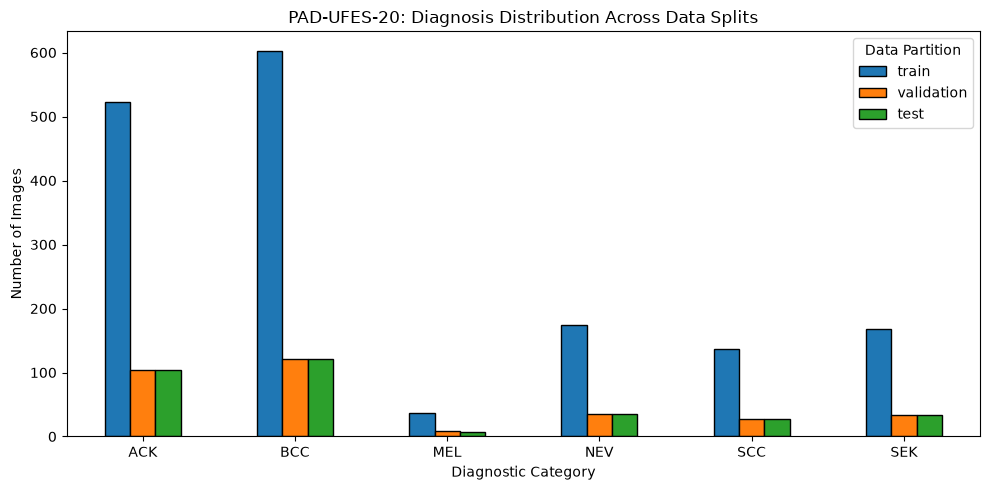


SECTION 2 COMPLETED SUCCESSFULLY


In [7]:
#Section 2.3  Diagnosis class distribution

class_distribution= pd.crosstab(
    split_df["diagnostic"],
    split_df["split"]
).reindex(
    index=CLASSES,
    columns=["train", "validation", "test"],
    fill_value=0
)

class_distribution["Total"]= (class_distribution.sum(axis=1))

print("CLASS DISTRIBUTION BY DATA PARTITION")
display(class_distribution)

#Check all diagnostic classes are represented
assert (
    class_distribution[
        ["train", "validation", "test"]
    ] > 0
).all().all(), "At least one class is absent from a split."

#Visualise class imbalance
ax= class_distribution[
    ["train", "validation", "test"]
].plot(
    kind= "bar",
    figsize= (10, 5),
    edgecolor= "black"
)

ax.set_title("PAD-UFES-20: Diagnosis Distribution Across Data Splits")
ax.set_xlabel("Diagnostic Category")
ax.set_ylabel("Number of Images")

plt.xticks(rotation=0)
plt.legend(title="Data Partition")
plt.tight_layout()
plt.show()

print("\nSECTION 2 COMPLETED SUCCESSFULLY")

### 2.4 Interpretation of Dataset Integrity and Class Distribution

The PAD-UFES-20 data set includes 2,298 clinical photographs that were extracted from 1,373 patients which gives us 1,891 unique patient-lesion identifiers combinations. Though there are 1,641 unique raw lesion IDS some identifiers are reused across patients.

The existing patient-level partition consists of 1,640 training images, 329 validation images and 329 test images. Where the integriry checks confirmed that the image identifiers and assosciated patient, lesion and diagnosis information match across  the original and partitioned metadata. There is no patient in two different partitions hence there is no possibility of information leak because of similar patient photographs.

Dataset exhibits substantial class imbalance. The Basal cell carcinoma (BCC) is the largest category with 845 images (36.77%) whereas melanoma (MEL) is smallest with only 52 images (2.26%). The training set includes only 37 melanoma photographs.

These findings justigy using macro-F1, balanced accuracy, per-class recall and confusion matrices alongside overall accuracy. Minority-class findings will require particular caution because of their small sample sizes.

Test partition will be remain reserved for final evaluation after model development and selection.

## 3. Image Integrity and Multimodal Data Quality

### 3.1 Image-Metadata Alignment

Multimodal analysis that is accurate requires that the images be correctly matched with their metadata. Each photograph of a lesion should be assigned accurately to its respective patient, lesion and diagnostic label.

This section examines the accessibility, readability, sizes, color formats of the photographs. Duplicate image filenames and missing files are checked to prevent incorrect image-metadata assosciations.

### 3.2 Clinical Metadata Completeness

Clinical metadata completeness is examined using the training partition. Where the Missing-value frequencies are calculated to identify data-quality limitations and potential sources of prediction bias before selecting features for model development.

In [8]:
#Section 3.1  Image and metadata integrity

from PIL import Image
from collections import Counter

#Find all image files, including nested folders
valid_extensions= {".png", ".jpg", ".jpeg"}

image_files= sorted(
    path for path in IMAGE_DIR.rglob("*")
    if path.is_file()
    and path.suffix.lower() in valid_extensions
)

#Check duplicate filenames
filename_counts= Counter(
    path.name for path in image_files
)

duplicate_names= [
    name for name, count in filename_counts.items()
    if count > 1
]

print("IMAGE INTEGRITY VERIFICATION")

print("Images discovered:",len(image_files))
print("Duplicate filenames:",len(duplicate_names))

assert len(duplicate_names)== 0, ("Duplicate image filenames detected.")

#Map image identifiers to actual file paths
image_paths= {path.name: path for path in image_files}

image_records= []
missing_images= []
unreadable_images= []

for img_id in split_df["img_id"]:

    path= image_paths.get(img_id)

    if path is None:
        missing_images.append(img_id)
        continue

    try:
        with Image.open(path) as image:
            image.load()

            image_records.append({
                "img_id": img_id,
                "width": image.width,
                "height": image.height,
                "mode": image.mode,
                "format": image.format
            })

    except (OSError, ValueError) as error:
        unreadable_images.append(
            (img_id, str(error))
        )

image_info_df= pd.DataFrame(image_records)

print("\nSuccessfully matched:",len(image_info_df))
print("Missing images:",len(missing_images))
print("Unreadable images:",len(unreadable_images))

assert len(image_info_df)== len(split_df), ("Image verification failed.")

print("\nImage colour modes:")
print(image_info_df["mode"].value_counts())

print("\nImage dimensions:")
display(
    image_info_df[["width", "height"]]
    .describe()
    .round(2)
)

print("\nSECTION 3.1 COMPLETED SUCCESSFULLY")

IMAGE INTEGRITY VERIFICATION
Images discovered: 2298
Duplicate filenames: 0

Successfully matched: 2298
Missing images: 0
Unreadable images: 0

Image colour modes:
mode
RGBA    1440
RGB      858
Name: count, dtype: int64

Image dimensions:


,width,height
count,2298.00,2298.00
mean,933.68,933.61
std,534.60,534.67
min,147.00,147.00
25%,528.00,527.25
50%,779.50,779.50
75%,1219.25,1218.75
max,3474.00,3476.00



SECTION 3.1 COMPLETED SUCCESSFULLY


TRAINING METADATA MISSINGNESS


,Missing Count,Missing Percentage (%)
background_mother,588,35.85
background_father,586,35.73
smoke,575,35.06
drink,575,35.06
pesticide,575,35.06
gender,575,35.06
skin_cancer_history,575,35.06
cancer_history,575,35.06
has_piped_water,575,35.06
has_sewage_system,575,35.06



Features with missing values: 13


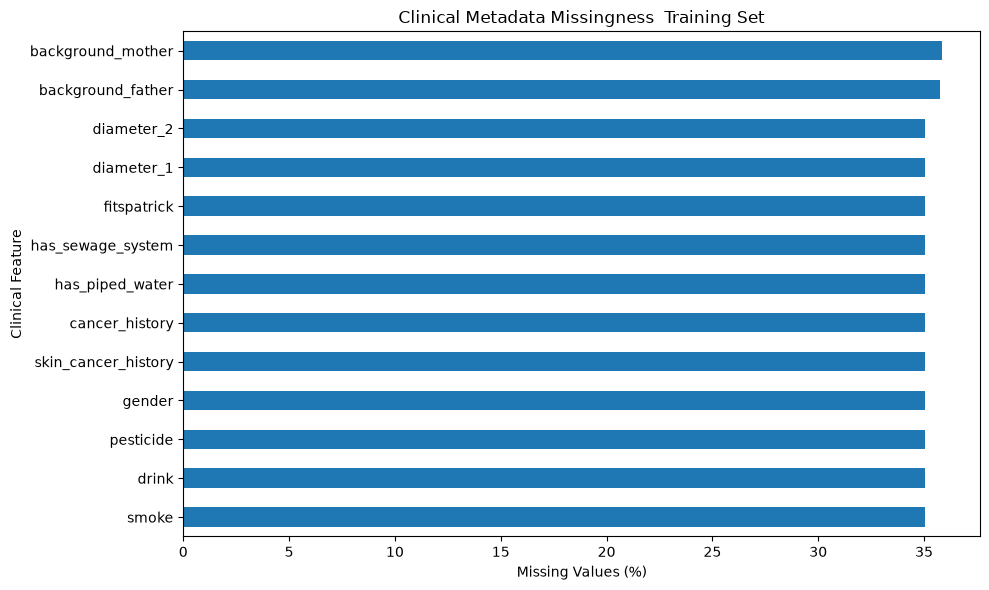


SECTION 3.2 COMPLETED SUCCESSFULLY


In [9]:
#Section 3.2  Clinical metadata missingness

excluded_columns = { "patient_id","lesion_id","img_id","diagnostic","split"}

metadata_columns= [
    col for col in train_df.columns
    if col not in excluded_columns
]

missing_summary= pd.DataFrame({
    "Missing Count": (
        train_df[metadata_columns].isna().sum()
    ),
    "Missing Percentage (%)": (
        train_df[metadata_columns].isna().mean() * 100
    ).round(2)
})

missing_summary= missing_summary[
    missing_summary["Missing Count"] > 0
].sort_values(
    "Missing Percentage (%)",
    ascending=False
)

print("TRAINING METADATA MISSINGNESS")

display(missing_summary)

print("\nFeatures with missing values:",len(missing_summary))

#Visualise missingness
fig,ax= plt.subplots(figsize=(10, 6))

missing_summary[
    "Missing Percentage (%)"
].sort_values().plot(
    kind="barh",
    ax=ax
)

ax.set_title("Clinical Metadata Missingness  Training Set")
ax.set_xlabel("Missing Values (%)")
ax.set_ylabel("Clinical Feature")

plt.tight_layout()
plt.show()

print("\nSECTION 3.2 COMPLETED SUCCESSFULLY")

### 3.3 Interpretation of Image Integrity and Metadata Quality

Image integrity assesssment was successfull in matching all 2,298 clincal images with their respective metadata. There were no instances of duplicate filenames, missing images or unreadable images files were identified.

Image dimensions varied greatly as the widths of images ranged from 147 to 3,474 pixels and heights ranged feom 147 to 3,476 pixels. There were 1,440 RGBA images and 858 RGB images. These dimensional variations show the importance of standardizing images before feature extraction by RGB conversion, resizing and normalization.

Training metadata assessment showed that there were 13 attributes with missing values. Eleven clinical variables each contained 575  missing records (35.06%) while parental background attributes had slightly higher missingness of 35.73% and 35.85%.

Identical missingness frequencies across multiple variables suggest a shared data-collection pattern. This may introduce dataset-specific prediction shortcuts if missingness is assosciared with diagnosis or clinical procedures.

Therefore, further analaysis will focus on the relation between missingness and diagnosis. Metadata feature selction will prioritise variables with reliable availability while retaining clincally meaningful information.

These checks establish file integrity and basic structural consistency but do not establish clinical image quality or freedom from dataset bias.


## 4. Missingness Bias Investigation and Metadata Feature Selection

### 4.1 Objective

The previous analysis highlighted the presence of many missing observations for 13 clinical metadata attributes. Some of the variables had similar frequency of missing values thus suggesting that there was a certain system of collecting data.

In this part, we investigate the relationship between the presence of missing clinical data with diagnostic categories and biopsy status. These assosciations can potentially cause shortcut learning where the model exploits missingness patterns rather than meaningful clinical characteristics.

Analysis is conducted using the training partition to inform feature selection withput using the reserved  test set.

### 4.2 Investigation Strategy

Three analyses are performed:
    1. Examine whether clinical metadata fields are missing together.
    2. Compare missingness rate across diagnostic categories and biopsy status
    3. Identify a conservative set of metadata features for subsequent modelling.

The selected features will be applied consistently to metadata-only and multimodal fusion models to ensure fair comparisons.    

In [10]:
# Section 4.1  Systematic clinical missingness
systematic_columns= [
    "smoke",
    "drink",
    "pesticide",
    "gender",
    "skin_cancer_history",
    "cancer_history",
    "has_piped_water",
    "has_sewage_system",
    "fitspatrick",
    "diameter_1",
    "diameter_2"
]

#Confirm required columns exist
assert set(systematic_columns).issubset(train_df.columns)

#Identify rows where all selected clinical fields are missing
all_clinical_missing= (train_df[systematic_columns].isna().all(axis=1))

#Identify rows with some, but not all, fields missing
partial_clinical_missing= (
    train_df[systematic_columns].isna().any(axis=1)
    & ~all_clinical_missing
)

print("SYSTEMATIC CLINICAL MISSINGNESS")

print("Training records:", len(train_df))
print("All selected clinical fields missing:",all_clinical_missing.sum())
print("Partially missing clinical fields:",partial_clinical_missing.sum())
print("All-missing percentage:",round(all_clinical_missing.mean() * 100, 2))

#Missingness by diagnosis
diagnosis_missingness= pd.crosstab(
    train_df["diagnostic"],
    all_clinical_missing,
    normalize="index"
).mul(100).round(2)

diagnosis_missingness= diagnosis_missingness.reindex(CLASSES)

diagnosis_missingness.columns= ["Clinical Data Available (%)","All Clinical Data Missing (%)"]

print("\nMissingness by diagnosis:")
display(diagnosis_missingness)

#Relationship with biopsy status
print("\nMissingness by biopsy status:")
display(
    pd.crosstab(
        train_df["biopsed"],
        all_clinical_missing,
        margins=True
    )
)

SYSTEMATIC CLINICAL MISSINGNESS
Training records: 1640
All selected clinical fields missing: 575
Partially missing clinical fields: 0
All-missing percentage: 35.06

Missingness by diagnosis:


,Clinical Data Available (%),All Clinical Data Missing (%)
diagnostic,,
ACK,39.27,60.73
BCC,100.00,0.00
MEL,100.00,0.00
NEV,30.46,69.54
SCC,100.00,0.00
SEK,18.45,81.55



Missingness by biopsy status:


col_0,False,True,All
biopsed,,,
False,101,575,676
True,964,0,964
All,1065,575,1640


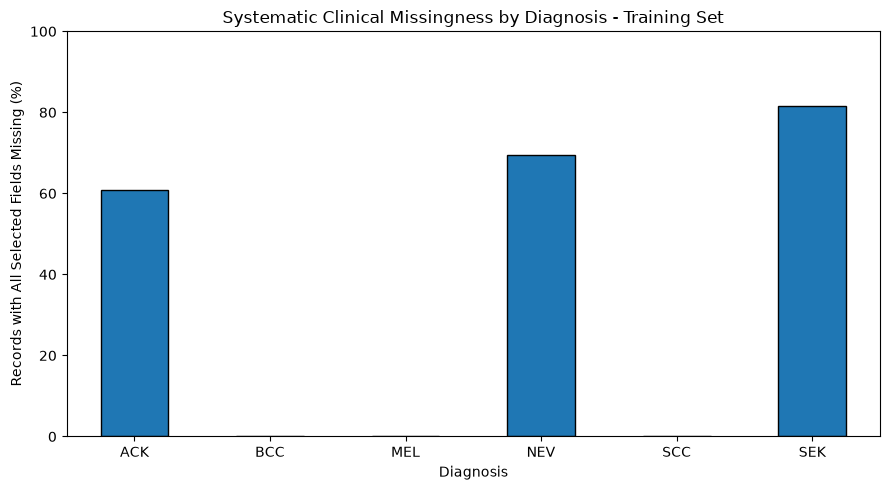

In [11]:
#Section 4.2 Visualise missingness across diagnosis groups

ax= diagnosis_missingness[
"All Clinical Data Missing (%)"
].plot(
    kind= "bar",
    figsize=(9,5),
    edgecolor="black"
)

ax.set_title("Systematic Clinical Missingness by Diagnosis - Training Set")
ax.set_xlabel("Diagnosis")
ax.set_ylabel("Records with All Selected Fields Missing (%)")
ax.set_ylim(0,100)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 4.3 Interpretation of Systematic Missingness and Bias

From the analysis of training set it was discovered that there were 575 records (35.06%) where all 11 chosen clinical variables were simultaneously missing. None of the records had partial missing data across these fields indicating a structured rather than independent missing-data pattern.

Missingness varied substantially by diagnosis. It occured in 81.5% of seborrheic keratosis (SEK) records, 69.54% of melanocytic nevus (NEV) records and 60.73% of actinic keratosis (ACK) recors. In contrary, no basal cell carcinoma (BCC), melanoma (MEL) or squamous cell carcinoma (SCC) records exhibited this missingness pattern.

Missinngness was also assosciated with the biopsy status. All 575 fully missing records were non-biopsied whereas all 964 biopsied records had the selected clinical information available. However, 101 non-biopsied records also contained this information.

This suggests that a model trained with these variables or their indicators for  missingness can take advantage of patterns in diagnosis-related documentraion rather than clinical features. Consequently, feature selection and modality ablation are needed to test any possibility of shortcut learning.

The metadata-based model will priortise consistently available variables, whereas the limitations of the dataset's diagnostic and biopsy related recording patterns will be explicitly discussed.

These results show a assosciation between clinical metadata missingess, diagnosis and biopsy status but they do not establish a causal relationship. Additionally, excluding systematically missing attributes may reduce risk of missingnesss-related shortcut learning but cannot eliminate other potential sources of dataset bias. 


## 5. Metadata Feature Selection and Preprocessing

### 5.1 Feature Selection

Primary metadata feature set consists of six attributes such as: age, lesion region, itching pain, bleeding and elevation.

These features were selected because they were consistently available in initial dataset analysis and provide potenitally relevant patient and lesion characteristics.

Variables with extensive systematic missingness, including biopsy-related clinical documentiation fields are excluded from the primary model to reduce the possibiltiy of shortcut learning.

The selected features include:
- Numerical: `age`
- Categorical: `region`, `itch`, `hurt`, `bleed`, `elevation`

The `UNK` category is retained as an explicit categorical value rather than silently interpreted as `False`. This preserves the distinction between an unknown response and a negative clinical response.

### 5.2 Preprocessing Strategy

Age is being standardised using statistics fitted on the training partition.

Categorical variables are one-hot encoded, with unseen categories ignored during transformation.

All preprocessing transformations are fitted exclusively on training data, preventing validation and test information from influencing model-development pipeline.

Same processed metadata will be used consistently in the metadata-only baseline and all multimodal fusion models.


In [12]:
# Section 5.1  Primary metadata feature selection

FINAL_METADATA_COLS= ["age","region","itch","hurt", "bleed","elevation"]

NUMERIC_FEATURES= ["age"]

CATEGORICAL_FEATURES= ["region","itch","hurt","bleed", "elevation"]

#Verify that all required features exist
assert set(FINAL_METADATA_COLS).issubset(
    train_df.columns
), "Required metadata features are missing."

print("PRIMARY METADATA FEATURE SELECTION")

print("Selected features:", FINAL_METADATA_COLS)

for name, partition in [("Training", train_df), ("Validation", val_df),("Test", test_df)]:
    print(
        f"\n{name}: {partition[FINAL_METADATA_COLS].shape}"
    )

#Inspect completeness using training data
print("\nTraining missing-value counts:")
display(train_df[FINAL_METADATA_COLS].isna().sum())

#Inspect categorical values
print("\nCategorical feature values:")

for column in CATEGORICAL_FEATURES:
    print(f"\n{column}:")
    print(train_df[column] .astype("string").value_counts(dropna=False))

print("\nSECTION 5.1 COMPLETED SUCCESSFULLY")

PRIMARY METADATA FEATURE SELECTION
Selected features: ['age', 'region', 'itch', 'hurt', 'bleed', 'elevation']

Training: (1640, 6)

Validation: (329, 6)

Test: (329, 6)

Training missing-value counts:


age          0
region       0
itch         0
hurt         0
bleed        0
elevation    0
dtype: int64


Categorical feature values:

region:
region
FACE       405
FOREARM    307
CHEST      198
BACK       178
ARM        131
NOSE       105
HAND        94
THIGH       56
NECK        55
EAR         48
ABDOMEN     27
SCALP       14
LIP         14
FOOT         8
Name: count, dtype: Int64

itch:
itch
True     1055
False     581
UNK         4
Name: count, dtype: Int64

hurt:
hurt
False    1334
True      299
UNK         7
Name: count, dtype: Int64

bleed:
bleed
False    1203
True      433
UNK         4
Name: count, dtype: Int64

elevation:
elevation
True     1037
False     601
UNK         2
Name: count, dtype: Int64

SECTION 5.1 COMPLETED SUCCESSFULLY


In [13]:
#Section 5.2  Training-only metadata preprocessing

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import numpy as np

metadata_preprocessor= ColumnTransformer(
    transformers= [
        (
            "age_scaler",
            StandardScaler(),
            NUMERIC_FEATURES
        ),
        (
            "categorical_encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            CATEGORICAL_FEATURES
        )
    ],
    remainder="drop",
    sparse_threshold=0
)

#Prepare feature inputs
X_train_meta_raw= train_df[FINAL_METADATA_COLS].copy()
X_val_meta_raw= val_df[FINAL_METADATA_COLS].copy()

#Fit using training records only
X_train_meta= metadata_preprocessor.fit_transform( X_train_meta_raw)

#Transform validation using the fitted pipeline
X_val_meta= metadata_preprocessor.transform( X_val_meta_raw)

#Ensure outputs are numerical arrays
X_train_meta= np.asarray(X_train_meta,dtype=np.float32)

X_val_meta= np.asarray( X_val_meta,dtype=np.float32)

#Check transformed outputs
assert X_train_meta.shape[1]== X_val_meta.shape[1]
assert np.isfinite(X_train_meta).all()
assert np.isfinite(X_val_meta).all()

print("METADATA PREPROCESSING RESULTS")


print("Training feature matrix:",X_train_meta.shape)
print("Validation feature matrix:",X_val_meta.shape)

print("\nEncoded feature count:",X_train_meta.shape[1])

print("\nAll transformed values are finite.")

print("\nFirst five encoded feature names:")
print(metadata_preprocessor.get_feature_names_out()[:5])

print("\nSECTION 5.2 COMPLETED SUCCESSFULLY")

METADATA PREPROCESSING RESULTS
Training feature matrix: (1640, 27)
Validation feature matrix: (329, 27)

Encoded feature count: 27

All transformed values are finite.

First five encoded feature names:
['age_scaler__age' 'categorical_encoder__region_ABDOMEN'
 'categorical_encoder__region_ARM' 'categorical_encoder__region_BACK'
 'categorical_encoder__region_CHEST']

SECTION 5.2 COMPLETED SUCCESSFULLY


In [14]:
#Section 5.3  Validate transformed metadata

print("METADATA PREPROCESSING VALIDATION")

print("Age mean after training standardisation:",round(float(X_train_meta[:, 0].mean()), 6))

print("Age standard deviation after scaling:", round(float(X_train_meta[:, 0].std()), 6))



#Verify identical feature dimensions
assert X_train_meta.shape[1]== X_val_meta.shape[1]

#Verify no NaN or infinite values
assert np.isfinite(X_train_meta).all()
assert np.isfinite(X_val_meta).all()

#Age standardisation checks
assert abs(X_train_meta[:, 0].mean())<1e-5
assert abs(X_train_meta[:, 0].std()-1.0)<1e-4

print("\nAll preprocessing validation checks PASSED.")

METADATA PREPROCESSING VALIDATION
Age mean after training standardisation: 0.0
Age standard deviation after scaling: 1.0

All preprocessing validation checks PASSED.


## 5.4 Interpretation of Metadata Preprocessing

Six consitently available clinical variables were retained: age, lesion region, itching, pain, bleeding and elevation. Where these features exclude attributes with substantial systematic missingness identified in Section 4.

Training-only standardisation and one-hot encoding converted the six original variables into 27 numerical features. Where resulting training and validation matrices contained 1,640 and 329 records respectively with identical feature dimensions and no missing or non-finite values.

Standardised training attribute age had a mean of approximately zero and a standard deviation of one. Categorical encoder treated unkown clinical responses as a separate categories rather than treating them as negative observations.

This demonstrates that the input metadata is numerically appropriate for further classification and fusion tasks. However, complete fields and valid numerical representations do not guarantee that selected features are free from confounding or dataset-specific shortcuts.

## 6. Unimodal Baseline Models

### 6.1 Metadata-Only Logistic Regression

A metadata-only logistic regression classifier is trained using 27-dimensional processsed feature representation.

Model uses class-balanced weighting to account for diagnostic class imbalance. Its performance is evaluated on patient-disjoint validation partition usinf accuracy, balanced accuracy, macro-F1, per-class precision and recall and a confusion matrix.

This baseline establishes the predictive contribution of structured patient metadata before multimodal fusion. Model selection and development will use training and validation data only the test partition remains reserved for the final evaluation

METADATA-ONLY BASELINE RESULTS
Accuracy:0.5745
Balanced Accuracy: 0.6442
Macro-F1:0.5252
Training Time:0.0416 seconds

Classification Report:
              precision    recall  f1-score   support

         ACK     0.8769    0.5481    0.6746       104
         BCC     0.7976    0.5537    0.6537       121
         MEL     0.2353    1.0000    0.3810         8
         NEV     0.6667    0.7429    0.7027        35
         SCC     0.2941    0.5357    0.3797        28
         SEK     0.2857    0.4848    0.3596        33

    accuracy                         0.5745       329
   macro avg     0.5261    0.6442    0.5252       329
weighted avg     0.7009    0.5745    0.6060       329


Probability validation PASSED.


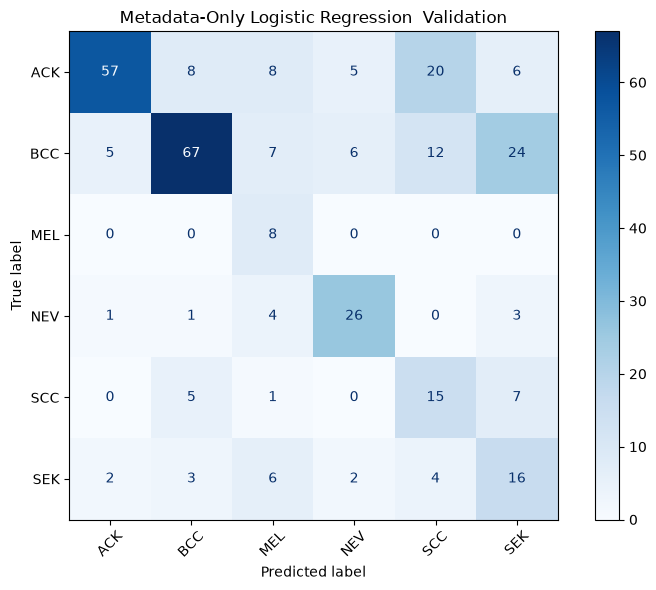


SECTION 6.1 COMPLETED SUCCESSFULLY


In [15]:
#Section 6.1  Metadata-only classification baseline

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,balanced_accuracy_score,f1_score,classification_report,ConfusionMatrixDisplay

import time

#Target labels
y_train= train_df["diagnostic"].to_numpy()
y_val= val_df["diagnostic"].to_numpy()

#Train using processed metadata features
metadata_model= LogisticRegression(max_iter=3000,class_weight="balanced",random_state=SEED)

start_time= time.perf_counter()

metadata_model.fit(X_train_meta,y_train)

metadata_training_time= (time.perf_counter() - start_time)

#Validation predictions
val_meta_pred= metadata_model.predict(X_val_meta)

val_meta_prob= metadata_model.predict_proba(X_val_meta)

#Calculate evaluation metrics
metadata_accuracy= accuracy_score(y_val, val_meta_pred)

metadata_balanced_accuracy= balanced_accuracy_score( y_val, val_meta_pred)

metadata_macro_f1= f1_score(y_val,val_meta_pred, average="macro")

print("METADATA-ONLY BASELINE RESULTS")


print(f"Accuracy:{metadata_accuracy:.4f}")
print(f"Balanced Accuracy: "f"{metadata_balanced_accuracy:.4f}")
print(f"Macro-F1:{metadata_macro_f1:.4f}")
print(f"Training Time:" f"{metadata_training_time:.4f} seconds")

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        val_meta_pred,
        labels=CLASSES,
        digits=4,
        zero_division=0
    )
)

#Confirm predicted probabilities are valid
assert np.isfinite(val_meta_prob).all()

assert np.allclose(val_meta_prob.sum(axis=1),1.0)

print("\nProbability validation PASSED.")

#Plot confusion matrix
fig,ax= plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_meta_pred,
    labels=CLASSES,
    ax=ax,
    cmap="Blues",
    xticks_rotation=45
)

ax.set_title(  "Metadata-Only Logistic Regression  Validation")

plt.tight_layout()
plt.show()

print("\nSECTION 6.1 COMPLETED SUCCESSFULLY")

## 6.1 Interpretation of Metadata-Only Classification

The metadata-only logistic regression model achieved 57.45% accuracy, 64.42% balanced accuracy and a macro-F1 score of 0.5252 on the patient-disjoint validation partition. These results reproduce the preliminary findings from Project 2.1.

Performance varied substantially across diagnostic categories. The highest F1-score was obtained for melanocytic nevus (NEV, 0.7027), while squamous cell carcinoma (SCC, 0.3797) and seborrheic keratosis (SEK, 0.3596) showed weaker classification performance.

The model correctly identified all eight validation melanoma cases, achieving 100% recall. However, melanoma precision was only 23.53%, indicating substantial false-positive predictions. Moreover, the very small melanoma sample means this recall estimate is highly uncertain.

The confusion matrix also revealed misclassification between ACK and SCC, and between BCC and SEK.

These findings establish a reproducible metadata-only baseline against which image-only and multimodal fusion approaches can be compared. The model demonstrates predictive signal in the structured clinical attributes, but its errors and potential dataset-specific biases prevent interpreting these results as evidence of clinical readiness.


## 6.2 Image-Only Baseline: EfficientNet-B0

Pretrained EfficientNet-B0 convolutional neural network is used to extract visual representations from skin-lesion photographs.

Input images are first coverted into RGB format, resized to 224 x 224 dimensions and normalized using ImageNet statistics. Pretrained features extraction layer reains frozen during the training process to lower the computing costs and provide reproducibility of visual baseline.

Network produces 1,280 dimensional image embeddings. These representations will be used to train an image-only classifier and subsequently evaluate multimodal fusion strategies.

Training and validation images only are passed through the model during its developemnt process, whereas test set is left aside for the final evaluation step.


In [16]:
#Section 6.2.1 — Image preprocessing and dataset creation

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

#Standard input transformation for EfficientNet-B0
image_transform= transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

CLASS_TO_IDX= {cls: idx for idx, cls in enumerate(CLASSES)}

class SkinLesionDataset(Dataset):
    def __init__(self, dataframe, image_paths, transform):
        self.data= dataframe.reset_index(drop=True)
        self.image_paths= image_paths
        self.transform= transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        row= self.data.iloc[index]
        path= self.image_paths[row["img_id"]]

        with Image.open(path) as img:
            #Composite transparent images consistently
            rgba= img.convert("RGBA")
            background= Image.new(
                "RGBA", rgba.size, (255, 255, 255, 255)
            )
            image= Image.alpha_composite(
                background, rgba
            ).convert("RGB")

        image= self.transform(image)
        label= CLASS_TO_IDX[row["diagnostic"]]

        return image, label

train_image_dataset= SkinLesionDataset(
    train_df, image_paths, image_transform
)

val_image_dataset= SkinLesionDataset(
    val_df, image_paths, image_transform
)

train_image_loader= DataLoader(
    train_image_dataset,
    batch_size= 16,
    shuffle= False,
    num_workers= 0
)

val_image_loader= DataLoader(
    val_image_dataset,
    batch_size= 16,
    shuffle= False,
    num_workers= 0
)

print("IMAGE DATASET PREPARATION")

print("Training images:",len(train_image_dataset))
print("Validation images:",len(val_image_dataset))
print("Class mapping:",CLASS_TO_IDX)

images,labels= next(iter(train_image_loader))

print("\nImage batch shape:",images.shape)
print("Label batch shape:",labels.shape)
print("Image dtype:",images.dtype)

assert images.shape== (16, 3, 224, 224)
assert torch.isfinite(images).all()

print("\nSECTION 6.2.1 COMPLETED SUCCESSFULLY")

IMAGE DATASET PREPARATION
Training images: 1640
Validation images: 329
Class mapping: {'ACK': 0, 'BCC': 1, 'MEL': 2, 'NEV': 3, 'SCC': 4, 'SEK': 5}

Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Image dtype: torch.float32

SECTION 6.2.1 COMPLETED SUCCESSFULLY


## 6.2.1A Visual Inspection of Image Preprocessing

The representative training photographs from all the six diagnostic categories are displayed before and after the preprocessing. 

Where the Images are converted to rgb using a white background resized to 224 x 224 pixels and normalised using ImageNet statistics. The normalised tensors are inverse-normalised solely for visual inspection.

This comparison illustrates the changes in the image dimensions and appearance but it does not establish clinical image quality or model robustness.

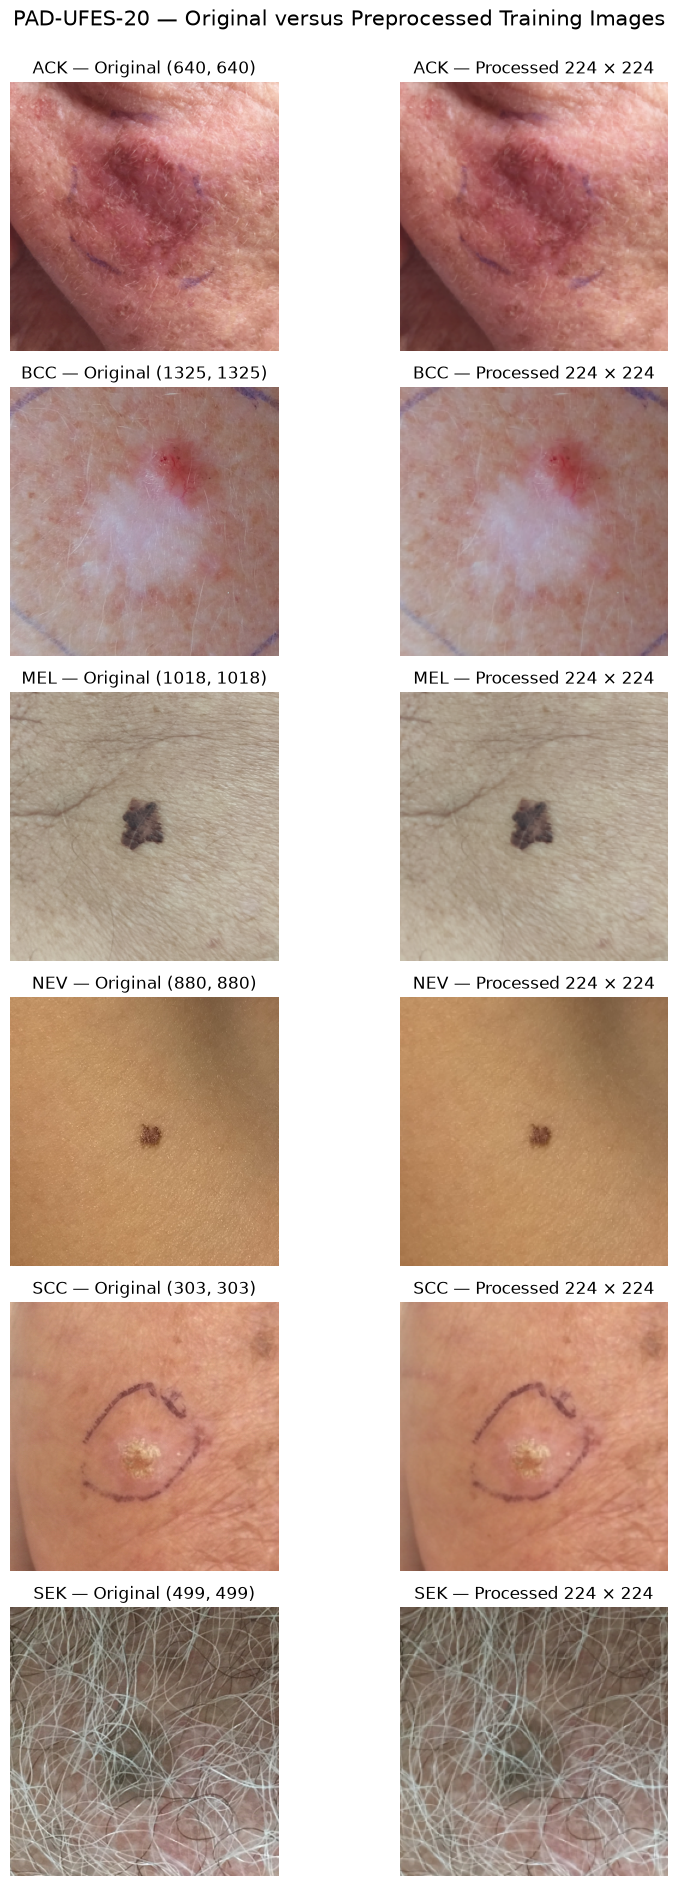

Six diagnostic classes visualised.
Only training images were used.
Image saved: /Users/avinashmonteiro/Desktop/PAD_UFES20_Project/preprocessing_before_after.png
SECTION 6.2.1A COMPLETED SUCCESSFULLY


In [17]:
#Section 6.2.1A  Before-and-after image preprocessing
#Uses training images only; no test images or model changes.

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

mean_rgb= np.array([0.485, 0.456, 0.406])
std_rgb= np.array([0.229, 0.224, 0.225])

fig, axes= plt.subplots(len(CLASSES), 2,figsize=(9, 3.2 * len(CLASSES)))

for row_idx,diagnosis in enumerate(CLASSES):
    sample_idx= train_df.index[
        train_df["diagnostic"]== diagnosis
    ][0]

    sample= train_df.loc[sample_idx]
    image_path= image_paths[sample["img_id"]]

    #Original image, with transparency composited to white.
    with Image.open(image_path) as original:
        rgba= original.convert("RGBA")
        background= Image.new(
            "RGBA", rgba.size, (255, 255, 255, 255)
        )
        original_rgb= Image.alpha_composite(
            background, rgba
        ).convert("RGB")

    original_size= original_rgb.size

    #Apply the EXACT original notebook transformation.
    processed_tensor= image_transform(original_rgb)

    assert processed_tensor.shape== (3, 224, 224)
    assert torch.isfinite(processed_tensor).all()

    #Inverse-normalise for display only.
    displayed_image= (
        processed_tensor.permute(1, 2, 0).numpy()
        * std_rgb + mean_rgb
    )

    displayed_image= np.clip(displayed_image, 0, 1)

    axes[row_idx, 0].imshow(original_rgb)
    axes[row_idx, 0].set_title(
        f"{diagnosis} — Original {original_size}"
    )

    axes[row_idx, 1].imshow(displayed_image)
    axes[row_idx, 1].set_title(
        f"{diagnosis} — Processed 224 × 224"
    )

    for ax in axes[row_idx]:
        ax.axis("off")

fig.suptitle(
    "PAD-UFES-20 — Original versus Preprocessed Training Images",
    fontsize=15
)

plt.tight_layout(rect=[0, 0, 1, 0.98])

visual_path= (PROJECT_DIR /"preprocessing_before_after.png")
fig.savefig(visual_path, dpi=200, bbox_inches="tight")

plt.show()

print("Six diagnostic classes visualised.")
print("Only training images were used.")
print("Image saved:",visual_path)
print("SECTION 6.2.1A COMPLETED SUCCESSFULLY")

In [18]:
#Section 6.2.2  Initialise pretrained feature extractor

import torch.nn as nn
from torchvision.models import efficientnet_b0,EfficientNet_B0_Weights

weights= EfficientNet_B0_Weights.DEFAULT

backbone= efficientnet_b0(weights=weights)

#Retain convolutional features and global average pooling
feature_extractor= nn.Sequential( backbone.features, backbone.avgpool,nn.Flatten(1))

#Freeze pretrained parameters
for parameter in feature_extractor.parameters():
    parameter.requires_grad= False

feature_extractor= feature_extractor.to(DEVICE)
feature_extractor.eval()

#Verify one batch on the selected device
with torch.inference_mode():
    batch_features= feature_extractor(
        images.to(DEVICE)
    )

print("EFFICIENTNET-B0 FEATURE EXTRACTION")

print("Selected device:",DEVICE)
print("Input batch:",images.shape)
print("Feature batch:",batch_features.shape)
print("Feature dtype:",batch_features.dtype)

assert batch_features.shape== (16, 1280)
assert torch.isfinite(batch_features).all()

print("\nSECTION 6.2.2 COMPLETED SUCCESSFULLY")

EFFICIENTNET-B0 FEATURE EXTRACTION
Selected device: mps
Input batch: torch.Size([16, 3, 224, 224])
Feature batch: torch.Size([16, 1280])
Feature dtype: torch.float32

SECTION 6.2.2 COMPLETED SUCCESSFULLY


## 6.2.3 Extraction of Visual Feature Representations

Pretrained Efficientnet-B0 network is used to extract the 1,280-dimensional visual feature vectors from each of the photograph.

The backbone remains frozen and operates in evaluation mode, allowing same pretrained representation to be generated consistently for each image.

Feature extraction is  performed independently on training and validation partitions. DataLoader shuffling is disabled to preserve original record order and maintain accurate alignment between image features, clinical metadata and diagnosis labels.

The extracted representations will be reused for image-only classifier and subsequent multimodal fusion experiments reducing redundant computation.

In [19]:
#Section 6.2.3  Extract EfficientNet-B0 image features

import time
import numpy as np

def extract_image_features(loader, model, device):
    """
    Extract frozen CNN features while preserving
    DataLoader ordering and corresponding labels.
    """
    all_features= []
    all_labels= []

    model.eval()

    with torch.inference_mode():
        for batch_images, batch_labels in loader:

            batch_images= batch_images.to(device)

            features= model(batch_images)

            all_features.append(features.cpu().numpy())

            all_labels.append(batch_labels.numpy())

    return (
        np.concatenate(all_features, axis=0),
        np.concatenate(all_labels, axis=0)
    )


start_time= time.perf_counter()

X_train_img, y_train_img= extract_image_features(train_image_loader,feature_extractor,DEVICE)

X_val_img, y_val_img= extract_image_features(val_image_loader,feature_extractor,DEVICE)

feature_extraction_time= (time.perf_counter()-start_time)

#Confirm expected dimensions
assert X_train_img.shape== (1640, 1280)
assert X_val_img.shape== (329, 1280)

assert np.isfinite(X_train_img).all()
assert np.isfinite(X_val_img).all()

#Verify image labels agree with metadata row ordering
assert np.array_equal(y_train_img,train_df["diagnostic"].map(CLASS_TO_IDX).to_numpy())

assert np.array_equal(y_val_img,val_df["diagnostic"].map(CLASS_TO_IDX).to_numpy())

print("IMAGE FEATURE EXTRACTION RESULTS")

print("Training features:", X_train_img.shape)
print("Validation features:", X_val_img.shape)

print("Training labels:", y_train_img.shape)
print("Validation labels:", y_val_img.shape)

print(f"\nFeature extraction time: "f"{feature_extraction_time:.2f} seconds")

print("\nImage–metadata alignment verified.")
print("All extracted features are finite.")

print("\nSECTION 6.2.3 COMPLETED SUCCESSFULLY")

IMAGE FEATURE EXTRACTION RESULTS
Training features: (1640, 1280)
Validation features: (329, 1280)
Training labels: (1640,)
Validation labels: (329,)

Feature extraction time: 50.59 seconds

Image–metadata alignment verified.
All extracted features are finite.

SECTION 6.2.3 COMPLETED SUCCESSFULLY


In [20]:
#Section 6.2.4  Cache extracted image features

OUTPUT_DIR= PROJECT_DIR / "project2_2_outputs"
OUTPUT_DIR.mkdir(parents= True, exist_ok= True)

feature_cache_path= (OUTPUT_DIR / "efficientnet_b0_train_val_features.npz")

np.savez_compressed(
    feature_cache_path,
    X_train_img= X_train_img,
    y_train_img= y_train_img,
    X_val_img= X_val_img,
    y_val_img= y_val_img,
    train_img_ids= train_df["img_id"].to_numpy(),
    val_img_ids= val_df["img_id"].to_numpy()
)

print("Image embeddings saved successfully.")
print("File:",feature_cache_path)
print("Training features:",X_train_img.shape)
print("Validation features:",X_val_img.shape)

Image embeddings saved successfully.
File: /Users/avinashmonteiro/Desktop/PAD_UFES20_Project/project2_2_outputs/efficientnet_b0_train_val_features.npz
Training features: (1640, 1280)
Validation features: (329, 1280)


IMAGE-ONLY BASELINE RESULTS
Accuracy:0.5289
Balanced Accuracy:0.4172
Macro-F1:0.4221
Classifier training time: 0.29 seconds

Classification Report:
              precision    recall  f1-score   support

         ACK     0.5952    0.7212    0.6522       104
         BCC     0.6262    0.5537    0.5877       121
         MEL     0.5000    0.3750    0.4286         8
         NEV     0.5294    0.5143    0.5217        35
         SCC     0.0435    0.0357    0.0392        28
         SEK     0.3030    0.3030    0.3030        33

    accuracy                         0.5289       329
   macro avg     0.4329    0.4172    0.4221       329
weighted avg     0.5210    0.5289    0.5220       329



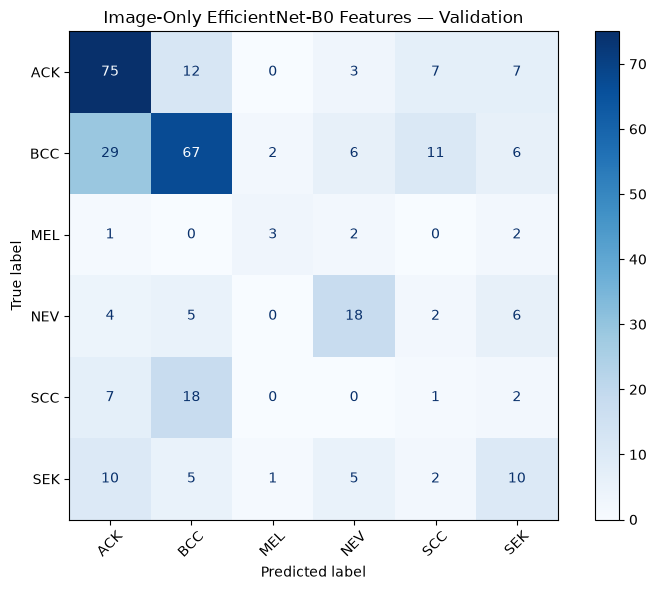


SECTION 6.2 COMPLETED SUCCESSFULLY


In [21]:
#Section 6.2.5  Image-only classification baseline

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,balanced_accuracy_score,f1_score,classification_report,ConfusionMatrixDisplay


image_model= Pipeline([
    (
        "scaler",
        StandardScaler()
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=SEED
        )
    )
])

start_time= time.perf_counter()

image_model.fit(X_train_img,y_train_img)

image_training_time= (time.perf_counter() - start_time)

val_img_pred_indices= image_model.predict(X_val_img)

val_img_prob= image_model.predict_proba(X_val_img)

#Convert numeric labels back to diagnosis categories
val_img_pred= np.array([
    CLASSES[index]
    for index in val_img_pred_indices
])

val_img_actual= np.array([
    CLASSES[index]
    for index in y_val_img
])

image_accuracy= accuracy_score(val_img_actual,val_img_pred)

image_balanced_accuracy= balanced_accuracy_score(val_img_actual,val_img_pred)

image_macro_f1= f1_score(val_img_actual,val_img_pred,labels=CLASSES,average="macro",zero_division=0)

assert np.isfinite(val_img_prob).all()

assert np.allclose(val_img_prob.sum(axis=1),1.0)

print("IMAGE-ONLY BASELINE RESULTS")


print(f"Accuracy:{image_accuracy:.4f}")
print(
    f"Balanced Accuracy:"f"{image_balanced_accuracy:.4f}"
)
print(f"Macro-F1:{image_macro_f1:.4f}")
print(f"Classifier training time: " f"{image_training_time:.2f} seconds")
print("\nClassification Report:")
print(
    classification_report(
        val_img_actual,
        val_img_pred,
        labels=CLASSES,
        digits=4,
        zero_division=0
    )
)

fig,ax= plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    val_img_actual,
    val_img_pred,
    labels=CLASSES,
    ax=ax,
    cmap="Blues",
    xticks_rotation=45
)

ax.set_title("Image-Only EfficientNet-B0 Features — Validation")

plt.tight_layout()
plt.show()

print("\nSECTION 6.2 COMPLETED SUCCESSFULLY")

### 6.2.5A Image-Only Regularisation Sensitivity Analysis

This supplementary experiment examines whether logistic-regression regularisation affects overfitting when using frozen EfficientNet-B0 image embeddings. Six regularisation strengths are compared using training and validation macro-F1. The original image-only baseline remains unchanged and the held-out test partition is not accessed.

Because the same validation partition is used to compare configurations the results are exploratory rather than independent generalisation estimates.

IMAGE-ONLY REGULARISATION SENSITIVITY


,C,Train Macro-F1,Validation Macro-F1,Generalisation Gap
0,0.0001,0.5955,0.4794,0.1161
1,0.0010,0.7954,0.4998,0.2956
2,0.0100,0.9656,0.5166,0.4490
3,0.1000,0.9937,0.4310,0.5627
4,1.0000,0.9949,0.4221,0.5728
5,10.0000,0.9949,0.4545,0.5404



Best exploratory C: 0.01
Best exploratory validation macro-F1: 0.5166


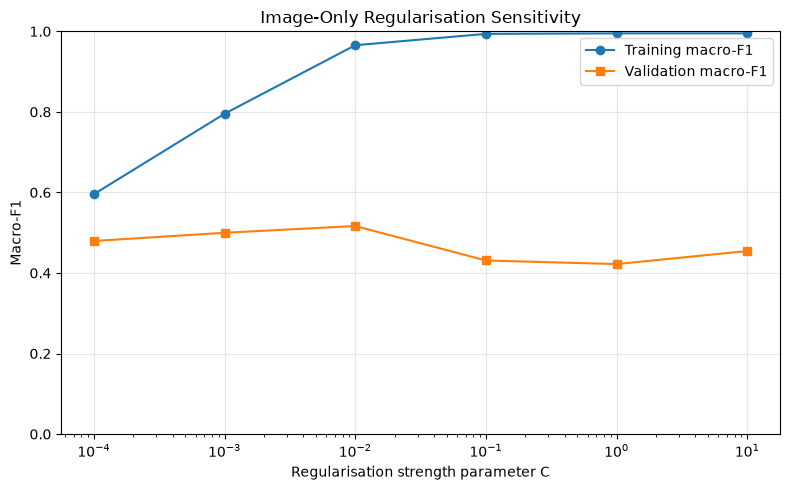


Original image-only model unchanged.
Held-out test data not used.


In [22]:
#Section 6.2.5A — Image-only regularisation sensitivity
#Supplementary analysis: no test-set access or model replacement.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

reg_c_values= [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0]
reg_results= []

for c_value in reg_c_values:

    reg_candidate= Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            C=c_value,
            max_iter=3000,
            class_weight="balanced",
            random_state=SEED
        ))
    ])

    reg_candidate.fit(X_train_img,y_train_img)

    reg_train_pred= reg_candidate.predict(X_train_img)
    reg_val_pred= reg_candidate.predict(X_val_img)

    train_f1= f1_score(
        y_train_img,
        reg_train_pred,
        labels= list(range(len(CLASSES))),
        average= "macro",
        zero_division= 0
    )

    val_f1= f1_score(
        y_val_img,
        reg_val_pred,
        labels=list(range(len(CLASSES))),
        average="macro",
        zero_division=0
    )

    reg_results.append({
        "C": c_value,
        "Train Macro-F1": train_f1,
        "Validation Macro-F1": val_f1,
        "Generalisation Gap": train_f1 - val_f1
    })

reg_df= pd.DataFrame(reg_results)

print("IMAGE-ONLY REGULARISATION SENSITIVITY")
display(reg_df.round(4))

best_reg_row= reg_df.loc[
    reg_df["Validation Macro-F1"].idxmax()
]

print("\nBest exploratory C:", best_reg_row["C"])
print("Best exploratory validation macro-F1:",round(best_reg_row["Validation Macro-F1"], 4))

#Confirm that C=1 reproduces the original image-only baseline.
reg_c1_f1= reg_df.loc[
    reg_df["C"]== 1.0, "Validation Macro-F1"
].iloc[0]

assert np.isclose(reg_c1_f1, image_macro_f1, atol=1e-4), (
    "C=1 result differs from the original baseline."
)

#Training-versus-validation visualisation
fig,ax= plt.subplots(figsize=(8, 5))

ax.semilogx(
    reg_df["C"],
    reg_df["Train Macro-F1"],
    marker="o",
    label="Training macro-F1"
)

ax.semilogx(
    reg_df["C"],
    reg_df["Validation Macro-F1"],
    marker="s",
    label="Validation macro-F1"
)

ax.set_xlabel("Regularisation strength parameter C")
ax.set_ylabel("Macro-F1")
ax.set_title("Image-Only Regularisation Sensitivity")
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

print("\nOriginal image-only model unchanged.")
print("Held-out test data not used.")

### 6.2.5A.1 Interpretation of Image-Only Regularisation Sensitivity

The exploratory analysis evaluated six regularisation configurations for the image-only logistic-regression classifier. The highest validation macro-F1 was 0.5166 at C = 0.01,compared with 0.4221 for the original baseline(C = 1).

At C = 1, training macro-F1 was 0.9949, whereas validation macro-F1 was 0.4221, producing a generalisation gap of 0.5728. At C = 0.01, this gap decreased to 0.4490, although considerable overfitting remained.

These results suggest that stronger regularisation can improve validation performance when classifying high-dimensional image embeddings. However, the findings are exploratory because all configurations were compared using the same validation partition.

The original image-only baseline, early-fusion classifier and held-out test results remained unchanged.

## 6.2.6 Interpretation of Image-Only Classification

Frozen EfficientNet-B0 feature extractor created 1,280-dimensional feature vectors for each of the 1,640 training and 329 validation images. Image features were extracted using Apple MPS acceleration. Execution time may vary depending on hardware and system conditions. Image-metadata allignment checks confirmed that extracted features corresponded to correct records and diagnostic labels. Each of the feature vectors is finite which allowed their use in image-only classification and multimodal fusion.

Image-only logistic regression classifier achieved 52.89% validation accuracy 41.72% balanced accuracy and a macro-F1 score of 0.4221. These results reproduced preliminary Project 2.1 image-onyl baseline.

Class-level results revealed considerable variation. Actinic keratosis (ACK) achieved 72.12% recall, whereas squamous cell carcinoma (SCC) achieved only 3.57% recall. Melanoma recall was 37.50%, corresponding to three correctly classified cases out of eight validation examples.

Compared with the metadata-only classifier (macro-F1 = 0.5252), the image-only model performed worse by 0.1031 macro-F1 points. This may reflect limitations of frozen generic visual features, class imbalance and variation in clinical image characteristics.

Findings motivate the multimodal fusion experiments to investigate whether integrating visual and clinical information improves classification over strongest unimodal baseline. Model remaisn a research prototype rather than a clinically validated diagnostic system.



## 7. Multimodal Fusion Models

### 7.1 Early Fusion: Feature-Level Integration

Fusion in the early phase takes place before classification on the representations of images and metadata.

The output of frozen EfficientNet-B0 encoder gives us 1,280 features from images and preprocessing of metadata leads to 27 structrued features. These two feature sets are merged based on image IDs and a feature vector of 1,307 dimesniosn is created.

To reduce risk of modality dominance, image and metadata feature blocsk are standarised separtely using the training data and scaled according to their dimensionality. This provides a simple, reproducible balancing strategy rather than allowing larger iamge feature block to dominate by construction.

A class-balanced logistic regression classifier is then trained on combined reprsentation and evlauated on patient-disjoint validation partition.

Modality blocks are divided by square root of their respective feature dimesnions to approximately normlaise their aggregate scale before the concatenation.

However, this is a fixed design choice rather than optimised weighting strategy. Under L2-regualrised logistic regression, feature rescaling also changes  effective regularisation applied to each modality. Section 7.6 subsequently examined sensitivity to modality-block scaling and logistic-regression regularisation across nine exploratory configurations.

In [23]:
#Section 7.1  Prepare early-fusion feature representations

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,balanced_accuracy_score,f1_score
import numpy as np

#Confirm row alignment before combining modalities
assert np.array_equal( y_train_img,train_df["diagnostic"].map(CLASS_TO_IDX).to_numpy())

assert np.array_equal(y_val_img,val_df["diagnostic"].map(CLASS_TO_IDX).to_numpy())

assert X_train_img.shape[0]== X_train_meta.shape[0]
assert X_val_img.shape[0]== X_val_meta.shape[0]

#Standardise image features using training statistics only
fusion_image_scaler= StandardScaler()

X_train_img_scaled= fusion_image_scaler.fit_transform(X_train_img)
X_val_img_scaled= fusion_image_scaler.transform(X_val_img)

#Metadata already uses train-fitted preprocessing.
#Standardise the encoded metadata block for fusion.
fusion_meta_scaler= StandardScaler()

X_train_meta_scaled= fusion_meta_scaler.fit_transform(X_train_meta)

X_val_meta_scaled= fusion_meta_scaler.transform(X_val_meta)

#Balance the blocks by dimensionality
image_dim= X_train_img_scaled.shape[1]
metadata_dim= X_train_meta_scaled.shape[1]

X_train_early= np.concatenate(
    [
        X_train_img_scaled / np.sqrt(image_dim),
        X_train_meta_scaled / np.sqrt(metadata_dim)
    ],
    axis= 1
)

X_val_early= np.concatenate(
    [
        X_val_img_scaled / np.sqrt(image_dim),
        X_val_meta_scaled / np.sqrt(metadata_dim)
    ],
    axis= 1
)

assert X_train_early.shape== (1640, 1307)
assert X_val_early.shape== (329, 1307)

assert np.isfinite(X_train_early).all()
assert np.isfinite(X_val_early).all()

print("EARLY FUSION FEATURE PREPARATION")
print("Image feature dimensions:", image_dim)
print("Metadata feature dimensions:", metadata_dim)
print("Combined training features:", X_train_early.shape)
print("Combined validation features:", X_val_early.shape)
print("\nAll fusion feature checks PASSED.")

EARLY FUSION FEATURE PREPARATION
Image feature dimensions: 1280
Metadata feature dimensions: 27
Combined training features: (1640, 1307)
Combined validation features: (329, 1307)

All fusion feature checks PASSED.


EARLY FUSION VALIDATION RESULTS
Accuracy:0.6991
Balanced Accuracy: 0.7131
Macro-F1:0.6681
Training time:0.0808 seconds

Classification Report:
              precision    recall  f1-score   support

         ACK     0.8421    0.7692    0.8040       104
         BCC     0.7959    0.6446    0.7123       121
         MEL     0.6364    0.8750    0.7368         8
         NEV     0.7436    0.8286    0.7838        35
         SCC     0.3023    0.4643    0.3662        28
         SEK     0.5349    0.6970    0.6053        33

    accuracy                         0.6991       329
   macro avg     0.6425    0.7131    0.6681       329
weighted avg     0.7329    0.6991    0.7093       329



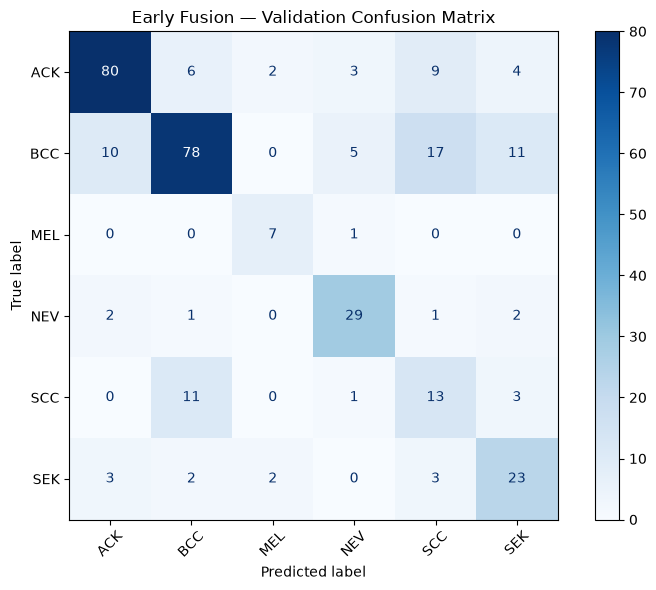


SECTION 7.2 COMPLETED SUCCESSFULLY


In [24]:
#Section 7.2  Train early-fusion classifier

import time
from sklearn.metrics import classification_report,ConfusionMatrixDisplay


early_fusion_model= LogisticRegression(max_iter= 3000,class_weight= "balanced",C= 1.0, random_state= SEED)

start_time= time.perf_counter()

early_fusion_model.fit(X_train_early,y_train)

early_training_time= time.perf_counter()-start_time

val_early_pred= early_fusion_model.predict(X_val_early)

val_early_prob= early_fusion_model.predict_proba( X_val_early)

early_accuracy= accuracy_score(y_val, val_early_pred)

early_balanced_accuracy= balanced_accuracy_score(y_val, val_early_pred)

early_macro_f1= f1_score(
    y_val,
    val_early_pred,
    labels=CLASSES,
    average= "macro",
    zero_division=0
)

assert np.isfinite(val_early_prob).all()
assert np.allclose(val_early_prob.sum(axis=1), 1.0)

print("EARLY FUSION VALIDATION RESULTS")

print(f"Accuracy:{early_accuracy:.4f}")
print(f"Balanced Accuracy: "f"{early_balanced_accuracy:.4f}")
print(f"Macro-F1:{early_macro_f1:.4f}")
print(f"Training time:{early_training_time:.4f} seconds")

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        val_early_pred,
        labels= CLASSES,
        digits= 4,
        zero_division= 0
    )
)

fig, ax= plt.subplots(figsize= (8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_early_pred,
    labels= CLASSES,
    ax= ax,
    cmap= "Blues",
    xticks_rotation= 45
)

ax.set_title("Early Fusion — Validation Confusion Matrix")
plt.tight_layout()
plt.show()
print("\nSECTION 7.2 COMPLETED SUCCESSFULLY")

INITIAL MODEL COMPARISON
---------------------------------------------


,Model,Accuracy,Balanced Accuracy,Macro-F1
0,Metadata-only,0.5745,0.6442,0.5252
1,Image-only,0.5289,0.4172,0.4221
2,Early Fusion,0.6991,0.7131,0.6681



Early fusion minus metadata-only macro-F1: 0.1429


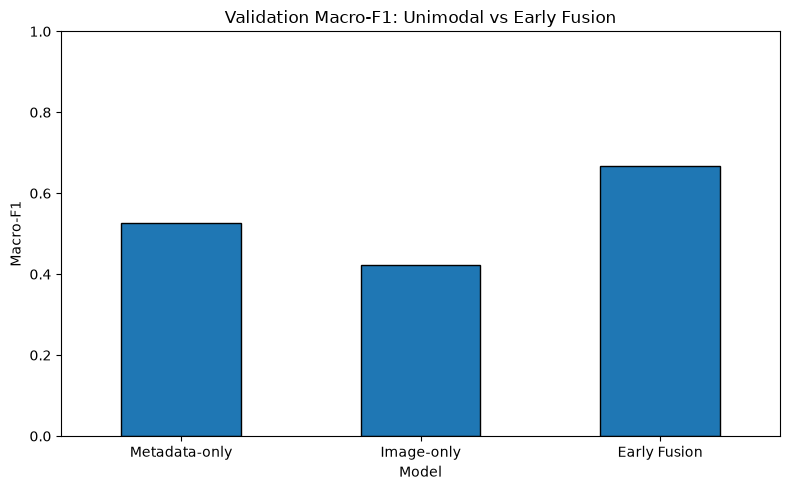

In [25]:
#Section 7.3  Initial model comparison

comparison_df= pd.DataFrame([
    {
        "Model": "Metadata-only",
        "Accuracy": metadata_accuracy,
        "Balanced Accuracy": metadata_balanced_accuracy,
        "Macro-F1": metadata_macro_f1
    },
    {
        "Model": "Image-only",
        "Accuracy": image_accuracy,
        "Balanced Accuracy": image_balanced_accuracy,
        "Macro-F1": image_macro_f1
    },
    {
        "Model": "Early Fusion",
        "Accuracy": early_accuracy,
        "Balanced Accuracy": early_balanced_accuracy,
        "Macro-F1": early_macro_f1
    }
])

print("INITIAL MODEL COMPARISON")
print("-"* 45)

display(comparison_df.round(4))

difference= early_macro_f1 - metadata_macro_f1

print("\nEarly fusion minus metadata-only macro-F1:",round(difference, 4))

ax= comparison_df.plot(
    x= "Model",
    y= "Macro-F1",
    kind= "bar",
    figsize= (8, 5),
    legend= False,
    edgecolor= "black"
)

ax.set_title("Validation Macro-F1: Unimodal vs Early Fusion")
ax.set_xlabel("Model")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0,1)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 7.4 Interpretation of Early Fusion Performance

Early fusion combined 1,280 features from the EfficientNet-B0 and 27 encoded clinical metadata features producing a 1,307 dimensional representation. Feature standardisation and dimension-based block scaling have been used during training to handle the problem of modality imbalance.

This model achieved a validation accuracy of 69.91% balanced accuracy of 71.31% and macro F1 score of 0.6681. This exceeded both metadata-only baseline (macro-F1 = 0.5252) and image-only baseline (macro-F1= 0.4221) representing improvements of 0.1429 and 0.2460 respectively.

With respect to class-specific recall, the model recalled melanoma in 87.50% (7/8) of cases and nevus in 82.86% (29/35) of cases. Squamous cell carcinoma was harder to classify with 46.43% (13/28) recall. It is hard to generalise about the melanoma recall rate due to the small size of the validation sample.

While the improved results indicate that there is complementary predictive information between image and metadata features. Neverthless, the findings are limited to one patient-disjoint validation split and do not establish statistical significance or clinical generalisability.


Future experiments will compare late and intermediate fusion, investigate uncertainties and contributions of modalities and check if performance improvement is consistent on robustness tests.


### 7.5 Early-Fusion Training and Validation Generalisation Check
The selected early-fusion classifier is evaluated on its original training and validation partitions using accuracy, balanced accuracy and macro-F1.

Differences between training and validation performance provide descriptive evidence of possible overfitting. These comparisons do not establish external generalisation, and performance on the training data is expected to be optimistic.

In [26]:
#Section 7.5  Early-fusion overfitting assessment
#Uses existing trained model; no refitting or test-set access.

import pandas as pd
from sklearn.metrics import accuracy_score,balanced_accuracy_score,f1_score


train_early_predictions= early_fusion_model.predict(X_train_early)

validation_early_predictions= early_fusion_model.predict(X_val_early)

def calculate_metrics(actual, predicted):
    return {
        "Accuracy": accuracy_score(actual, predicted),
        "Balanced accuracy": balanced_accuracy_score(
            actual, predicted
        ),
        "Macro-F1": f1_score(
            actual,
            predicted,
            labels=CLASSES,
            average="macro",
            zero_division=0
        )
    }

train_scores= calculate_metrics(y_train,train_early_predictions)

validation_scores= calculate_metrics(y_val,validation_early_predictions)

gap_table= pd.DataFrame({"Training": train_scores,"Validation": validation_scores})

gap_table["Train-minus-validation gap"]= (gap_table["Training"]-gap_table["Validation"])

print("EARLY-FUSION GENERALISATION CHECK")
display(gap_table.round(4))

print("\nNo model retraining performed.")
print("Held-out test partition not accessed.")
print("SECTION 7.5 COMPLETED")

EARLY-FUSION GENERALISATION CHECK


,Training,Validation,Train-minus-validation gap
Accuracy,0.8189,0.6991,0.1198
Balanced accuracy,0.8687,0.7131,0.1555
Macro-F1,0.8099,0.6681,0.1419



No model retraining performed.
Held-out test partition not accessed.
SECTION 7.5 COMPLETED


### 7.5.1 Interpretation of Early-Fusion Generalisation
The selected early-fusion classifier achieved training accuracy of 0.8189, balanced accuracy of 0.8687 and macro-F1 of 0.8099. On the patient-disjoint validation partition, these decreased to 0.6991, 0.7131 and 0.6681, respectively.

The corresponding training–validation gaps were 0.1198 for accuracy, 0.1555 for balanced accuracy and 0.1419 for macro-F1. These differences indicate a substantial generalisation gap, consistent with possible overfitting. However, differences in patient composition, class distributions and sampling variability may also contribute.

The results demonstrate that frozen visual embeddings and regularised logistic regression do not eliminate generalisation limitations. The previously reported held-out test macro-F1 of 0.5241 reinforces the need to interpret validation results cautiously.

This diagnostic analysis reused the existing trained classifier. No parameters were changed, no retraining was performed and the held-out test partition was not re-evaluated.



### 7.6 Early-Fusion Configuration Sensitivity Analysis

This supplementary experiment examines whether  early-fusion vlaidation peroformance is sensitive to the relative scaling of image and metadata features and the logistic-regression regularisation parameter.

Nine configurations are compared using the metadata scaling ratios of 0.5, 1.0 and 2.0 and regularisation values C=0.1, 1.0 and 10.0.

Original configuration (metadata scaling ratio=1.0, C=1.0) is included as reference. All the configurations use existing training-fitted feature transformations. The held-out test is not accesses and original validation-selected classifier remains unchanged.

Because these configurations are compared on existing vlaidation partition their results are exploratory and do not provide an unbiased estimate of a newly optimised model's performance.

In [27]:
#Section 7.6  Early-fusion configuration sensitivity analysis
#Exploratory validation-only comparison; no test-set access.

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

scaling_ratios= [0.5, 1.0, 2.0]
regularisation_values= [0.1, 1.0, 10.0]

sensitivity_results= []

for ratio in scaling_ratios:
    for C_value in regularisation_values:

        X_train_config= np.concatenate([
            X_train_img_scaled / np.sqrt(image_dim),
            ratio * X_train_meta_scaled / np.sqrt(metadata_dim)
        ], axis=1)

        X_val_config= np.concatenate([
            X_val_img_scaled / np.sqrt(image_dim),
            ratio * X_val_meta_scaled / np.sqrt(metadata_dim)
        ], axis=1)

        config_model= LogisticRegression(
            C=C_value,
            max_iter=3000,
            class_weight="balanced",
            random_state=SEED
        )

        config_model.fit(X_train_config, y_train)
        config_pred= config_model.predict(X_val_config)

        config_f1= f1_score(
            y_val,
            config_pred,
            labels= CLASSES,
            average= "macro",
            zero_division= 0
        )

        sensitivity_results.append({
            "Metadata scaling ratio": ratio,
            "C": C_value,
            "Validation macro-F1": config_f1
        })

sensitivity_df= pd.DataFrame(sensitivity_results)

display(
    sensitivity_df.sort_values(
        "Validation macro-F1",
        ascending= False
    ).round(4)
)

#Confirm that the original configuration is reproduced.
original_row= sensitivity_df[
    (sensitivity_df["Metadata scaling ratio"]== 1.0)
    & (sensitivity_df["C"]== 1.0)
]

assert len(original_row)== 1
assert np.isclose(
    original_row["Validation macro-F1"].iloc[0],
    early_macro_f1,
    atol=1e-8
)

print("Original validation macro-F1:",round(early_macro_f1, 4))
print("Original selected classifier unchanged.")
print("Held-out test set not accessed.")

,Metadata scaling ratio,C,Validation macro-F1
1,0.5,1.0,0.6898
4,1.0,1.0,0.6681
7,2.0,1.0,0.6615
2,0.5,10.0,0.6575
5,1.0,10.0,0.6381
8,2.0,10.0,0.6227
0,0.5,0.1,0.5946
3,1.0,0.1,0.5605
6,2.0,0.1,0.5498


Original validation macro-F1: 0.6681
Original selected classifier unchanged.
Held-out test set not accessed.


### 7.6.1 Interpretation of Early-Fusion Configuration Sensitivity
The nine-configuration sensitivity analysis demonstrated that early-fusion validation macro-F1 depended on both modality scaling and logistic-regression regularisation. At C = 1.0, reducing the metadata scaling ratio from the original 1.0 to 0.5 increased validation macro-F1 from 0.6681 to 0.6898, a difference of 0.0217. Ratios of 1.0 and 2.0 produced scores of 0.6681 and 0.6615, respectively.

Among the tested regularisation strengths, C = 1.0 achieved the highest macro-F1 at every metadata ratio. The overall scores ranged from 0.5498 to 0.6898, indicating sensitivity to configuration choices rather than uniform robustness.

These findings demonstrate that the original dimension-based scaling was a reasonable but non-optimal choice on the observed validation partition. However, the comparisons were exploratory and reused the original validation data; selecting a new model from these results would introduce additional selection optimism.

Consequently, the previously selected early-fusion classifier remains unchanged, and its original held-out test results are retained. The sensitivity analysis informs methodological reflection rather than establishing improved unseen-patient performance.



### 7.7 Exploratory Demographic Subgroup Error Analysis

This supplementary analysis investigates whether the original early-fusion classifier shows different classification performance across patient demographic groups.

The analysis uses existing predictions on the patient-disjoint validation partition. Age bands, recorded gender and Fitzpatrick skin type are examined where sufficient observations are available.

For each subgroup, the analysis reports image count, distinct patient count, diagnostic-class coverage, accuracy and six-class macro-F1. Groups with fewer than 20 images or 10 patients are flagged as having limited support.

Gender and Fitzpatrick information contain systematic missingness. Therefore, comparisons involving these variables may reflect selection and documentation bias rather than demographic differences alone.

The analysis is descriptive and exploratory. Small subgroup samples, repeated images from some patients and unequal diagnostic distributions prevent causal or definitive fairness conclusions.

No models are retrained, no classification thresholds are changed and held-out test data are not accessed.

In [28]:
#Section 7.7 Exploratory demographic subgroup error audit
#Validation predictions only; no test data or retraining.

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score,balanced_accuracy_score,f1_score


#Use the original validation partition and predictions.
audit_df= val_df.copy().reset_index(drop=True)

audit_df["Actual"]= np.asarray(y_val)
audit_df["Predicted"]= np.asarray(val_early_pred)

#Verify sample counts and correct label alignment.
assert len(audit_df)== 329
assert len(audit_df["Predicted"])== len(audit_df)

assert np.array_equal(audit_df["Actual"].to_numpy(),val_df["diagnostic"].to_numpy())

#Create age bands.
age_numeric= pd.to_numeric(audit_df["age"],errors="coerce")

audit_df["Age group"]= pd.cut(
    age_numeric,
    bins=[-np.inf, 40, 60, 80, np.inf],
    labels=[
        "40 or younger",
        "41–60",
        "61–80",
        "Over 80"
    ]
)

#Retain missing demographic values as explicit groups.
audit_df["Gender group"]= (audit_df["gender"].astype("string").fillna("Missing"))

audit_df["Fitzpatrick group"]= (audit_df["fitspatrick"].astype("string").fillna("Missing"))


def evaluate_subgroups(data, group_column):
    results= []

    for group_name, group in data.groupby(
        group_column,
        observed= True,
        dropna= False
    ):
        actual= group["Actual"].to_numpy()
        predicted= group["Predicted"].to_numpy()

        n_images= len(group)
        n_patients= group["patient_id"].nunique()

        #Diagnostic categories truly represented in this group.
        present_classes= [
            cls for cls in CLASSES
            if cls in set(actual)
        ]

        n_classes= len(present_classes)

        #Macro-F1 across classes present in this subgroup.
        #This is a supplementary descriptive metric.
        present_class_f1= f1_score(
            actual,
            predicted,
            labels= present_classes,
            average= "macro",
            zero_division= 0
        )

        #Original fixed six-class macro-F1.
        #Retained for reproducibility and transparency.
        six_class_f1= f1_score(
            actual,
            predicted,
            labels= CLASSES,
            average= "macro",
            zero_division= 0
        )

        #Other performance measures.
        accuracy= accuracy_score(actual,predicted)

        balanced_accuracy= balanced_accuracy_score(actual,predicted)

        #Flag small subgroups.
        support_flag= (
            "Limited support"
            if n_images < 20 or n_patients < 10
            else "Descriptive only"
        )

        results.append({
            "Group": str(group_name),
            "Images": n_images,
            "Patients": n_patients,
            "Classes present": n_classes,
            "Accuracy": accuracy,
            "Balanced accuracy": balanced_accuracy,
            "Present-class macro-F1": present_class_f1,
            "Six-class macro-F1": six_class_f1,
            "Interpretation": support_flag
        })

    return pd.DataFrame(results)


#Run subgroup comparisons.
age_results= evaluate_subgroups(audit_df, "Age group")

gender_results= evaluate_subgroups(audit_df, "Gender group")

skin_results= evaluate_subgroups(audit_df, "Fitzpatrick group")

print("AGE SUBGROUP RESULTS")
display(age_results.round(4))

print("\nGENDER SUBGROUP RESULTS")
display(gender_results.round(4))

print("\nFITZPATRICK SKIN-TYPE RESULTS")
display(skin_results.round(4))

print("\nOVERALL VALIDATION REFERENCE")
print("Total images:",len(audit_df))
print("Total patients:",audit_df["patient_id"].nunique())

print("Overall validation macro-F1:",round(early_macro_f1, 4))

print("\nMissing demographic records:")
print("Gender:",int(audit_df["gender"].isna().sum()))

print("Fitzpatrick:",int(audit_df["fitspatrick"].isna().sum()))


#Reassure that the full-class gender results remain unchanged.
gender_complete= gender_results.loc[
    gender_results["Classes present"]== len(CLASSES)
]

assert np.allclose(
    gender_complete["Present-class macro-F1"],
    gender_complete["Six-class macro-F1"]
), "Full-class subgroup F1 scores should match."


print("\nINTERPRETATION NOTES")
print("- Present-class macro-F1 evaluates true classes "
    "represented within each subgroup."
)
print(
    "- Six-class macro-F1 preserves the original "
    "fixed-label definition."
)
print(
    "- Balanced accuracy averages recall across "
    "classes represented in the actual labels."
)
print(
    "- Metrics are descriptive and not adjusted "
    "for different diagnostic distributions."
)
print(
    "- Small groups and repeated patient images "
    "limit subgroup comparisons."
)

print("\nNo model retraining or test-set access.")
print("SECTION 7.7 COMPLETED SUCCESSFULLY")

AGE SUBGROUP RESULTS


/opt/anaconda3/envs/multimodal/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/anaconda3/envs/multimodal/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/anaconda3/envs/multimodal/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/opt/anaconda3/envs/multimodal/lib/python3.12/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,Group,Images,Patients,Classes present,Accuracy,Balanced accuracy,Present-class macro-F1,Six-class macro-F1,Interpretation
0,40 or younger,39,25,3,0.9231,0.9333,0.9407,0.4704,Descriptive only
1,41–60,132,78,6,0.6742,0.6319,0.5954,0.5954,Descriptive only
2,61–80,139,85,6,0.6691,0.5988,0.5262,0.5262,Descriptive only
3,Over 80,19,11,5,0.6316,0.5833,0.5231,0.4359,Limited support



GENDER SUBGROUP RESULTS


,Group,Images,Patients,Classes present,Accuracy,Balanced accuracy,Present-class macro-F1,Six-class macro-F1,Interpretation
0,FEMALE,121,61,6,0.6198,0.5935,0.5300,0.5300,Descriptive only
1,MALE,97,50,6,0.6495,0.7410,0.6708,0.6708,Descriptive only
2,Missing,111,85,3,0.8288,0.8308,0.8682,0.4341,Descriptive only



FITZPATRICK SKIN-TYPE RESULTS


,Group,Images,Patients,Classes present,Accuracy,Balanced accuracy,Present-class macro-F1,Six-class macro-F1,Interpretation
0,1.0,11,7,2,0.5455,0.7500,0.8333,0.2778,Limited support
1,2.0,126,64,6,0.6270,0.6505,0.5753,0.5753,Descriptive only
2,3.0,75,37,6,0.6667,0.7247,0.6214,0.6214,Descriptive only
3,4.0,6,3,3,0.5000,0.5000,0.4667,0.2333,Limited support
4,Missing,111,85,3,0.8288,0.8308,0.8682,0.4341,Descriptive only



OVERALL VALIDATION REFERENCE
Total images: 329
Total patients: 196
Overall validation macro-F1: 0.6681

Missing demographic records:
Gender: 111
Fitzpatrick: 111

INTERPRETATION NOTES
- Present-class macro-F1 evaluates true classes represented within each subgroup.
- Six-class macro-F1 preserves the original fixed-label definition.
- Balanced accuracy averages recall across classes represented in the actual labels.
- Metrics are descriptive and not adjusted for different diagnostic distributions.
- Small groups and repeated patient images limit subgroup comparisons.

No model retraining or test-set access.
SECTION 7.7 COMPLETED SUCCESSFULLY


### 7.7.1 Interpretation of Demographic Subgroup Findings

The exploratory validation-set analysis showed variability in classification performance across demographic subgroups. However, interpretation is limted by diagnostic imbalance, smaller sample sizes and patterned missingness.

In case of gender subgroups the macro-F1 was 0.5300 in subgroup of females (with 121 images and 61 patients) and 0.6708 in subgroup of males (with 97 images and 50 patients) resulting in descriptive difference of 0.1408. All of subgroups had all six diagnostic classes represented but no control for difference in class proportions and patient characterstics was made.

The macro-F1 value for age-group present-class ranged from 0.5231 to 0.9407 the fixed six-class macro-F1 ranged from 0.4359 to 0.5954. Youngest subgroup contained only three diagnostic classses, explaining substantial difference between its present-class and six-class scores (0.9407 versus 0.4704). Oldest subsgroup contained only 19 iamges from 11 patients. Because subgroup sizes and diagnostic compositions differ, neither of the metrics is applicable for age-fairness assessment and demographic discrimination.

For recorded Fitzpatrick skin types II and III, macro-F1 was 0.5753 and 0.6214 respectively. Types I and IV had only 11 and six images, making their estimates unreliable. Furthermore, 111 of 329 validation images (33.7%) lacked recorded gender and Fitzpatrick information.

The demographic findings raise questions about potential subgroup disparities but do not establish demographic discrimination. Systematic missingness and differences in diagnostic composition may confound apparent performance gaps.

This retrospective audit used the existing validation predictions without modifying the selected early-fusion classifier. Future evaluation should use larger representative samples, patient-level uncertainty estimates, diagnosis-adjusted comparisons and independent external cohorts.

Subgroup macro-F1 was additionally calculated over the diagnostic classes represented within each subgroup, alongside the original fixed six-class macro-F1. The difference was substantial for groups lacking several diagnostic categories: among patients aged 40 or younger, present-class macro-F1 was 0.9407 compared with fixed six-class macro-F1 of 0.4704. These values are not directly comparable across subgroups because of differences in diagnostic composition, false-positive predictions into absent categories, sample sizes and repeated patient images. Balanced accuracy was also reported as a supplementary descriptive measure. The audit does not establish demographic discrimination.

## 8. Late Fusion: Decision-Level Integration

### 8.1 Objective and Methodology

Late fusion combines the output probabilities from independently trained image-only and metadata-only classifiers.

The image-only model uses EfficientNet-B0 embeddings, while the metadata-only model uses standardised age and encoded clinical attributes.

For each diagnostic category, the fusion probability is calculated as:

$$
P_{\mathrm{fusion}}(y \mid x)
=
\alpha P_{\mathrm{image}}(y \mid x)
+
(1-\alpha)P_{\mathrm{metadata}}(y \mid x)
$$

where $\alpha$ determines the contribution of image predictions and $(1-\alpha)$ determines the contribution of metadata predictions.

A predefined grid of fusion weights is evaluated using the patient-disjoint validation partition. Macro-F1 is used to select the weight because the dataset is imbalanced.

This experiment examines whether decision-level integration improves classification performance compared with the unimodal baselines and early fusion.


In [29]:
#Section 8.1  Late-fusion probability alignment

from sklearn.metrics import f1_score
import numpy as np
import pandas as pd

#Metadata model uses string class labels
metadata_class_order= list(metadata_model.classes_)

metadata_indices= [
    metadata_class_order.index(cls)
    for cls in CLASSES
]

metadata_probs= val_meta_prob[:, metadata_indices]

#Image model uses numeric class labels
image_class_order= list(image_model.classes_)

image_indices= [
    image_class_order.index(CLASS_TO_IDX[cls])
    for cls in CLASSES
]

image_probs= val_img_prob[:, image_indices]

assert metadata_probs.shape== (329, 6)
assert image_probs.shape== (329, 6)

assert np.allclose(metadata_probs.sum(axis=1),1.0)
assert np.allclose(image_probs.sum(axis=1),1.0)

print("LATE FUSION PROBABILITY ALIGNMENT")

print("Target class order:",CLASSES)
print("Metadata probabilities:",metadata_probs.shape)
print("Image probabilities:",image_probs.shape)

print("\nClass probability alignment PASSED.")

#Predefined validation weight grid
fusion_weights= np.linspace(0, 1, 11)

late_fusion_results= []

for alpha in fusion_weights:

    fused_probs= (
        alpha * image_probs
        + (1 - alpha) * metadata_probs
    )

    fused_pred= np.array(CLASSES)[
        np.argmax(fused_probs, axis=1)
    ]

    score= f1_score(
        y_val,
        fused_pred,
        labels= CLASSES,
        average= "macro",
        zero_division= 0
    )

    late_fusion_results.append({
        "Image Weight": alpha,
        "Metadata Weight": 1 - alpha,
        "Macro-F1": score
    })

late_weights_df= pd.DataFrame(late_fusion_results)

print("\nVALIDATION WEIGHT COMPARISON")
display(late_weights_df.round(4))

LATE FUSION PROBABILITY ALIGNMENT
Target class order: ['ACK', 'BCC', 'MEL', 'NEV', 'SCC', 'SEK']
Metadata probabilities: (329, 6)
Image probabilities: (329, 6)

Class probability alignment PASSED.

VALIDATION WEIGHT COMPARISON


,Image Weight,Metadata Weight,Macro-F1
0,0.0,1.0,0.5252
1,0.1,0.9,0.5403
2,0.2,0.8,0.5468
3,0.3,0.7,0.5423
4,0.4,0.6,0.5356
5,0.5,0.5,0.5277
6,0.6,0.4,0.4853
7,0.7,0.3,0.4568
8,0.8,0.2,0.4582
9,0.9,0.1,0.4380


LATE FUSION VALIDATION RESULTS
Selected image weight:0.20
Selected metadata weight:0.80

Accuracy:0.6201
Balanced Accuracy:0.6453
Macro-F1:0.5468

Classification Report:
              precision    recall  f1-score   support

         ACK     0.9079    0.6635    0.7667       104
         BCC     0.7979    0.6198    0.6977       121
         MEL     0.2667    1.0000    0.4211         8
         NEV     0.7105    0.7714    0.7397        35
         SCC     0.2558    0.3929    0.3099        28
         SEK     0.2917    0.4242    0.3457        33

    accuracy                         0.6201       329
   macro avg     0.5384    0.6453    0.5468       329
weighted avg     0.7135    0.6201    0.6489       329



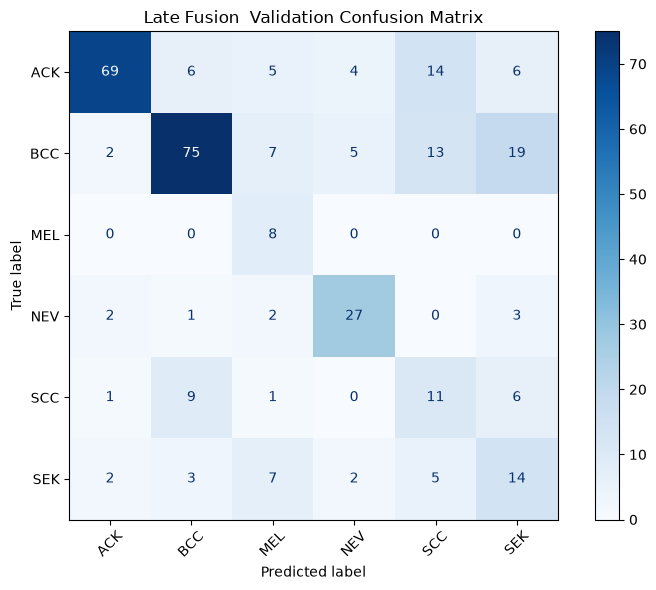


SECTION 8.2 COMPLETED SUCCESSFULLY


In [30]:
#Section 8.2  Evaluate validation-selected late fusion

from sklearn.metrics import accuracy_score,balanced_accuracy_score,classification_report,ConfusionMatrixDisplay


best_row= late_weights_df.sort_values(
    ["Macro-F1", "Image Weight"],
    ascending=[False, True]
).iloc[0]

best_alpha= float(best_row["Image Weight"])

val_late_prob= (
    best_alpha * image_probs
    + (1 - best_alpha) * metadata_probs
)

val_late_pred= np.array(CLASSES)[np.argmax(val_late_prob, axis=1)]

late_accuracy= accuracy_score(y_val, val_late_pred)

late_balanced_accuracy= balanced_accuracy_score(y_val, val_late_pred)

late_macro_f1= f1_score(
    y_val,
    val_late_pred,
    labels= CLASSES,
    average= "macro",
    zero_division= 0
)

assert np.isfinite(val_late_prob).all()
assert np.allclose(val_late_prob.sum(axis=1), 1.0)

print("LATE FUSION VALIDATION RESULTS")

print(f"Selected image weight:{best_alpha:.2f}")
print(f"Selected metadata weight:{1-best_alpha:.2f}")

print(f"\nAccuracy:{late_accuracy:.4f}")
print(f"Balanced Accuracy:{late_balanced_accuracy:.4f}")
print(f"Macro-F1:{late_macro_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        val_late_pred,
        labels= CLASSES,
        digits= 4,
        zero_division= 0
    )
)

fig,ax= plt.subplots(figsize= (8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_late_pred,
    labels= CLASSES,
    ax= ax,
    cmap= "Blues",
    xticks_rotation= 45
)

ax.set_title("Late Fusion  Validation Confusion Matrix")

plt.tight_layout()
plt.show()

print("\nSECTION 8.2 COMPLETED SUCCESSFULLY")

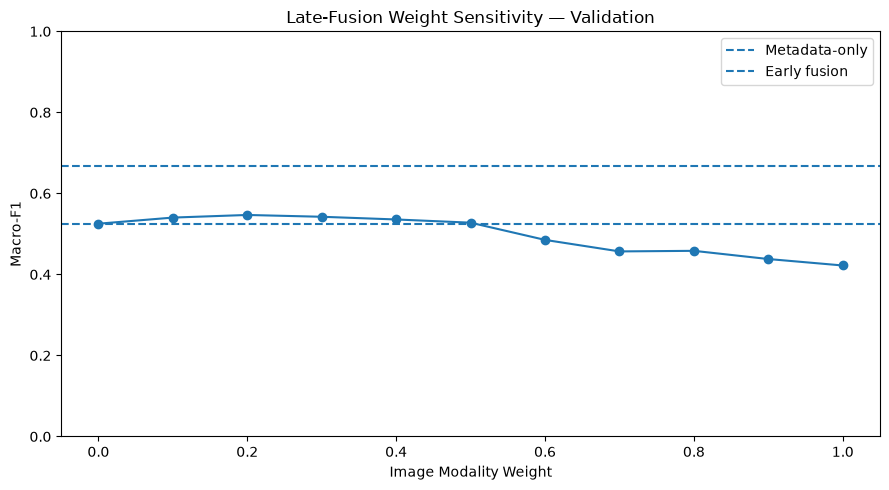

Late fusion minus early fusion macro-F1: -0.1213

SECTION 8 COMPLETED SUCCESSFULLY


In [31]:
#Section 8.3 Late-fusion weight sensitivity analysis

fig,ax= plt.subplots(figsize= (9, 5))

ax.plot(late_weights_df["Image Weight"],late_weights_df["Macro-F1"],marker= "o")

ax.axhline(metadata_macro_f1,linestyle= "--",label= "Metadata-only")

ax.axhline(early_macro_f1,linestyle= "--",label= "Early fusion")

ax.set_title("Late-Fusion Weight Sensitivity — Validation")
ax.set_xlabel("Image Modality Weight")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1)
ax.legend()

plt.tight_layout()
plt.show()

#Difference between late and early fusion
macro_f1_difference= late_macro_f1-early_macro_f1

print("Late fusion minus early fusion macro-F1:",round(macro_f1_difference, 4))

print("\nSECTION 8 COMPLETED SUCCESSFULLY")

### 8.4 Interpretation of Late Fusion Performance

The late fusion approach merged the probabilities of the independently trained image-based and metadata-based classifiers. The 11 weight combination defined by a pre-specfied grid were analyzed on the patient-disjoint validation subset.

The highest validation macro-F1 0.5468 was obtained using 20% image predictions and 80% metadata predictions. This combination provided 62.01% accuracy and 64.53% balanced accuracy.

Late fusion improved macro-F1 by 0.0216 over the metadata-only baseline (0.5252) but performed substantially worse than early fusion (0.6881) with a difference of 0.1213.

The weight sensitivity analysis revealed that increasing the share of image predictions above approximately 50% worsened classification performance. Hence, the inferior image classifier limtied potential of decision level fusion at the moment.

Late fusion correctly classified all eight melanoma patients in validation subset but obtained a relatively low 26.67% melanoma precision showing a high number of false positive cases. On the other hand, early fusion had 87.50% recall and 63.64% precision on melanoma.

From these results it can be concluded that early feature-level fusion works better than decision-level weighted fusion for the given dataset and models. Neverthless, these conclusions do not prove universal superiority of early fusion approach.

The weight for late fusion was selected based on valiation macro-F1 so that validation performance might be optimistically biased. Future analysis will consider the intermediate fusion, robustness and uncertainty before the test subset is evaluated.


## 9. Intermediate Fusion: Metadata-Conditioned Gated Network

### 9.1 Objective and Architecture 

The intemediated fusion learns interactions between modalities using trainable neural layers before the classification process.

The model recieves frozen 1,280 dimenisonal EfficientNet-B0 image embeddings and 27 dimensional encoded clinical metadata.

Separate projection layers transform both the modalities into compact 64-dimensional representations. A metadata-conditioned sigmoid gate then controls contribution of individual image features. Gated visual representation and metadata representation are concatenated and passed to a six-class classification head.

Hence, thsi architecture allows clinical information to modualte the visual features rather than combining raw features directly or averaging the independent predictions.

Original project 2.1 proposoal considered MetaBlock-based intermediate fusion (Pacheco and Krohling 2021). Final implementation instead uses a simpler metadata-conditioned gated neural network. Both the methods use structured patient information to influence visual representations but implemented signoid-gating mechanism is not an exaxt reproduction of the published MetaBlock architecture.

This adaption reduces architectural complexity while preserving the central objective of learning interactions between image and clinical modalities.


## 9.2 Training Strategy

Network is trained using cross-entropy loss with  the class-sensitive weighting to address dataset imbalance.

Regularisation includes dropout, weight decay and early stopping. Where the model is selected using validation macro-F1, whereas training and validation loss are monitored for signs of overfitting.

Only training partition contributes to gradint-based learning. Validation partition supports model selection and test partition remains untouched.

This experiment evaluates whether learned feature interactions offer advantages over early and late fusion.



In [32]:
#Section 9.1  Prepare intermediate-fusion tensors

import random
import copy
import time

import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader

#Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

#Existing train-fitted scaled representations
X_train_image_nn= X_train_img_scaled.astype(np.float32)
X_val_image_nn= X_val_img_scaled.astype(np.float32)

X_train_meta_nn= X_train_meta_scaled.astype(np.float32)
X_val_meta_nn= X_val_meta_scaled.astype(np.float32)

#Create aligned numeric target arrays
y_train_nn= train_df["diagnostic"].map(CLASS_TO_IDX).to_numpy(dtype=np.int64, copy=True)

y_val_nn= val_df["diagnostic"].map(CLASS_TO_IDX).to_numpy(dtype=np.int64, copy=True)

#Verify shapes and alignment
assert X_train_image_nn.shape== (1640, 1280)
assert X_train_meta_nn.shape== (1640, 27)

assert X_val_image_nn.shape== (329, 1280)
assert X_val_meta_nn.shape== (329, 27)

assert np.array_equal(y_train_nn,y_train_img)
assert np.array_equal(y_val_nn,y_val_img)

assert np.isfinite(X_train_image_nn).all()
assert np.isfinite(X_val_image_nn).all()
assert np.isfinite(X_train_meta_nn).all()
assert np.isfinite(X_val_meta_nn).all()

#Construct datasets
train_fusion_dataset= TensorDataset(
    torch.from_numpy(X_train_image_nn),
    torch.from_numpy(X_train_meta_nn),
    torch.from_numpy(y_train_nn)
)

val_fusion_dataset= TensorDataset(
    torch.from_numpy(X_val_image_nn),
    torch.from_numpy(X_val_meta_nn),
    torch.from_numpy(y_val_nn)
)

train_fusion_loader= DataLoader(
    train_fusion_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

val_fusion_loader= DataLoader(
    val_fusion_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("INTERMEDIATE FUSION DATA PREPARATION")


print("Training samples:",len(train_fusion_dataset))
print("Validation samples:",len(val_fusion_dataset))

print("Image dimensions:",X_train_image_nn.shape[1])
print("Metadata dimensions:",X_train_meta_nn.shape[1])
print("Number of classes:",len(CLASSES))
print("Device:",DEVICE)

print("\nSECTION 9.1 COMPLETED SUCCESSFULLY")

INTERMEDIATE FUSION DATA PREPARATION
Training samples: 1640
Validation samples: 329
Image dimensions: 1280
Metadata dimensions: 27
Number of classes: 6
Device: mps

SECTION 9.1 COMPLETED SUCCESSFULLY


In [33]:
#Section 9.2  Metadata-conditioned gated network

class GatedMultimodalNetwork(nn.Module):

    def __init__(
        self,
        image_dim=1280,
        metadata_dim=27,
        hidden_dim=64,
        num_classes=6,
        dropout=0.30
    ):
        super().__init__()

        #Image representation
        self.image_projection= nn.Sequential(nn.Linear(image_dim, hidden_dim),nn.ReLU(),nn.Dropout(dropout))

        #Clinical metadata representation
        self.metadata_projection=nn.Sequential(
            nn.Linear(metadata_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        #Metadata-conditioned gate
        self.gate= nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.Sigmoid()
        )

        #Joint classification network
        self.classifier= nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes)
        )

    def forward(self, image_features, metadata_features):

        image_repr= self.image_projection(image_features)

        metadata_repr= self.metadata_projection(metadata_features)

        gate_weights= self.gate(metadata_repr)

        gated_image= image_repr*gate_weights

        fused_features= torch.cat(
            [gated_image, metadata_repr],
            dim=1
        )

        return self.classifier(fused_features)


gated_model= GatedMultimodalNetwork(
    image_dim=1280,
    metadata_dim=27,
    hidden_dim=64,
    num_classes=len(CLASSES),
    dropout=0.30
).to(DEVICE)

#Validate network output dimensions
gated_model.eval()

with torch.no_grad():
    sample_logits=gated_model(
        torch.from_numpy(
            X_train_image_nn[:16]
        ).to(DEVICE),
        torch.from_numpy(
            X_train_meta_nn[:16]
        ).to(DEVICE)
    )

assert sample_logits.shape== (16, 6)
assert torch.isfinite(sample_logits).all()

total_parameters= sum(p.numel() for p in gated_model.parameters())

print("GATED INTERMEDIATE FUSION ARCHITECTURE")

print(gated_model)

print("\nTotal parameters:",total_parameters)
print("Output shape:",sample_logits.shape)

print("\nSECTION 9.2 COMPLETED SUCCESSFULLY")

GATED INTERMEDIATE FUSION ARCHITECTURE
GatedMultimodalNetwork(
  (image_projection): Sequential(
    (0): Linear(in_features=1280, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
  )
  (metadata_projection): Sequential(
    (0): Linear(in_features=27, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
  )
  (gate): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): Sigmoid()
  )
  (classifier): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=64, out_features=6, bias=True)
  )
)

Total parameters: 96582
Output shape: torch.Size([16, 6])

SECTION 9.2 COMPLETED SUCCESSFULLY


In [34]:
#Section 9.3 Train gated intermediate fusion

from sklearn.metrics import f1_score

#Class-sensitive weights using training labels only
class_counts= np.bincount(y_train_nn,minlength=len(CLASSES))

class_weights= np.sqrt(len(y_train_nn)/(len(CLASSES) * class_counts))

#Normalise weights for more stable loss scale
class_weights= class_weights/class_weights.mean()

class_weights_tensor= torch.tensor(class_weights,dtype=torch.float32,device=DEVICE)

criterion= nn.CrossEntropyLoss(weight= class_weights_tensor)

optimizer= torch.optim.AdamW(gated_model.parameters(),lr=0.001,weight_decay=0.0001)

MAX_EPOCHS= 80
PATIENCE= 12

history= {"train_loss": [],"val_loss": [],"val_macro_f1": []
}
best_f1= -1.0
best_val_loss= float("inf")
best_epoch= 0
best_state= None
epochs_without_improvement= 0

start_time= time.perf_counter()

for epoch in range(MAX_EPOCHS):

    #Training phase
    gated_model.train()

    running_loss= 0.0
    train_samples= 0

    for image_batch,meta_batch,labels in train_fusion_loader:

        image_batch= image_batch.to(DEVICE)
        meta_batch= meta_batch.to(DEVICE)
        labels= labels.to(DEVICE)

        optimizer.zero_grad()

        logits= gated_model(image_batch,meta_batch)

        loss= criterion(logits, labels)

        loss.backward()

        optimizer.step()

        batch_size= labels.size(0)

        running_loss+= loss.item()*batch_size
        train_samples+= batch_size

    train_loss= running_loss/train_samples

    #Validation phase
    gated_model.eval()

    val_running_loss= 0.0
    val_samples= 0
    val_predictions= []
    val_targets= []

    with torch.no_grad():

        for image_batch,meta_batch,labels in val_fusion_loader:

            image_batch= image_batch.to(DEVICE)
            meta_batch= meta_batch.to(DEVICE)
            labels= labels.to(DEVICE)

            logits= gated_model(image_batch,meta_batch)

            loss= criterion(logits, labels)

            batch_size= labels.size(0)

            val_running_loss+= loss.item()*batch_size
            val_samples+= batch_size

            predictions= logits.argmax(dim=1)

            val_predictions.extend(predictions.cpu().numpy())

            val_targets.extend(labels.cpu().numpy())

    val_loss= val_running_loss/val_samples

    val_macro_f1= f1_score(
        val_targets,
        val_predictions,
        labels=list(range(len(CLASSES))),
        average="macro",
        zero_division=0
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_macro_f1"].append(val_macro_f1)

    #Select model using macro-F1, with loss as tie-breaker
    improved=(
        val_macro_f1>best_f1+1e-6
        or (
            abs(val_macro_f1-best_f1)<=1e-6
            and val_loss<best_val_loss
        )
    )

    if improved:
        best_f1= val_macro_f1
        best_val_loss= val_loss
        best_epoch= epoch+1

        best_state= copy.deepcopy(gated_model.state_dict())

        epochs_without_improvement= 0

    else:
        epochs_without_improvement+= 1

    if (epoch+1)%5== 0 or epoch== 0:
        print(
            f"Epoch{epoch+1:02d} | "
            f"Train Loss:{train_loss:.4f} | "
            f"Val Loss:{val_loss:.4f} | "
            f"Val Macro-F1:{val_macro_f1:.4f}"
        )

    if epochs_without_improvement>= PATIENCE:
        print(f"\nEarly stopping triggered at epoch {epoch+1}")
        break

gated_training_time= time.perf_counter()-start_time

assert best_state is not None

#Restore best validation-selected model
gated_model.load_state_dict(best_state)
gated_model.eval()

print("\nINTERMEDIATE FUSION TRAINING SUMMARY")

print("Epochs executed:", len(history["train_loss"]))
print("Best epoch:", best_epoch)
print(f"Best validation macro-F1:{best_f1:.4f}")
print(f"Best validation loss:{best_val_loss:.4f}")
print(f"Training time:{gated_training_time:.2f} seconds")

print("\nSECTION 9.3 COMPLETED SUCCESSFULLY")

Epoch01 | Train Loss:1.5489 | Val Loss:1.2406 | Val Macro-F1:0.3819
Epoch05 | Train Loss:0.4634 | Val Loss:0.9713 | Val Macro-F1:0.6413
Epoch10 | Train Loss:0.1594 | Val Loss:1.4350 | Val Macro-F1:0.5806
Epoch15 | Train Loss:0.0734 | Val Loss:1.6893 | Val Macro-F1:0.6217

Early stopping triggered at epoch 16

INTERMEDIATE FUSION TRAINING SUMMARY
Epochs executed: 16
Best epoch: 4
Best validation macro-F1:0.6536
Best validation loss:0.9269
Training time:2.58 seconds

SECTION 9.3 COMPLETED SUCCESSFULLY


### 9.3A  Multiple-Seed Stability Analysis of Intermediate Gated Fusion

This supplementary experiment examines the sensitivity of the metadata-conditioned gated-fusion network to the randomness of initialisation and the shuffling of the training dataset.

Training was conducted five times using random seeds 42, 43, 44, 45 and 46. All the runs retained the original gated-fusion architecture, input feature representations, AdamW optimiser, class-weighted loss function, droupout rate 0.30, weight decay of 0.0001 and early-stopping strategy. Where each supplementary run used an explicitlyy seeded DataLoader generator to control training-data shuffling.

For each seed, the best macro-F1 on validation, selected epoch, the total number of epochs and training durations were obtained. The mean, standard deviation and range of best-validation  macro-F1 were then calculated and compared descriptively with the original early-fusion validation macro-F1 of 0.6681.

The experiment utilises only the existing patient-disjoint training and validation partitions. No held-out test data were accessed and neither original gated-fusion model nor previously selected early-fusion classifier was modified.

As the validation data partition was used for both for the early stopping and performance evaluation purposes, the resulting best-validation scores may be optimistic. Therefore, this supplementary experiment focuses on the training stability rather than an estimation of generalisation ability.


In [35]:
#Section 9.3A  Multiple-seed gated-fusion stability

#Reuses the original gated-fusion architecture and training strategy from Section 9.3.
#Uses an explicitly seeded DataLoader generator for each repeat run.
#Does not use held-out test data or overwrite the original gated_model.

import copy
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from sklearn.metrics import f1_score

stability_seeds= [42, 43, 44, 45, 46]
stability_results= []

for run_seed in stability_seeds:

    random.seed(run_seed)
    np.random.seed(run_seed)
    torch.manual_seed(run_seed)

    #Re-create a freshly initialised model for each seed.
    repeat_model= GatedMultimodalNetwork(
        image_dim= 1280,
        metadata_dim= 27,
        hidden_dim= 64,
        num_classes= len(CLASSES),
        dropout= 0.30
    ).to(DEVICE)

    repeat_optimizer= torch.optim.AdamW(
        repeat_model.parameters(),
        lr= 0.001,
        weight_decay= 0.0001
    )

    #Same training data and batch size as the original.
    #Explicit generator makes shuffling seed-dependent.
    run_generator= torch.Generator()
    run_generator.manual_seed(run_seed)

    repeat_train_loader= DataLoader(
        train_fusion_dataset,
        batch_size= 32,
        shuffle= True,
        num_workers= 0,
        generator= run_generator
    )

    repeat_val_loader= DataLoader(
        val_fusion_dataset,
        batch_size= 32,
        shuffle= False,
        num_workers= 0
    )

    #Same training-derived class weights as Section 9.3.
    repeat_criterion= nn.CrossEntropyLoss(weight=class_weights_tensor)

    run_best_f1= -1.0
    run_best_loss= float("inf")
    run_best_epoch= 0
    run_best_state= None
    epochs_without_improvement= 0
    epochs_executed= 0

    run_start= time.perf_counter()

    for epoch in range(80):

        repeat_model.train()

        for image_batch,meta_batch,labels in repeat_train_loader:
            image_batch= image_batch.to(DEVICE)
            meta_batch= meta_batch.to(DEVICE)
            labels= labels.to(DEVICE)

            repeat_optimizer.zero_grad()

            logits= repeat_model(image_batch, meta_batch)
            loss= repeat_criterion(logits, labels)

            loss.backward()
            repeat_optimizer.step()

        repeat_model.eval()
        val_predictions= []
        val_targets= []
        val_loss_sum= 0.0
        val_count= 0

        with torch.inference_mode():
            for image_batch, meta_batch, labels in repeat_val_loader:
                image_batch= image_batch.to(DEVICE)
                meta_batch= meta_batch.to(DEVICE)
                labels= labels.to(DEVICE)

                logits= repeat_model(image_batch, meta_batch)
                loss= repeat_criterion(logits, labels)

                batch_size= labels.size(0)
                val_loss_sum+= loss.item()*batch_size
                val_count+= batch_size

                val_predictions.extend(logits.argmax(dim=1).cpu().numpy())
                val_targets.extend(labels.cpu().numpy())

        run_val_loss= val_loss_sum / val_count

        run_val_f1=f1_score(
            val_targets,
            val_predictions,
            labels=list(range(len(CLASSES))),
            average="macro",
            zero_division=0
        )

        #Reproduce the original model-selection rule.
        improved=(
            run_val_f1>run_best_f1+1e-6
            or (
                abs(run_val_f1-run_best_f1) <= 1e-6
                and run_val_loss<run_best_loss
            )
        )

        if improved:
            run_best_f1=run_val_f1
            run_best_loss=run_val_loss
            run_best_epoch=epoch + 1
            run_best_state=copy.deepcopy(
                repeat_model.state_dict()
            )
            epochs_without_improvement=0
        else:
            epochs_without_improvement+=1

        epochs_executed=epoch+1

        if epochs_without_improvement>=12:
            break

    assert run_best_state is not None

    #Restore the validation-selected weights for this run.
    repeat_model.load_state_dict(run_best_state)
    repeat_model.eval()

    stability_results.append({
        "Seed": run_seed,
        "Best validation macro-F1": run_best_f1,
        "Best epoch": run_best_epoch,
        "Epochs executed": epochs_executed,
        "Training time (s)": time.perf_counter() - run_start
    })

stability_df= pd.DataFrame(stability_results)

print("GATED-FUSION MULTIPLE-SEED RESULTS")
display(stability_df.round(4))

mean_f1= stability_df["Best validation macro-F1"].mean()
sd_f1= stability_df["Best validation macro-F1"].std(ddof=1)
min_f1= stability_df["Best validation macro-F1"].min()
max_f1= stability_df["Best validation macro-F1"].max()

print("\nSTABILITY SUMMARY")
print(f"Mean validation macro-F1:{mean_f1:.4f}")
print(f"Standard deviation:{sd_f1:.4f}")
print(f"Minimum macro-F1:{min_f1:.4f}")
print(f"Maximum macro-F1:{max_f1:.4f}")
print(f"Original early fusion:{early_macro_f1:.4f}")

print("\nFive independent gated-model runs completed.")
print("Original gated_model unchanged.")
print("Held-out test set not accessed.")

GATED-FUSION MULTIPLE-SEED RESULTS


,Seed,Best validation macro-F1,Best epoch,Epochs executed,Training time (s)
0,42,0.6629,4,16,3.7317
1,43,0.6627,5,17,5.0305
2,44,0.6171,9,21,6.3073
3,45,0.6610,6,18,5.6507
4,46,0.6252,4,16,2.7858



STABILITY SUMMARY
Mean validation macro-F1:0.6458
Standard deviation:0.0227
Minimum macro-F1:0.6171
Maximum macro-F1:0.6629
Original early fusion:0.6681

Five independent gated-model runs completed.
Original gated_model unchanged.
Held-out test set not accessed.


### 9.3A.1 Interpretation of Gated-Fusion Training Stability
The five independent gated-fusion training procedures resulted in a mean best-validation macro-F1 score of 0.6458 with a standard deviation of 0.0227. The individual best-validation macro-F1 scores were  ranged from 0.6171 to 0.6629 and chosen best epoch was between epochs 4 and 9.

It is clear that the results are sensitive to the initial random initialisation and training data shuffling. None of the five gated runs exceeded the original early-fusion validation macro-F1 of 0.6681. Although, this descriptive comparison does not establish statistically reliable superiority of early fusion.

The repeated score using seed-42 (0.6629) was different from originally calculated gated-fusion macro-F1 score (0.6536). Thus, this analysis should be interpreted as an additional set of training runs rather than an exact reproduction of original gated-model execution.

The findings confirm the original conclusions about the variation of gated fusion but do not take into account such limitations as the small size of the dataset, the same validation subset for both early stopping and validation purposes or the lack of the external validation.

The original validation-selected early-fusion classifier and its held-out test results remain unchanged.

### 9.3B Constant-Gate Ablation

This supplementary experiment investigates whether metadata-conditioned gating contributes to validation performance. The original gated network is compared with a control using a fixed visual gate of 0.5.

Both models use the same input features, projection dimensions, classification head, five random seeds and training procedure. The constant-gate control does not train the gating layer, resulting in fewer trainable parameters.

The analysis uses training and validation data only. The results are exploratory because the validation partition is reused for early stopping and evaluation. The original selected model and held-out test results remain unchanged.

In [36]:
#Section 9.3B  Constant-gate control architecture

import torch

class ConstantGateNetwork(GatedMultimodalNetwork):

    def __init__(self, **kwargs):
        super().__init__(**kwargs)

        #The learned gate is not used in this control.
        for parameter in self.gate.parameters():
            parameter.requires_grad_(False)

    def forward(self,image_features,metadata_features):

        image_repr= self.image_projection(image_features)
        metadata_repr= self.metadata_projection(metadata_features)

        #Fixed gate replaces metadata-conditioned gating.
        gated_image= image_repr*0.5

        fused_features= torch.cat(
            [gated_image, metadata_repr],
            dim=1
        )

        return self.classifier(fused_features)


#Check the control architecture before training.
control_check = ConstantGateNetwork(
    image_dim=1280,
    metadata_dim=27,
    hidden_dim=64,
    num_classes=len(CLASSES),
    dropout=0.30
).to(DEVICE)

control_check.eval()

with torch.inference_mode():
    check_output= control_check(
        torch.zeros(2, 1280,device=DEVICE),
        torch.zeros(2, 27,device=DEVICE)
    )

assert check_output.shape== (2, len(CLASSES))

learned_parameters= sum(
    p.numel() for p in gated_model.parameters()
    if p.requires_grad
)

control_parameters= sum(
    p.numel() for p in control_check.parameters()
    if p.requires_grad
)

print("Learned-gate trainable parameters:",learned_parameters)
print("Constant-gate trainable parameters:",control_parameters)
print("Constant-gate architecture verified.")

Learned-gate trainable parameters: 96582
Constant-gate trainable parameters: 92422
Constant-gate architecture verified.


In [37]:
#Section 9.3B Constant-gate five-seed ablation

#Reuses the original gated-fusion architecture and training strategy from Section 9.3.
#Uses an explicitly seeded DataLoader generator for each repeat run.
#Does not use held-out test data or overwrite the original gated_model.

import copy
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from sklearn.metrics import f1_score

stability_seeds= [42, 43, 44, 45, 46]
constant_results= []

for run_seed in stability_seeds:

    random.seed(run_seed)
    np.random.seed(run_seed)
    torch.manual_seed(run_seed)

    #Re-create a freshly initialised model for each seed.
    repeat_model= ConstantGateNetwork(
        image_dim= 1280,
        metadata_dim= 27,
        hidden_dim= 64,
        num_classes= len(CLASSES),
        dropout= 0.30
    ).to(DEVICE)

    repeat_optimizer= torch.optim.AdamW(
        
        (p for p in repeat_model.parameters() if p.requires_grad),
        lr= 0.001,
        weight_decay= 0.0001
    )

    #Same training data and batch size as the original.
    #Explicit generator makes shuffling seed-dependent.
    run_generator= torch.Generator()
    run_generator.manual_seed(run_seed)

    repeat_train_loader= DataLoader(
        train_fusion_dataset,
        batch_size= 32,
        shuffle= True,
        num_workers= 0,
        generator= run_generator
    )

    repeat_val_loader= DataLoader(
        val_fusion_dataset,
        batch_size= 32,
        shuffle= False,
        num_workers= 0
    )

    #Same training-derived class weights as Section 9.3.
    repeat_criterion= nn.CrossEntropyLoss(weight=class_weights_tensor)

    run_best_f1= -1.0
    run_best_loss= float("inf")
    run_best_epoch= 0
    run_best_state= None
    epochs_without_improvement= 0
    epochs_executed= 0

    run_start= time.perf_counter()

    for epoch in range(80):

        repeat_model.train()

        for image_batch,meta_batch,labels in repeat_train_loader:
            image_batch= image_batch.to(DEVICE)
            meta_batch= meta_batch.to(DEVICE)
            labels= labels.to(DEVICE)

            repeat_optimizer.zero_grad()

            logits= repeat_model(image_batch, meta_batch)
            loss= repeat_criterion(logits, labels)

            loss.backward()
            repeat_optimizer.step()

        repeat_model.eval()
        val_predictions= []
        val_targets= []
        val_loss_sum= 0.0
        val_count= 0

        with torch.inference_mode():
            for image_batch, meta_batch, labels in repeat_val_loader:
                image_batch= image_batch.to(DEVICE)
                meta_batch= meta_batch.to(DEVICE)
                labels= labels.to(DEVICE)

                logits= repeat_model(image_batch, meta_batch)
                loss= repeat_criterion(logits, labels)

                batch_size= labels.size(0)
                val_loss_sum+= loss.item()*batch_size
                val_count+= batch_size

                val_predictions.extend(logits.argmax(dim=1).cpu().numpy())
                val_targets.extend(labels.cpu().numpy())

        run_val_loss= val_loss_sum / val_count

        run_val_f1=f1_score(
            val_targets,
            val_predictions,
            labels=list(range(len(CLASSES))),
            average="macro",
            zero_division=0
        )

        #Reproduce the original model-selection rule.
        improved=(
            run_val_f1>run_best_f1+1e-6
            or (
                abs(run_val_f1-run_best_f1) <= 1e-6
                and run_val_loss<run_best_loss
            )
        )

        if improved:
            run_best_f1= run_val_f1
            run_best_loss= run_val_loss
            run_best_epoch= epoch + 1
            run_best_state= copy.deepcopy(
                repeat_model.state_dict()
            )
            epochs_without_improvement= 0
        else:
            epochs_without_improvement+= 1

        epochs_executed=epoch+1

        if epochs_without_improvement>=12:
            break

    assert run_best_state is not None

    #Restore the validation-selected weights for this run.
    repeat_model.load_state_dict(run_best_state)
    repeat_model.eval()

    constant_results.append({
        "Seed": run_seed,
        "Best validation macro-F1": run_best_f1,
        "Best epoch": run_best_epoch,
        "Epochs executed": epochs_executed,
        "Training time (s)": time.perf_counter() - run_start
    })

constant_df= pd.DataFrame(constant_results)


print("CONSTANT-GATE MULTIPLE-SEED RESULTS")
display(constant_df.round(4))

constant_mean_f1= constant_df["Best validation macro-F1"].mean()
constant_sd_f1= constant_df["Best validation macro-F1"].std(ddof=1)
constant_min_f1= constant_df["Best validation macro-F1"].min()
constant_max_f1= constant_df["Best validation macro-F1"].max()

print("\nCONSTANT-GATE SUMMARY")
print(f"Mean validation macro-F1:{constant_mean_f1:.4f}")
print(f"Standard deviation:{constant_sd_f1:.4f}")
print(f"Minimum macro-F1:{constant_min_f1:.4f}")
print(f"Maximum macro-F1:{constant_max_f1:.4f}")
print(f"Original early fusion:{early_macro_f1:.4f}")

print("\nFive constant-gate runs completed.")
print("Original gated_model unchanged.")
print("Held-out test set not accessed.")

CONSTANT-GATE MULTIPLE-SEED RESULTS


,Seed,Best validation macro-F1,Best epoch,Epochs executed,Training time (s)
0,42,0.6626,3,15,2.0200
1,43,0.6700,8,20,4.1777
2,44,0.6348,9,21,6.0212
3,45,0.6499,5,17,4.8333
4,46,0.6432,6,18,5.0229



CONSTANT-GATE SUMMARY
Mean validation macro-F1:0.6521
Standard deviation:0.0143
Minimum macro-F1:0.6348
Maximum macro-F1:0.6700
Original early fusion:0.6681

Five constant-gate runs completed.
Original gated_model unchanged.
Held-out test set not accessed.


In [38]:
#Section 9.3B  Verify and compare both experiments

import pandas as pd

assert len(stability_results)== 5,("Original learned-gate results are missing.")

assert len(constant_results)== 5,("Constant-gate experiment has not completed five runs.")

#Reconstruct both DataFrames from their separate result lists.
stability_df= pd.DataFrame(stability_results)
constant_df= pd.DataFrame(constant_results)

print("ORIGINAL LEARNED-GATE RESULTS")
display(stability_df.round(4))

print("\nNEW CONSTANT-GATE RESULTS")
display(constant_df.round(4))

comparison_df= stability_df[
    ["Seed", "Best validation macro-F1"]
].merge(
    constant_df[
        ["Seed", "Best validation macro-F1"]
    ],
    on= "Seed",
    suffixes= ("_learned", "_constant"),
    validate= "one_to_one"
)

comparison_df["Difference"]= (
    comparison_df["Best validation macro-F1_learned"]
    - comparison_df["Best validation macro-F1_constant"]
)

print("\nLEARNED-GATE VS CONSTANT-GATE COMPARISON")
display(comparison_df.round(4))

print(
    "\nLearned-gate mean:",
    round(
        comparison_df[
            "Best validation macro-F1_learned"
        ].mean(), 4
    )
)

print(
    "Constant-gate mean:",
    round(
        comparison_df[
            "Best validation macro-F1_constant"
        ].mean(), 4
    )
)

print(
    "Mean paired difference:",
    round(comparison_df["Difference"].mean(), 4)
)

ORIGINAL LEARNED-GATE RESULTS


,Seed,Best validation macro-F1,Best epoch,Epochs executed,Training time (s)
0,42,0.6629,4,16,3.7317
1,43,0.6627,5,17,5.0305
2,44,0.6171,9,21,6.3073
3,45,0.6610,6,18,5.6507
4,46,0.6252,4,16,2.7858



NEW CONSTANT-GATE RESULTS


,Seed,Best validation macro-F1,Best epoch,Epochs executed,Training time (s)
0,42,0.6626,3,15,2.0200
1,43,0.6700,8,20,4.1777
2,44,0.6348,9,21,6.0212
3,45,0.6499,5,17,4.8333
4,46,0.6432,6,18,5.0229



LEARNED-GATE VS CONSTANT-GATE COMPARISON


,Seed,Best validation macro-F1_learned,Best validation macro-F1_constant,Difference
0,42,0.6629,0.6626,0.0002
1,43,0.6627,0.6700,-0.0074
2,44,0.6171,0.6348,-0.0177
3,45,0.6610,0.6499,0.0111
4,46,0.6252,0.6432,-0.0180



Learned-gate mean: 0.6458
Constant-gate mean: 0.6521
Mean paired difference: -0.0063


### 9.3B.1 Interpretation of Constant-Gate Ablation

The five-seed ablation compared the original metadata-conditioned gated-fusion network with a constant-gate control using a fixed visual gate of 0.5.

Learned gating achieved a mean best-validation macro-F1 of 0.6458, compared with 0.6521 for constant gating. The mean paired difference was −0.0063 with the constant-gate model performing better in three of five runs.

The results do not demonstrate a consistent validation benefit from metadata-conditioned gating. The constant-gate network also had 4,160 fewer trainable parameters so differences may reflect model capacity and optimisation as well as gating behaviour.

Because only five seeds were evaluated and the same validation partition was used for early stopping and comparison these findings remain exploratory. The original early-fusion model selection and held-out test results were not changed.

### 9.4 Intermediate Fusion Evaluation

The best validation-selectd gated fusion model is evaluated using accuracy, balanced accuracy, macro-F1 and class-specific precision and recall.

Training and validation loss curves are examined to identify the overfitting, whereas macro-F1 learning curve illustrates how predicitve performance changes during training process.

The results are compared against the existing unimodal, early-fusion and late-fusion baselines.

The final test partition remains untouched during this evaluation.


INTERMEDIATE FUSION VALIDATION RESULTS
Accuracy:0.7052
Balanced Accuracy:0.6601
Macro-F1:0.6536
Best epoch:4
Training time:2.58 seconds

Classification Report:
              precision    recall  f1-score   support

         ACK     0.7241    0.8077    0.7636       104
         BCC     0.7121    0.7769    0.7431       121
         MEL     0.8000    1.0000    0.8889         8
         NEV     0.7222    0.7429    0.7324        35
         SCC     0.3571    0.1786    0.2381        28
         SEK     0.7143    0.4545    0.5556        33

    accuracy                         0.7052       329
   macro avg     0.6717    0.6601    0.6536       329
weighted avg     0.6891    0.7052    0.6902       329



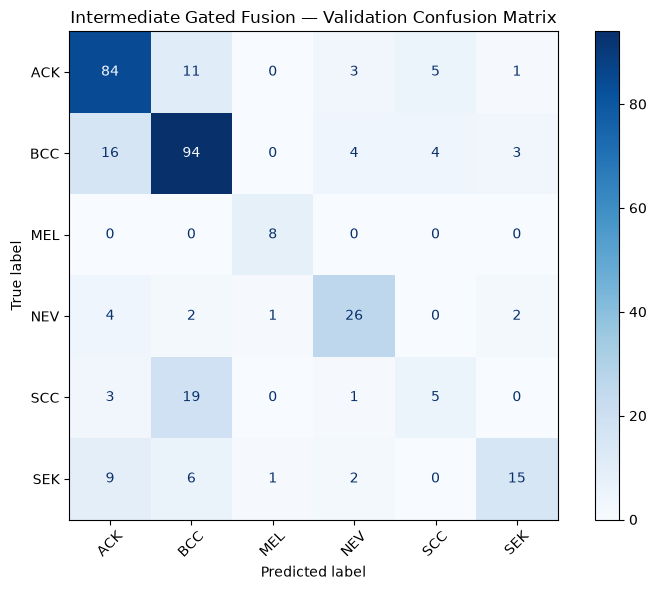


SECTION 9.4 COMPLETED SUCCESSFULLY


In [39]:
#Section 9.4  Evaluate gated intermediate fusion

from sklearn.metrics import accuracy_score,balanced_accuracy_score,f1_score,classification_report,ConfusionMatrixDisplay


gated_model.eval()

all_predictions= []
all_targets=[]
all_probabilities=[]

with torch.inference_mode():
    for image_batch, meta_batch, labels in val_fusion_loader:

        logits= gated_model(image_batch.to(DEVICE),meta_batch.to(DEVICE))

        probabilities= torch.softmax(logits, dim=1)

        all_predictions.append(probabilities.argmax(dim=1).cpu().numpy())

        all_probabilities.append(probabilities.cpu().numpy())

        all_targets.append(labels.numpy())

val_gated_pred_indices= np.concatenate(all_predictions)
val_gated_prob= np.concatenate(all_probabilities)
val_gated_targets= np.concatenate(all_targets)

#Verify sample alignment
assert np.array_equal(val_gated_targets, y_val_nn)

assert val_gated_prob.shape== (329, 6)
assert np.isfinite(val_gated_prob).all()
assert np.allclose(val_gated_prob.sum(axis=1),1.0,atol=1e-5)

#Convert labels to original diagnostic names
val_gated_pred= np.array(CLASSES)[val_gated_pred_indices]
val_gated_actual= np.array(CLASSES)[val_gated_targets]

gated_accuracy= accuracy_score(val_gated_actual,val_gated_pred)

gated_balanced_accuracy= balanced_accuracy_score(val_gated_actual,val_gated_pred)

gated_macro_f1= f1_score(
    val_gated_actual,
    val_gated_pred,
    labels=CLASSES,
    average="macro",
    zero_division=0
)
print("INTERMEDIATE FUSION VALIDATION RESULTS")

print(f"Accuracy:{gated_accuracy:.4f}")
print(f"Balanced Accuracy:{gated_balanced_accuracy:.4f}")
print(f"Macro-F1:{gated_macro_f1:.4f}")
print(f"Best epoch:{best_epoch}")
print(f"Training time:{gated_training_time:.2f} seconds")

print("\nClassification Report:")
print(
    classification_report(
        val_gated_actual,
        val_gated_pred,
        labels=CLASSES,
        digits=4,
        zero_division=0
    )
)

fig,ax= plt.subplots(figsize= (8, 6))

ConfusionMatrixDisplay.from_predictions(val_gated_actual,val_gated_pred,labels=CLASSES,ax=ax,cmap="Blues",xticks_rotation=45)

ax.set_title("Intermediate Gated Fusion — Validation Confusion Matrix")

plt.tight_layout()
plt.show()

print("\nSECTION 9.4 COMPLETED SUCCESSFULLY")

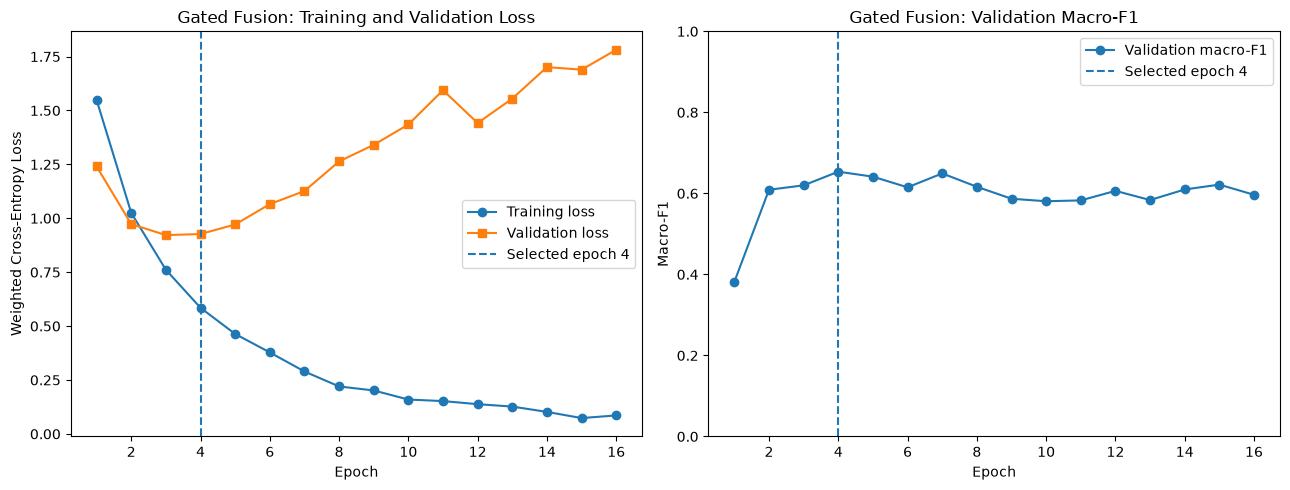

LEARNING CURVE SUMMARY
Selected epoch: 4
Epochs executed: 16
Training loss at selected epoch: 0.5848
Validation loss at selected epoch: 0.9269
Final training loss: 0.0858
Final validation loss: 1.7817


In [40]:
#Section 9.5  Learning curves and overfitting analysis

epochs= np.arange(1,len(history["train_loss"])+1)

fig,axes= plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Training loss"
)

axes[0].plot(
    epochs,
    history["val_loss"],
    marker="s",
    label="Validation loss"
)

axes[0].axvline(
    best_epoch,
    linestyle= "--",
    label= f"Selected epoch {best_epoch}"
)

axes[0].set_title("Gated Fusion: Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Weighted Cross-Entropy Loss")
axes[0].legend()

axes[1].plot(
    epochs,
    history["val_macro_f1"],
    marker= "o",
    label= "Validation macro-F1"
)

axes[1].axvline(
    best_epoch,
    linestyle= "--",
    label= f"Selected epoch {best_epoch}"
)

axes[1].set_title("Gated Fusion: Validation Macro-F1")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].set_ylim(0, 1)
axes[1].legend()

plt.tight_layout()
plt.show()

print("LEARNING CURVE SUMMARY")


print("Selected epoch:", best_epoch)
print("Epochs executed:", len(epochs))

print("Training loss at selected epoch:",round(history["train_loss"][best_epoch - 1], 4))

print("Validation loss at selected epoch:",round(history["val_loss"][best_epoch - 1], 4))

print("Final training loss:",round(history["train_loss"][-1], 4))

print("Final validation loss:",round(history["val_loss"][-1], 4))

FIVE-MODEL VALIDATION COMPARISON


,Model,Accuracy,Balanced Accuracy,Macro-F1
2,Early fusion,0.6991,0.7131,0.6681
4,Intermediate gated fusion,0.7052,0.6601,0.6536
3,Late fusion,0.6201,0.6453,0.5468
0,Metadata-only,0.5745,0.6442,0.5252
1,Image-only,0.5289,0.4172,0.4221


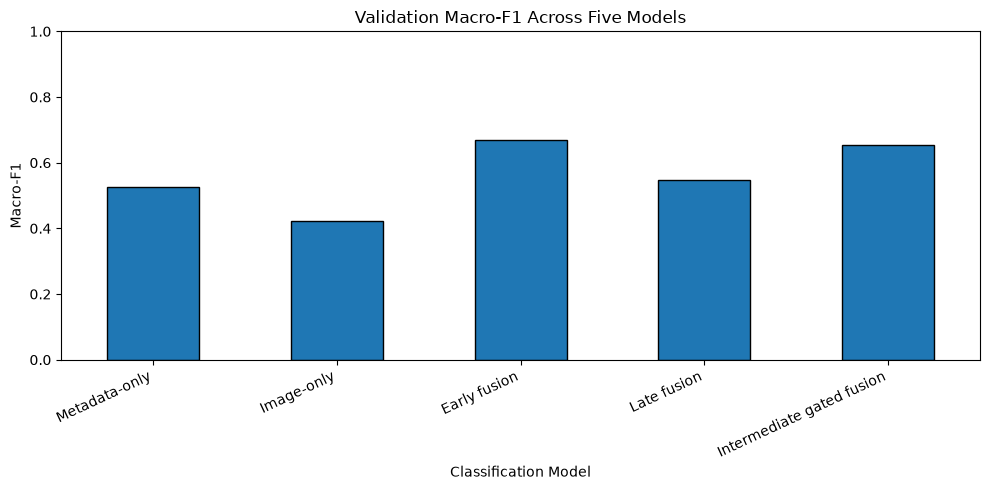


Intermediate minus early fusion macro-F1: -0.0145


In [41]:
#Section 9.6  Five-model validation comparison

five_model_comparison= pd.DataFrame([
    ["Metadata-only",metadata_accuracy,
     metadata_balanced_accuracy,metadata_macro_f1],

    ["Image-only",image_accuracy,
     image_balanced_accuracy,image_macro_f1],

    ["Early fusion",early_accuracy,
     early_balanced_accuracy,early_macro_f1],

    ["Late fusion",late_accuracy,
     late_balanced_accuracy,late_macro_f1],

    ["Intermediate gated fusion",gated_accuracy,
     gated_balanced_accuracy, gated_macro_f1]
], columns= [
    "Model",
    "Accuracy",
    "Balanced Accuracy",
    "Macro-F1"
])

print("FIVE-MODEL VALIDATION COMPARISON")
display(
    five_model_comparison.sort_values(
        "Macro-F1",
        ascending= False
    ).round(4)
)

ax= five_model_comparison.plot(
    x= "Model",
    y= "Macro-F1",
    kind= "bar",
    figsize= (10, 5),
    legend= False,
    edgecolor= "black"
)

ax.set_title("Validation Macro-F1 Across Five Models")
ax.set_xlabel("Classification Model")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1)

plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

print("\nIntermediate minus early fusion macro-F1:",round(gated_macro_f1 - early_macro_f1, 4))

### 9.7 Interpretation of Intermediate Fusion and Model Comparison

Intermediate-fusion approach combined 1,280 dimensional embeddings of images and 27-dimensional features of clinical metadata features using separate projection layers and metadata-conditioned gating. The neural network contained 96,582 trainable parameters.

The optimal checkpoint for this model was found at epoch 4 with 70.52% validation accuracy, 66.01% balanced accuracy and 0.6536 macro-F1 score. The model predicted all eight cases of melanomas from validation dataset but only five of 28 cases of squamous cell carcinoma (SCC).

Learning curves showed the presence of considerable overfitting. Training loss decreased from 0.5848 at the selected epoch to 0.0858 at epoch 16 whereas validation loss increased from 0.9269 to 1.7817. Early stopping saved better-performing checkpoint.

Among the five approaches, early fusion achieved the highest validation macro-F1 (0.6681) and balanced accuracy (0.7131) while the intermediate fusion resulted in maximum accuracy of (0.7052). Late fusion demonstrated macro-F1 equals to 0.5468.

Early fusion outerperformed intermediate fusion by 0.0145 points in macro-F1 score. This small observed difference does not establish any statistically reliable advantage particularly given the limited number of the minority-class examples.

The experiments revealed that combining of visual and clinical representations of patients is beneficial under the current experimental conditions. However, the problems of class-specific errors, dataset bias, overfitting and validation-selection uncertainty require further investigation before conclusions about generalisability can be drawn

## 10. Statistical Uncertainty and Robustness Evaluation
### 10.1 Patient-Clustered Bootstrap Analysis

Five methods of classification were assessed using one patient disjoint partitioning of the validation set. However, point estimates alone do not  provide information about uncertainty inherent to the estimated differences.

The patient-clustered bootstrap was used to assess the uncertainty of macro-F1 scores and the differences between multimodal  models. Patients are sampled with replacement and all validation images belonging to each sampled patient are retained together.

This procedure accounts for within-patient dependence when resampling validation obervations. It does not capture the training instability or the uncertainty from alternative data partitions.

The analysis focuses on the early fusion compared with the meta-data only, late-fusion and the intermediate-fusion models.

The final test partition it remains untouched.

In [42]:
#Section 10.1  Patient-clustered bootstrap uncertainty

from sklearn.metrics import f1_score
import numpy as np
import pandas as pd

#All predictions must follow the original validation row order.
validation_predictions= {
    "Metadata-only":np.asarray(val_meta_pred),
    "Image-only":np.asarray(val_img_pred),
    "Early fusion":np.asarray(val_early_pred),
    "Late fusion":np.asarray(val_late_pred),
    "Intermediate fusion":np.asarray(val_gated_pred)
}

actual_labels= np.asarray(y_val)
patient_ids= val_df["patient_id"].to_numpy()

#Verify alignment and sample counts
assert len(actual_labels)== len(patient_ids)== 329

for name, predictions in validation_predictions.items():
    assert len(predictions)== len(actual_labels), name

#Collect the positions of images belonging to each patient
unique_patients= np.unique(patient_ids)

patient_positions= [
    np.flatnonzero(patient_ids== patient)
    for patient in unique_patients
]

N_BOOTSTRAPS= 2000
rng= np.random.default_rng(SEED)

bootstrap_scores= {
    name: []
    for name in validation_predictions
}

for _ in range(N_BOOTSTRAPS):

    sampled_patients= rng.integers(
        low= 0,
        high= len(patient_positions),
        size= len(patient_positions)
    )

    sampled_positions= np.concatenate([
        patient_positions[index]
        for index in sampled_patients
    ])

    y_sample= actual_labels[sampled_positions]

    for name,predictions in validation_predictions.items():

        score= f1_score(
            y_sample,
            predictions[sampled_positions],
            labels=CLASSES,
            average="macro",
            zero_division=0
        )

        bootstrap_scores[name].append(score)

#Display percentile confidence intervals
ci_records= []

for name, values in bootstrap_scores.items():

    lower,upper= np.percentile(
        values, [2.5, 97.5]
    )

    observed= f1_score(
        actual_labels,
        validation_predictions[name],
        labels= CLASSES,
        average= "macro",
        zero_division= 0
    )

    ci_records.append({
        "Model": name,
        "Observed Macro-F1": observed,
        "CI Lower": lower,
        "CI Upper": upper
    })

bootstrap_ci_df= pd.DataFrame(ci_records)

print("PATIENT-CLUSTERED BOOTSTRAP RESULTS")

print("Unique validation patients:",len(unique_patients))
print("Bootstrap iterations:",N_BOOTSTRAPS)

display(bootstrap_ci_df.round(4))

PATIENT-CLUSTERED BOOTSTRAP RESULTS
Unique validation patients: 196
Bootstrap iterations: 2000


,Model,Observed Macro-F1,CI Lower,CI Upper
0,Metadata-only,0.5252,0.4512,0.5902
1,Image-only,0.4221,0.3405,0.4809
2,Early fusion,0.6681,0.5860,0.7264
3,Late fusion,0.5468,0.4746,0.6098
4,Intermediate fusion,0.6536,0.5817,0.7138


In [43]:
#Section 10.2  Paired bootstrap model differences

early_scores= np.asarray(bootstrap_scores["Early fusion"])

comparison_names= ["Metadata-only","Late fusion", "Intermediate fusion" ]

difference_records= []

for name in comparison_names:

    other_scores= np.asarray(bootstrap_scores[name])

    differences= early_scores-other_scores

    lower,upper= np.percentile(differences,[2.5, 97.5])

    observed_difference= (
        early_macro_f1
        - f1_score(
            actual_labels,
            validation_predictions[name],
            labels=CLASSES,
            average="macro",
            zero_division=0
        )
    )

    difference_records.append({
        "Comparison":f"Early fusion - {name}",
        "Observed Difference": observed_difference,
        "CI Lower":lower,
        "CI Upper":upper
    })

bootstrap_difference_df= pd.DataFrame(difference_records)

print("PAIRED BOOTSTRAP MACRO-F1 DIFFERENCES")


display(bootstrap_difference_df.round(4))

print(
    "\nNote: Intervals describe sampling uncertainty "
    "conditional on the fitted models and validation set."
)

PAIRED BOOTSTRAP MACRO-F1 DIFFERENCES


,Comparison,Observed Difference,CI Lower,CI Upper
0,Early fusion - Metadata-only,0.1429,0.0709,0.2072
1,Early fusion - Late fusion,0.1213,0.0567,0.1834
2,Early fusion - Intermediate fusion,0.0145,-0.0608,0.0793



Note: Intervals describe sampling uncertainty conditional on the fitted models and validation set.


### 10.3 Interpretation of Bootstrap Results
A bootstrap procedure for clustered patients with 2,000 resamples was used in which 196 validation patients were utilized to measure uncertainty in macro-F1 and in paired comparison of model performances.

For early fusion, we obtained 0.6681 for the observed value and 0.5860-0.7264 for 95% percentile bootstrap interval. For intermediate fusion achieeved 0.6536 (0.5817-0.7138), whereas for metadata-only and late fusion achieved 0.5252 and 0.5468 respectively.

The difference between early fusion and metadata-only fusion is 0.1429 with a 95% bootstrap interval of 0.0709-0.2072. The difference between early fusion and late fusion is 0.1213 (0.0567-0.1834). Both intervals remained above zero, supporting a positive difference under current validation and resampling procedure.

However, the difference between early fusion and intermediate fusion is 0.0145 (-0.0608 to 0.0793). Since this interval contains zero there is no evidence in favor of the difference being reliably different from zero.

Although patient-clustered bootstraping takes into account dependence among photographs from same patient it cannot replace patient-grouped cross-validation proposed previously in Project 2.1. While the former measures uncertainty for the existing fitted models the latter retrains the models on different patient-disjoint development folds.

Furthermore, these intervals do not capture variability from model retraining or differences in external populations. The small number of minority-class observations may also produce unstable bootstrap estimates.

Overall, the results support a validation-set advantage for early fusion over metadata-only and late fusion while highlighting the need for further robustness evaluation, modality analysis and bias assessment before drawing broader conclusions.

## 11. Modality Contribution and Ablation Analysis
### 11.1 Objective
Despite the better results achieved by early fusion compared to unimodal baselines there is no clear indication of the contribution made by each modality to the learned predictions.

This experiment evaluates sensitivity of trained early-fusion classifier with respect to each modality is evaluated by performing permutations on the image and metadata features separately in the validation records.

Each permutation maintains the distribution of its own modality without being assosciated with the diagnosis and other modality.

The performances are measured based on the unaltered validation data using metrics such as macro F1 score and balanced accuracy.

This is an evaluation of diagnostic perturbation experiments, not independently retrained unimodal models or causal estimates of modality importance. Permutations create out-of-distribution inputs from multimodal perspectives.

The held-out test partition remains unused.


EARLY FUSION  MODALITY SENSITIVITY


,Experiment,Accuracy,Balanced Accuracy,Macro-F1
0,Original early fusion,0.6991,0.7131,0.6681
1,Image features permuted,0.4985,0.3936,0.3885
2,Metadata features permuted,0.3587,0.2802,0.2724



Macro-F1 change relative to original model:


,Experiment,Macro-F1 Drop
0,Original early fusion,0.0000
1,Image features permuted,0.2796
2,Metadata features permuted,0.3957


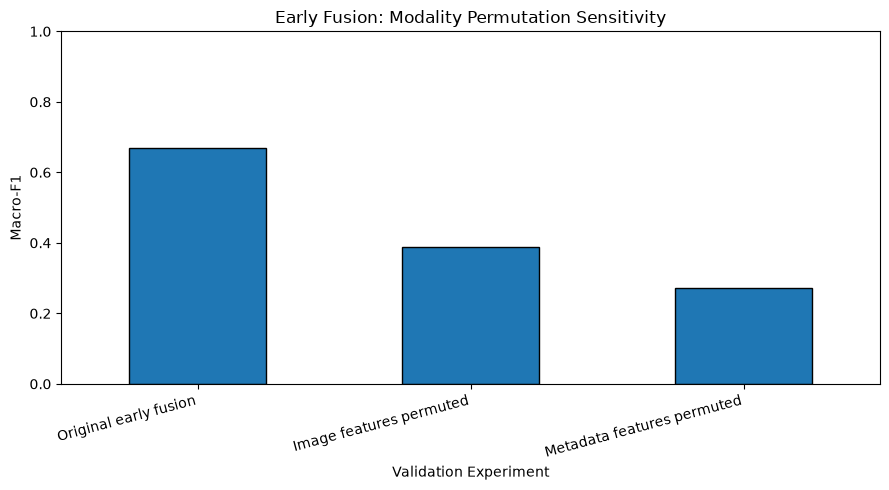


SECTION 11.1 COMPLETED SUCCESSFULLY


In [44]:
#Section 11.1  Early-fusion modality sensitivity

from sklearn.metrics import f1_score, balanced_accuracy_score

rng= np.random.default_rng(SEED)

#Original validation representations
original_image= X_val_img_scaled / np.sqrt(image_dim)
original_meta= X_val_meta_scaled / np.sqrt(metadata_dim)

assert original_image.shape== (329, 1280)
assert original_meta.shape== (329, 27)

#Randomly permute entire modality feature blocks
image_permutation= rng.permutation(len(y_val))
meta_permutation= rng.permutation(len(y_val))

experiments= {
    "Original early fusion":X_val_early,

    "Image features permuted":np.concatenate(
        [original_image[image_permutation],original_meta],
        axis=1
    ),

    "Metadata features permuted":np.concatenate(
        [original_image,original_meta[meta_permutation]],
        axis=1
    )
}

ablation_results= []

for name, features in experiments.items():

    predictions= early_fusion_model.predict(features)

    ablation_results.append({
        "Experiment": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_val, predictions
        ),
        "Macro-F1": f1_score(
            y_val,
            predictions,
            labels=CLASSES,
            average="macro",
            zero_division=0
        )
    })

ablation_df= pd.DataFrame(ablation_results)

print("EARLY FUSION  MODALITY SENSITIVITY")

display(ablation_df.round(4))

baseline_score= float(
    ablation_df.loc[
        ablation_df["Experiment"]== "Original early fusion",
        "Macro-F1"
    ].iloc[0]
)

ablation_df["Macro-F1 Drop"]= (baseline_score-ablation_df["Macro-F1"])

print("\nMacro-F1 change relative to original model:")
display(
    ablation_df[
        ["Experiment", "Macro-F1 Drop"]
    ].round(4)
)

ax= ablation_df.plot(
    x= "Experiment",
    y= "Macro-F1",
    kind= "bar",
    figsize= (9, 5),
    legend= False,
    edgecolor= "black"
)

ax.set_title("Early Fusion: Modality Permutation Sensitivity")
ax.set_xlabel("Validation Experiment")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0,1)

plt.xticks(rotation=15,ha="right")
plt.tight_layout()
plt.show()

print("\nSECTION 11.1 COMPLETED SUCCESSFULLY")

## 11.2 Interpretation of Modality Contribution¶

### Relationship to the Project 2.1 Metadata Ablation

Modality permutation was used to analyze how dependent the performance of the trained early fusion classifier is on its two input modalities.

The original model achieved macro-F1 score on the validation set of 0.6681. When image feature vectors were randomly shuffled among validation samples, macro-F1 decreased to 0.3885 showing a reduction of 0.2796. When metadata feature vectors were shuffled macro-F1 was equal to 0.2724 meaning a reduction of 0.3957.

Both the perturbations produced substantial performance deterioration  suggesting that classifier uses information from both modalities. The larger reduction assosciated with metadata permutation indicates greater sensitivity to clinical metadata under this particular experiment.

These findings support usefulness of combining the modalities but they do not establish causal feature importance or guarantee that learned assosciations are clinically meaningful. Permuting features may also create unrealistic image-metadata combinations and results depend on sampled permutations.

### Relationship ot the Project 2.1 Metadata Ablation

The initial proposal put forward a comparison of the conservative and more generous arrangements of the clinical metadata.

The comparsion was conducted in Section 15.2 through five-fold cross-validation with stratification based on patient groups. The more generous arrangement led to an improvement in the mean macro F1 of early fusion from 0.6133 to 0.6576 in all five folds.

However, since both clinical features and missing data features were added simultaneously it is impossible to differentiate real clinical features from potential documentation-based-shortcuts. Therefore, the conservative configuration was therefore retained as the primary model.

The modality permutation analysis in this section provides complementary evidence of model dependence on both modalities but it does not establish causal feature importance.


## 12. Missingness-Related Bias and Robustness Analysis
### 12.1 Objective
Previous analysis identified the systematic missignness across 11 clinical attributes in 35.06% of the training records. The missingness is highly variable among different diagnoses and is assosciated with biopsy status.

This implies that there exists possibility of shortcut learning where the classifiers exploit the documentation patterns that correlates with the diagnosis rather than learning clinically meaningful charcteristics.

This section investigates the relationship between missingness and diagnosis evaluates the predictive information contianed in missingness indicators and discusses implications for fairness and model generalisation.

This analysis makes use of the training data leaving out the test partition remains untouched.

### 12.2 Analysis Strategy

The following analyses are performed:

1. Quantify the assosciation between the missingness and diagnosis using a contigency table and chi-square test.
2. Evaluate a simple missingness-only classification baseline using patient-grouped cross-validation within the training partition.
3. Examine whether the findings justify retaining a conservative metadata feature set.

These experiments measures dataset assosciations, not the causal relationships. Missingness-related prediction performance does not establish the clinical relevance.

In [45]:
#Section 12.1  Missingness and diagnosis association

from scipy.stats import chi2_contingency
import pandas as pd
import numpy as np

#Reuse the 11 clinical columns defined in Section 4
assert set(systematic_columns).issubset(train_df.columns)

#True indicates that all 11 fields are missing
train_missing_indicator= (
    train_df[systematic_columns]
    .isna()
    .all(axis=1)
)

#Build a diagnosis-by-missingness contingency table
missingness_contingency= pd.crosstab(
    train_df["diagnostic"],
    train_missing_indicator
).reindex(
    index=CLASSES,
    columns=[False, True],
    fill_value=0
)

missingness_contingency.columns= ["Clinical Data Available","All 11 Fields Missing"]

#Chi-square test of independence
chi2,p_value,dof,expected= chi2_contingency(missingness_contingency)

#Cramer's V for association strength
n_samples= missingness_contingency.to_numpy().sum()

min_dimension= min(
    missingness_contingency.shape[0]-1,
    missingness_contingency.shape[1]-1
)

cramers_v= np.sqrt(chi2/(n_samples * min_dimension))

print("MISSINGNESS–DIAGNOSIS ASSOCIATION")

display(missingness_contingency)

print(f"\nChi-square statistic:{chi2:.4f}")
print(f"Degrees of freedom:{dof}")
print(f"P-value:{p_value:.6g}")
print(f"Cramer's V:{cramers_v:.4f}")

print("\nMinimum expected cell count:",round(float(expected.min()), 2))
print("\nSECTION 12.1 COMPLETED SUCCESSFULLY")

MISSINGNESS–DIAGNOSIS ASSOCIATION


,Clinical Data Available,All 11 Fields Missing
diagnostic,,
ACK,205,317
BCC,603,0
MEL,37,0
NEV,53,121
SCC,136,0
SEK,31,137



Chi-square statistic:820.3130
Degrees of freedom:5
P-value:4.66296e-175
Cramer's V:0.7072

Minimum expected cell count: 12.97

SECTION 12.1 COMPLETED SUCCESSFULLY


In [46]:
#Section 12.2  Missingness-only diagnostic baseline

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score,balanced_accuracy_score,f1_score


#Binary feature: whether all 11 selected fields are missing
X_missing= train_missing_indicator.to_numpy(dtype=np.int64).reshape(-1, 1)

y_missing= train_df["diagnostic"].to_numpy()

groups_missing= train_df["patient_id"].to_numpy()

cv= StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED)

cv_records= []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_missing, y_missing, groups_missing),
    start=1
):

    #Simple majority-class baseline
    dummy= DummyClassifier(strategy="most_frequent")

    dummy.fit(X_missing[train_idx],y_missing[train_idx])

    dummy_pred= dummy.predict(X_missing[val_idx])

    #A shallow tree learns predictions from missingness
    missing_model= DecisionTreeClassifier(max_depth= 1,random_state= SEED)

    missing_model.fit(X_missing[train_idx],y_missing[train_idx])

    missing_pred= missing_model.predict(X_missing[val_idx])

    for name,predictions in [
        ("Majority-class baseline",dummy_pred),
        ("Missingness-only tree",missing_pred)
    ]:

        cv_records.append({
            "Fold":fold,
            "Model":name,
            "Accuracy":accuracy_score(
                y_missing[val_idx],predictions
            ),
            "Balanced Accuracy": balanced_accuracy_score(
                y_missing[val_idx],predictions
            ),
            "Macro-F1": f1_score(
                y_missing[val_idx],
                predictions,
                labels=CLASSES,
                average="macro",
                zero_division=0
            )
        })

missing_cv_df= pd.DataFrame(cv_records)

print("MISSINGNESS-ONLY GROUPED CROSS-VALIDATION")

display(missing_cv_df.round(4))

print("\nMean and standard deviation across folds:")

missing_cv_summary = missing_cv_df.groupby("Model")[
    ["Accuracy", "Balanced Accuracy", "Macro-F1"]
].agg(["mean", "std"])

display(missing_cv_summary.round(4))
print("\nSECTION 12.2 COMPLETED SUCCESSFULLY")

MISSINGNESS-ONLY GROUPED CROSS-VALIDATION


,Fold,Model,Accuracy,Balanced Accuracy,Macro-F1
0,1,Majority-class baseline,0.3678,0.1667,0.0896
1,1,Missingness-only tree,0.5258,0.2492,0.1997
2,2,Majority-class baseline,0.3689,0.1667,0.0898
3,2,Missingness-only tree,0.5488,0.2612,0.2111
4,3,Majority-class baseline,0.3659,0.1667,0.0893
5,3,Missingness-only tree,0.5884,0.2825,0.2296
6,4,Majority-class baseline,0.3670,0.1667,0.0895
7,4,Missingness-only tree,0.6055,0.2917,0.2369
8,5,Majority-class baseline,0.3689,0.1667,0.0898
9,5,Missingness-only tree,0.5366,0.2548,0.2050



Mean and standard deviation across folds:


Accuracy         Balanced Accuracy         Macro-F1  \
                            mean     std              mean     std     mean   
Model                                                                         
Majority-class baseline   0.3677  0.0013            0.1667  0.0000   0.0896   
Missingness-only tree     0.5610  0.0343            0.2679  0.0183   0.2165   

                                 
                            std  
Model                            
Majority-class baseline  0.0002  
Missingness-only tree    0.0160


SECTION 12.2 COMPLETED SUCCESSFULLY


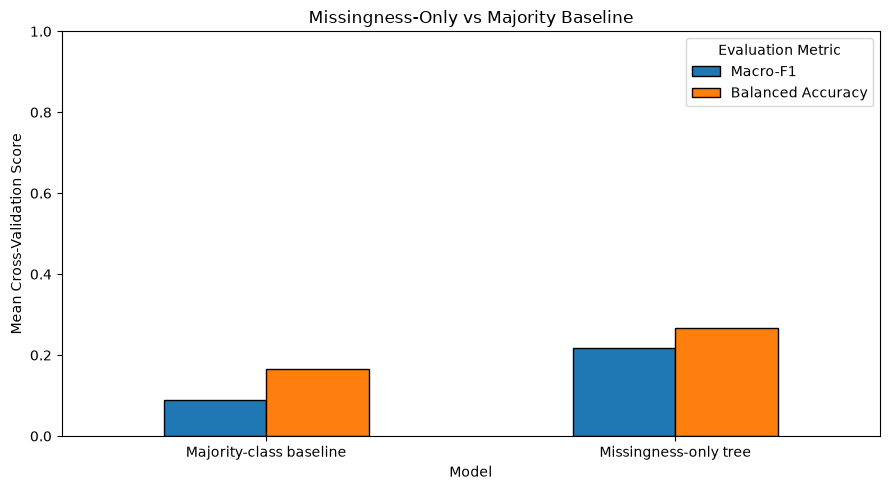

SECTION 12.3 COMPLETED SUCCESSFULLY


In [47]:
#Section 12.3  Visualise missingness-only results
summary_plot = (
    missing_cv_df
    .groupby("Model")[["Macro-F1","Balanced Accuracy"]]
    .mean()
)

ax= summary_plot.plot(
    kind="bar",
    figsize=(9, 5),
    edgecolor="black"
)

ax.set_title("Missingness-Only vs Majority Baseline")
ax.set_xlabel("Model")
ax.set_ylabel("Mean Cross-Validation Score")
ax.set_ylim(0, 1)

plt.xticks(rotation=0)
plt.legend(title="Evaluation Metric")
plt.tight_layout()
plt.show()

print("SECTION 12.3 COMPLETED SUCCESSFULLY")

## 12.4 Interpretation of Missingness-Related Bias

The training data exhibited a strong correlation between missingness in clinical metadata and diagnostic category. The chi-square statistic was 820.3130 with five degrees of freedom and a nominal p-value of about 4.66 × 10⁻¹⁷⁵. The strength of the observed assosciation measured using Cramer's V was 0.7072.

A five-fold patient group-based cross-validation experiment was conducted to test the hypothesis of whether missingness indicator alone holds any predictive power. For the missingness-only decision tree the mean accuracy was 0.5610 the mean balanced accuracy was 0.2679 and mean macro F1 was 0.2165. The corresponding values for the majority  class baseline were 0.3677, 0.1667 and 0.0896.

These findings indicate that the missingness pattern is assosciated with the diagnosis and can support the prediction above a simple majority-class baseline. However, its low macro-F1 indicates that it cannot reliably distinguish all six diagnostic categories.

This supports the decision to exlude the 11 systematically missing clinical attributes from the primary metadata representation. Neverthless, excluding these fields does not guarantee that other dataset-specific correlations or selection biases have been eliminated.

The chi-square significance estimate assumes the independent observations which may not hold because multiple images can belong to the same patient. Therefore, nominal p-values should be interpreted cautiously.

In conclusion, the experiment emphasizes the need to audit multimodal datasets for documentation-related-shortcuts before drawing conclusions about generalizability or clinical relevance.

## 12.5 Exploratory Image-Format Bias Audit

This analysis examines whether RGB and RGBA image formates are distributed differently across diagnostic categories in the training partition.

Differences may reflect the image acquisition or preprocessing procesures and could indicate the potential shortcut-learning opportunities.

This is an exploratory assosciation analysis. It does not establish that model actually uses  image format to predict the diagnoses.

TRAINING IMAGE-FORMAT BIAS AUDIT

Image counts by diagnosis:


mode,RGB,RGBA
diagnostic,,
ACK,294,228
BCC,125,478
MEL,13,24
NEV,59,115
SCC,31,105
SEK,84,84



Within-diagnosis percentages:


mode,RGB,RGBA
diagnostic,,
ACK,56.32,43.68
BCC,20.73,79.27
MEL,35.14,64.86
NEV,33.91,66.09
SCC,22.79,77.21
SEK,50.00,50.00


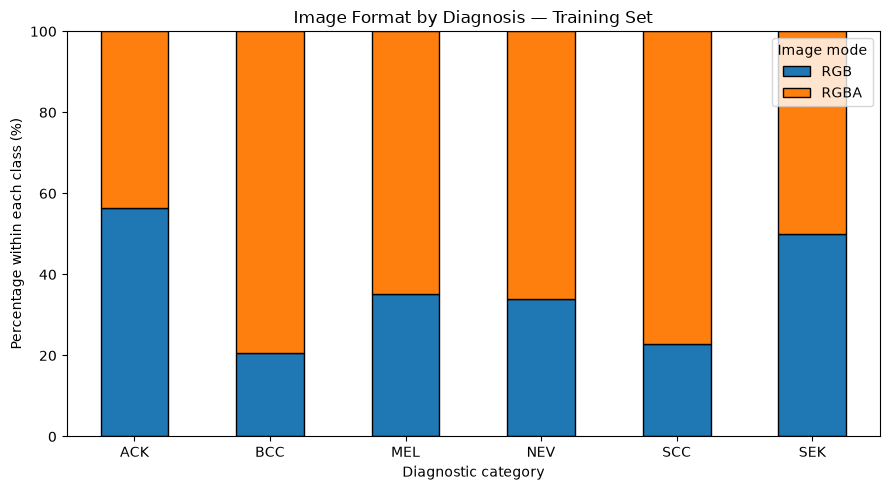


Training images audited: 1640
Held-out test partition not accessed.
SECTION 12.5 COMPLETED SUCCESSFULLY


In [48]:
#Section 12.5  Image-format bias audit
#Training partition only; no retraining or test access.

import pandas as pd
import matplotlib.pyplot as plt

mode_audit= train_df[
    ["img_id","diagnostic"]
].merge(
    image_info_df[["img_id","mode"]],
    on="img_id",
    how="left",
    validate="one_to_one"
)

assert len(mode_audit)== len(train_df)
assert mode_audit["mode"].notna().all()

mode_counts= pd.crosstab(
    mode_audit["diagnostic"],
    mode_audit["mode"]
).reindex(index=CLASSES,fill_value=0)

mode_percentages= (
    mode_counts.div(
        mode_counts.sum(axis=1),axis=0
    )*100
)

print("TRAINING IMAGE-FORMAT BIAS AUDIT")

print("\nImage counts by diagnosis:")
display(mode_counts)

print("\nWithin-diagnosis percentages:")
display(mode_percentages.round(2))

ax= mode_percentages.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    edgecolor="black"
)

ax.set_title("Image Format by Diagnosis — Training Set")
ax.set_xlabel("Diagnostic category")
ax.set_ylabel("Percentage within each class (%)")
ax.set_ylim(0, 100)

plt.xticks(rotation=0)
plt.legend(title="Image mode")
plt.tight_layout()
plt.show()

print("\nTraining images audited:",len(mode_audit))
print("Held-out test partition not accessed.")
print("SECTION 12.5 COMPLETED SUCCESSFULLY")

### 12.5.1 Interpretation of Image-Format Bias Audit

From the training specific  audit reveale significant variations in RGBA usage among images depending on diagnostic class with proportions varying from 43.68% in ACK and 50.00% in SEK to 79.27% in BCC and 77.21% in SCC. Melanoma and NEV had the intermediate levels of 64.86% and 66.09%, respectively.

This variation suggests a relationship between orginal format and diagnosis which may be indicative of class-specific image acquisition or processing. Thus, format-related image properties might become a shortcut for image classification algorithms.

Though all photographs have been composited against the white background and converted to RGB before feature extraction such processing does not produce the presence of collection-related artifacts. In addition, image file format is not identical to visibility of transparency.

This exploratory audit cannot prove that trained classifier takes advantage of image format information or even its causal role. Additional research woul require analysis of alphs-channel contents and image acquisition parameters and classifier sensitivity to the format-related features.

Only training dataset has been examined no models were retrained and held-out test partition was not accessed.

## 13. Computational Efficiency and Model Comparison
### 13.1 Objective
In addition to the classification performance, practical multimodal systems must consider the computational efficiency, inference latency and the model complexity.

This section compares the five previously implemented models using classification performance classifier training time and infernece latency.

The image feature extraction compnent is measured separately because of the necessity to use an EfficientNet-B0 encodee before classifying images in the image-based models while metadata-only model operates on the structured clinical attributes.

Infernece benchmarks are conducted using existing validation feature matrices avoiding repeated image decoding and network feature extraction during classifer-only measurements.

The reported timings therefore represent feature-level inference rather than full end-to-end clinical image processing. The distinction is important when assessing deployment feasibility.


### 13.2 Evaluation Measures
The comparison considers:
- Validation accuracy, balanced accuracy and macro-F1
- Classifier training time.
- Mean inference latency per sample.
- Model complexity and computational cost of frozen image feature extraction.

These measurements will support a performance-efficiency comparison rather selecting a model solely by its predictive accuracy.


In [49]:
#Section 13.1  Classifier inference benchmarking

import time
import numpy as np
import pandas as pd
import torch

N_REPEATS=30

def benchmark_cpu_model(model,features,repeats=N_REPEATS):
    """Measure mean prediction latency per sample in milliseconds."""

    #Warm-up
    model.predict(features)

    timings=[]

    for _ in range(repeats):
        start= time.perf_counter()
        model.predict(features)
        elapsed= time.perf_counter()-start
        timings.append(elapsed)

    return (np.median(timings)/len(features)*1000)


#Metadata-only model
metadata_latency= benchmark_cpu_model(metadata_model,X_val_meta)

#Image-only model
image_latency= benchmark_cpu_model(image_model,X_val_img)

#Early fusion model
early_latency= benchmark_cpu_model(early_fusion_model,X_val_early)


#Late fusion uses probabilities from two classifiers
def predict_late_fusion():
    meta_probs=metadata_model.predict_proba(
        X_val_meta
    )[:,metadata_indices]

    img_probs=image_model.predict_proba(
        X_val_img
    )[:,image_indices]

    combined=(
        best_alpha*img_probs
        + (1-best_alpha)*meta_probs
    )

    return np.argmax(combined,axis=1)


predict_late_fusion()

late_timings= []

for _ in range(N_REPEATS):
    start= time.perf_counter()
    predict_late_fusion()
    late_timings.append(time.perf_counter()-start)

late_latency= (np.median(late_timings)/len(val_df)*1000)


#Intermediate gated fusion
gated_model.eval()

val_image_tensor= torch.from_numpy(np.array(X_val_image_nn,copy=True)).to(DEVICE)

val_meta_tensor= torch.from_numpy(np.array(X_val_meta_nn,copy=True)).to(DEVICE)

def synchronize_device():
    if DEVICE.type== "mps":
        torch.mps.synchronize()
    elif DEVICE.type== "cuda":
        torch.cuda.synchronize()


with torch.inference_mode():
    gated_model(val_image_tensor,val_meta_tensor)
    synchronize_device()

gated_timings= []

with torch.inference_mode():
    for _ in range(N_REPEATS):
        synchronize_device()
        start= time.perf_counter()

        gated_model(val_image_tensor,val_meta_tensor)

        synchronize_device()
        gated_timings.append(
            time.perf_counter()-start
        )

gated_latency= (
    np.median(gated_timings)
    / len(val_df)
    * 1000
)


print("CLASSIFIER INFERENCE BENCHMARK")


latency_df= pd.DataFrame({
    "Model": [
        "Metadata-only",
        "Image-only",
        "Early fusion",
        "Late fusion",
        "Intermediate gated fusion"
    ],
    "Latency (ms/sample)": [
        metadata_latency,
        image_latency,
        early_latency,
        late_latency,
        gated_latency
    ]
})

display(latency_df.round(4))

print("\nBenchmark repetitions:",N_REPEATS)
print("Samples per benchmark:",len(val_df))
print("Device for neural fusion:",DEVICE)

print("\nSECTION 13.1 COMPLETED SUCCESSFULLY")

CLASSIFIER INFERENCE BENCHMARK


,Model,Latency (ms/sample)
0,Metadata-only,0.0002
1,Image-only,0.0014
2,Early fusion,0.0005
3,Late fusion,0.0016
4,Intermediate gated fusion,0.0024



Benchmark repetitions: 30
Samples per benchmark: 329
Device for neural fusion: mps

SECTION 13.1 COMPLETED SUCCESSFULLY


In [50]:
#Section 13.2  Consolidated performance-efficiency table

training_times= {
    "Metadata-only":metadata_training_time,
    "Image-only":image_training_time,
    "Early fusion":early_training_time,
    "Late fusion": (
        metadata_training_time+image_training_time
    ),
    "Intermediate gated fusion":gated_training_time
}

efficiency_df= five_model_comparison.copy()

efficiency_df["Training Time (s)"]= (efficiency_df["Model"].map(training_times))

efficiency_df= efficiency_df.merge(
    latency_df,
    on="Model",
    how="left",
    validate="one_to_one"
)

print("MODEL PERFORMANCE AND EFFICIENCY")

display(
    efficiency_df.sort_values(
        "Macro-F1",
        ascending=False
    ).round(4)
)

print(
    "\nFrozen EfficientNet feature extraction time:",
    round(feature_extraction_time, 2),
    "seconds for training + validation images"
)

print(
    "\nNote: The timing table excludes image decoding "
    "and feature extraction from classifier training "
    "and feature-level inference timings."
)

print("\nSECTION 13.2 COMPLETED SUCCESSFULLY")

MODEL PERFORMANCE AND EFFICIENCY


,Model,Accuracy,Balanced Accuracy,Macro-F1,Training Time (s),Latency (ms/sample)
2,Early fusion,0.6991,0.7131,0.6681,0.0808,0.0005
4,Intermediate gated fusion,0.7052,0.6601,0.6536,2.5787,0.0024
3,Late fusion,0.6201,0.6453,0.5468,0.3300,0.0016
0,Metadata-only,0.5745,0.6442,0.5252,0.0416,0.0002
1,Image-only,0.5289,0.4172,0.4221,0.2884,0.0014



Frozen EfficientNet feature extraction time: 50.59 seconds for training + validation images

Note: The timing table excludes image decoding and feature extraction from classifier training and feature-level inference timings.

SECTION 13.2 COMPLETED SUCCESSFULLY


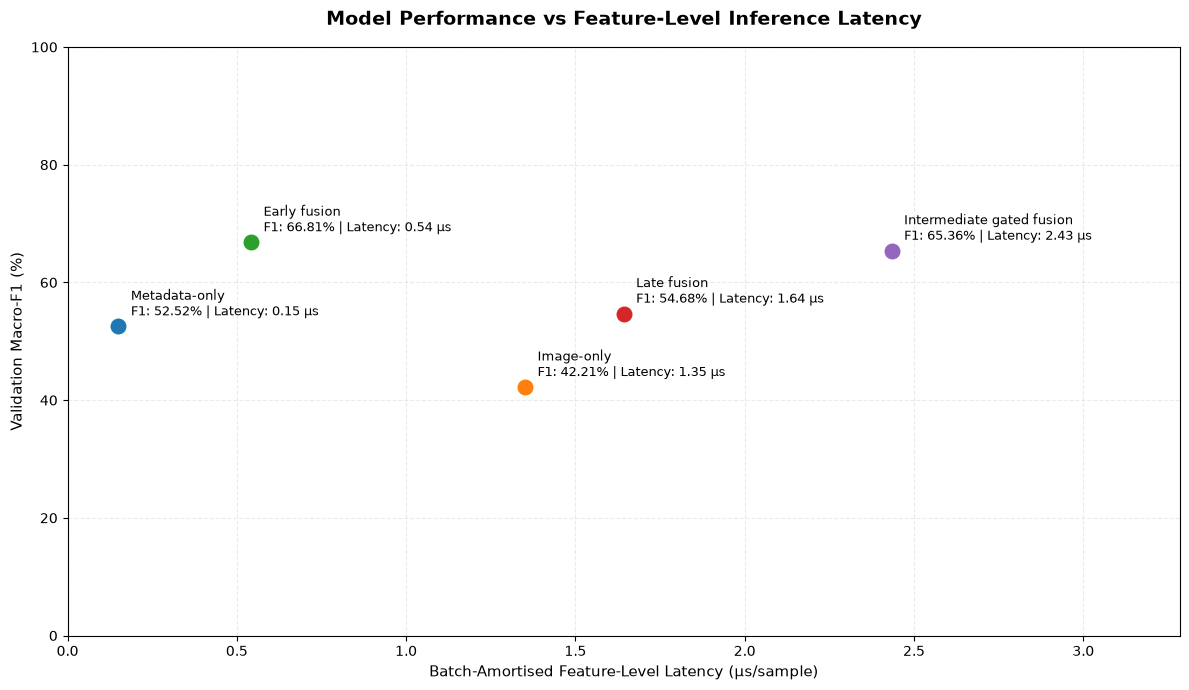

Note: Latency excludes image decoding, EfficientNet feature extraction and metadata preprocessing.

SECTION 13.3 COMPLETED SUCCESSFULLY


In [51]:
#Section 13.3  Improved performance-efficiency visualisation

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

plot_df= efficiency_df.copy()

#Convert values into more readable units
plot_df["Macro-F1 (%)"]= plot_df["Macro-F1"] * 100

plot_df["Latency (microseconds/sample)"]= (plot_df["Latency (ms/sample)"] * 1000)

fig,ax= plt.subplots(figsize=(12, 7))

#Plot actual observed results
for _,row in plot_df.iterrows():

    x= row["Latency (microseconds/sample)"]
    y= row["Macro-F1 (%)"]

    ax.scatter(x,y,s=110,zorder=3)

    ax.annotate(
        f"{row['Model']}\n"
        f"F1: {y:.2f}% | "
        f"Latency: {x:.2f} µs",
        xy=(x, y),
        xytext=(9, 8),
        textcoords="offset points",
        fontsize=9
    )

ax.set_title(
    "Model Performance vs Feature-Level Inference Latency",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax.set_xlabel("Batch-Amortised Feature-Level Latency (µs/sample)",fontsize=11)

ax.set_ylabel("Validation Macro-F1 (%)",fontsize=11)

ax.set_ylim(0, 100)

ax.set_xlim(0,plot_df["Latency (microseconds/sample)"].max() * 1.35)

ax.grid(alpha=0.25,linestyle="--")

plt.tight_layout()
plt.show()

print("Note: Latency excludes image decoding, ""EfficientNet feature extraction and ""metadata preprocessing.")

print("\nSECTION 13.3 COMPLETED SUCCESSFULLY")

**Figure 13.1:** Comparison of validation macro-F1 and median batch-amortised feature-level inference latency across five classification models. Early fusion achieved highest macro-F1 (66.81%) with approximately 0.60 µs/sample latency. Timings excluded image decoding, EfficientNet-B0 feature extraction and metadata preprocessing therefore they do not represent end-to-end inference performance.

## 14.Final Model Selection and Held-Out Test Evaluation
### 14.1 Final Model Selection
The Five classification approaches were designed and compared using the patient-disjoint validation partition.

Early fusion was selected as the primary model due to its better validation macro-f1 (0.6681) and balanced accuracy of (0.7131).

The proposed approach uses a combination of 1,280 dimensional frozen EfficientNet-B0 image representations with 27-dimensional encoded clinical metadata using training-fitted standardisation and modality balancing based on their dimensions.

The classifier is represented by a class-balanced multimodal logistic regression model with regularisation C=1.0.

The model architecture, feature selection, preprocessing parameters and classifier coefficients are frozen before accesssing the held-out test partition.

### 14.2 Evaluation Protocol
The held-out test partition comprises of 329 images from 197 patients which do not overlap in any way compared to the training and validation set.

Test images will undergo the same preprocessing steps used in the development of the system. The metadata features will be transformed using the existing training-fitted preprocessing pipeline without refitting.

Evaluation metrics include macro-F1 score, balanced accuracy, overall accuracy and class-specific precision and recall. Confusion matrix and patient-clustered bootstrap confidence intervals will used to examine the generalisation and uncertainty.

The test set results will be presented without further adjustment of the selected model or using the test partition for additional hyperparameter tuning.

The system is intended for educational and research evaluation only not the clinical diagnosis.



In [52]:
#Section 14.1  Freeze final model and preprocessing

import joblib
import json
from pathlib import Path

FINAL_DIR= PROJECT_DIR/"project2_2_outputs"/"final_model"
FINAL_DIR.mkdir(parents= True,exist_ok=True)

#Verify selected configuration
assert X_train_early.shape[1]== 1307
assert X_val_early.shape[1]== 1307

assert list(early_fusion_model.classes_)== CLASSES

#Store fitted preprocessing and classification components
final_artifacts= {
    "metadata_preprocessor":metadata_preprocessor,
    "image_scaler":fusion_image_scaler,
    "metadata_scaler":fusion_meta_scaler,
    "classifier":early_fusion_model,
    "classes":CLASSES,
    "selected_features":FINAL_METADATA_COLS,
    "image_dim":image_dim,
    "metadata_dim":metadata_dim,
    "image_background":"white",
    "image_input_size":[224, 224]
}

joblib.dump(final_artifacts,FINAL_DIR /"early_fusion_model.joblib")

#Save pretrained frozen feature extractor parameters
torch.save(feature_extractor.state_dict(),FINAL_DIR /"efficientnet_feature_extractor.pt")

#Record model selection
selection_record= {
    "selected_model":"Early fusion",
    "selection_metric":"validation_macro_f1",
    "validation_macro_f1":float(early_macro_f1),
    "validation_balanced_accuracy":float(
        early_balanced_accuracy
    ),
    "validation_accuracy":float(early_accuracy),
    "classifier_C":1.0,
    "random_seed":SEED,
    "test_used_for_selection":False
}

with open(
    FINAL_DIR/"model_selection.json",
    "w"
) as file:
    json.dump(selection_record,file,indent=4)

print("FINAL MODEL SELECTION")

print("Selected model: Early fusion")
print("Validation macro-F1:",round(early_macro_f1, 4))
print("Image features:",image_dim)
print("Metadata features:",metadata_dim)

print("\nFrozen model artifacts saved to:")
print(FINAL_DIR)

print("\nSECTION 14.1 COMPLETED SUCCESSFULLY")


FINAL MODEL SELECTION
Selected model: Early fusion
Validation macro-F1: 0.6681
Image features: 1280
Metadata features: 27

Frozen model artifacts saved to:
/Users/avinashmonteiro/Desktop/PAD_UFES20_Project/project2_2_outputs/final_model

SECTION 14.1 COMPLETED SUCCESSFULLY


In [53]:
#Section 14.2 Prepare untouched test partition

import numpy as np
from torch.utils.data import DataLoader

#Verify test partition and patient separation
assert len(test_df)== 329
assert test_df["patient_id"].nunique()== 197

assert set(test_df["patient_id"]).isdisjoint(set(train_df["patient_id"]))

assert set(test_df["patient_id"]).isdisjoint(set(val_df["patient_id"]))

#Transform test metadata using TRAIN-FITTED preprocessing
X_test_meta_raw= test_df[FINAL_METADATA_COLS].copy()

X_test_meta= metadata_preprocessor.transform(X_test_meta_raw)

X_test_meta= np.asarray(X_test_meta,dtype=np.float32)

#Apply the existing TRAIN-FITTED metadata scaler
X_test_meta_scaled= fusion_meta_scaler.transform(X_test_meta)

assert X_test_meta.shape== (329, 27)
assert X_test_meta_scaled.shape== (329, 27)
assert np.isfinite(X_test_meta_scaled).all()

#Create test image dataset using the SAME transformation
test_image_dataset= SkinLesionDataset(test_df,image_paths,image_transform)

test_image_loader= DataLoader(test_image_dataset,batch_size=16,shuffle=False,num_workers=0)

#Verify image loading without producing predictions
test_images,test_labels= next(iter(test_image_loader))

assert test_images.shape== (16, 3, 224, 224)
assert torch.isfinite(test_images).all()

print("HELD-OUT TEST DATA PREPARATION")

print("Test images:", len(test_image_dataset))
print("Unique test patients:",test_df["patient_id"].nunique())

print("Metadata matrix:",X_test_meta.shape)
print("Scaled metadata:",X_test_meta_scaled.shape)

print("First image batch:",test_images.shape)

print("\nPatient overlap: None")
print("Training scalers reused: Yes")
print("Model refitted: No")
print("Test predictions generated: No")

print("\nSECTION 14.2 COMPLETED SUCCESSFULLY")

HELD-OUT TEST DATA PREPARATION
Test images: 329
Unique test patients: 197
Metadata matrix: (329, 27)
Scaled metadata: (329, 27)
First image batch: torch.Size([16, 3, 224, 224])

Patient overlap: None
Training scalers reused: Yes
Model refitted: No
Test predictions generated: No

SECTION 14.2 COMPLETED SUCCESSFULLY


### 14.3 Final Held-Out Test Evaluation

After validation-based selection the frozen early-fusion architecture is assessed on the previously untouched test partition.

The test images are processed through the same RGB conversion, image resizing, normalisation and frozen EfficientNet-B0 feature extractor used throughout the development stage.

Clinical data is transformed using the already training-fitted preprocessing pipeline. The feature blocks are standardised using their training-fitted scalers and combined using the fixed dimension-based weighting approach.

No model parameters, preprocessing statistics nor any hyperparameters are fine-tuned with the help of the test set.

The evaluation produces the overall accuracy, balanced accuracy, macro-F1, class-specific metrics and the confusion matrix.


In [54]:
#Section 14.3  Extract test embeddings using frozen encoder

import time
import numpy as np

feature_extractor.eval()

start_time= time.perf_counter()

X_test_img, y_test_img= extract_image_features(test_image_loader,feature_extractor,DEVICE)

test_feature_extraction_time= (time.perf_counter()-start_time)

assert X_test_img.shape== (329, 1280)
assert y_test_img.shape== (329,)

assert np.isfinite(X_test_img).all()

#Verify the order of extracted images and labels
assert np.array_equal(
    y_test_img,
    test_df["diagnostic"].map(
        CLASS_TO_IDX
    ).to_numpy()
)

print("FINAL TEST IMAGE FEATURE EXTRACTION")

print("Test embeddings:",X_test_img.shape)
print("Test labels:",y_test_img.shape)

print(f"Extraction time:"f"{test_feature_extraction_time:.2f} seconds")

print("\nImage–metadata alignment verified.")
print("Feature extraction completed without model updates.")

print("\nSECTION 14.3 COMPLETED SUCCESSFULLY")

FINAL TEST IMAGE FEATURE EXTRACTION
Test embeddings: (329, 1280)
Test labels: (329,)
Extraction time:9.65 seconds

Image–metadata alignment verified.
Feature extraction completed without model updates.

SECTION 14.3 COMPLETED SUCCESSFULLY


FINAL HELD-OUT TEST RESULTS — EARLY FUSION
Accuracy:0.6444
Balanced Accuracy:0.5396
Macro-F1:0.5241

Classification Report:
              precision    recall  f1-score   support

         ACK     0.7404    0.7404    0.7404       104
         BCC     0.8454    0.6777    0.7523       121
         MEL     0.2857    0.2857    0.2857         7
         NEV     0.6000    0.7714    0.6750        35
         SCC     0.2308    0.3214    0.2687        28
         SEK     0.4054    0.4412    0.4225        34

    accuracy                         0.6444       329
   macro avg     0.5179    0.5396    0.5241       329
weighted avg     0.6764    0.6444    0.6551       329



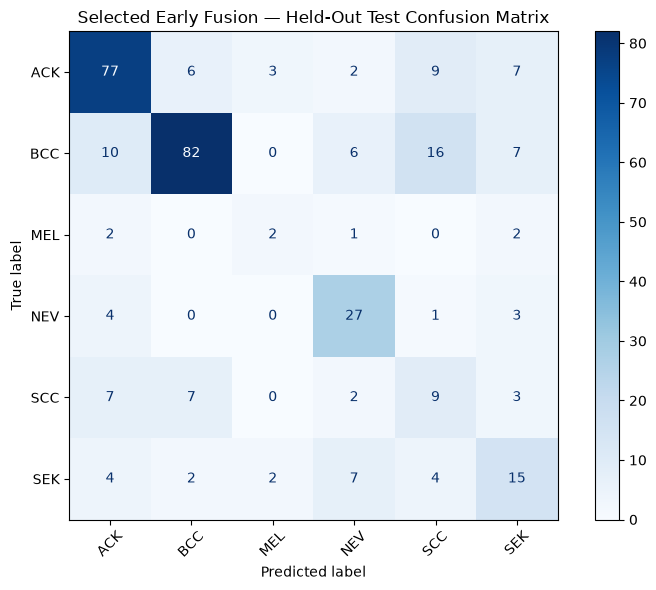


SECTION 14.4 COMPLETED SUCCESSFULLY


In [55]:
#Section 14.4  Evaluate selected early-fusion model

from sklearn.metrics import accuracy_score,balanced_accuracy_score,f1_score,classification_report,ConfusionMatrixDisplay


#Reuse training-fitted image scaler
X_test_img_scaled= fusion_image_scaler.transform(X_test_img)

#Combine modalities using the original fixed weights
X_test_early= np.concatenate(
    [
        X_test_img_scaled / np.sqrt(image_dim),
        X_test_meta_scaled / np.sqrt(metadata_dim)
    ],
    axis=1)

assert X_test_early.shape== (329, 1307)
assert np.isfinite(X_test_early).all()

#Generate predictions without refitting
y_test= test_df["diagnostic"].to_numpy()

test_early_pred= early_fusion_model.predict(X_test_early)

test_early_prob= early_fusion_model.predict_proba(X_test_early)

assert np.isfinite(test_early_prob).all()

assert np.allclose(test_early_prob.sum(axis= 1),1.0)

#Final performance metrics
test_accuracy= accuracy_score(y_test, test_early_pred)

test_balanced_accuracy= balanced_accuracy_score(y_test, test_early_pred)

test_macro_f1= f1_score(y_test,test_early_pred,labels=CLASSES,average="macro",zero_division=0)

print("FINAL HELD-OUT TEST RESULTS — EARLY FUSION")


print(f"Accuracy:{test_accuracy:.4f}")
print(f"Balanced Accuracy:"f"{test_balanced_accuracy:.4f}")
print(f"Macro-F1:{test_macro_f1:.4f}")

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        test_early_pred,
        labels=CLASSES,
        digits=4,
        zero_division=0
    )
)

fig,ax= plt.subplots(figsize= (8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_early_pred,
    labels= CLASSES,
    ax= ax,
    cmap= "Blues",
    xticks_rotation= 45
)

ax.set_title("Selected Early Fusion — Held-Out Test Confusion Matrix")

plt.tight_layout()
plt.show()

print("\nSECTION 14.4 COMPLETED SUCCESSFULLY")

### 14.5 Interpretation of Held-Out Test Performance



In [56]:
#Section 14.5  Corrected patient-clustered bootstrap
#Keep six-class metric definitions consistent.

import numpy as np
import pandas as pd
from sklearn.metrics import  accuracy_score,recall_score,f1_score


test_patients= test_df["patient_id"].to_numpy()
unique_test_patients= np.unique(test_patients)

patient_groups= [
    np.flatnonzero(test_patients==patient)
    for patient in unique_test_patients
]

rng_test= np.random.default_rng(SEED)
N_TEST_BOOTSTRAPS= 2000

bootstrap_accuracy= []
bootstrap_balanced= []
bootstrap_macro_f1= []

excluded_resamples= 0

for _ in range(N_TEST_BOOTSTRAPS):

    sampled_groups= rng_test.integers(
        0,
        len(patient_groups),
        size= len(patient_groups)
    )

    indices= np.concatenate([
        patient_groups[i] for i in sampled_groups
    ])

    actual= y_test[indices]
    predicted= test_early_pred[indices]

    bootstrap_accuracy.append(
        accuracy_score(actual, predicted)
    )

    #Require all six true classes for macro-based metrics
    if set(CLASSES).issubset(set(actual)):

        bootstrap_balanced.append(
            recall_score(
                actual,
                predicted,
                labels= CLASSES,
                average= "macro",
                zero_division= 0
            )
        )

        bootstrap_macro_f1.append(
            f1_score(
                actual,
                predicted,
                labels= CLASSES,
                average= "macro",
                zero_division= 0
            )
        )

    else:
        excluded_resamples+= 1


def percentile_interval(values):
    return np.percentile(values,[2.5, 97.5])


accuracy_ci= percentile_interval(bootstrap_accuracy)

balanced_ci= percentile_interval(bootstrap_balanced)

macro_f1_ci= percentile_interval(bootstrap_macro_f1)

test_ci_summary= pd.DataFrame([
    {
        "Metric": "Accuracy",
        "Observed": test_accuracy,
        "95% CI Lower": accuracy_ci[0],
        "95% CI Upper": accuracy_ci[1]
    },
    {
        "Metric": "Balanced Accuracy",
        "Observed": test_balanced_accuracy,
        "95% CI Lower": balanced_ci[0],
        "95% CI Upper": balanced_ci[1]
    },
    {
        "Metric": "Macro-F1",
        "Observed": test_macro_f1,
        "95% CI Lower": macro_f1_ci[0],
        "95% CI Upper": macro_f1_ci[1]
    }
])

print("CORRECTED FINAL TEST UNCERTAINTY ANALYSIS")


print("Unique test patients:",len(unique_test_patients))
print("Bootstrap iterations:",N_TEST_BOOTSTRAPS)
print("Resamples missing at least one class:",excluded_resamples)
print("Valid six-class resamples:",len(bootstrap_macro_f1))

display(test_ci_summary.round(4))

print("\nSECTION 14.5 COMPLETED SUCCESSFULLY")

CORRECTED FINAL TEST UNCERTAINTY ANALYSIS
Unique test patients: 197
Bootstrap iterations: 2000
Resamples missing at least one class: 10
Valid six-class resamples: 1990


,Metric,Observed,95% CI Lower,95% CI Upper
0,Accuracy,0.6444,0.5823,0.7029
1,Balanced Accuracy,0.5396,0.4617,0.6579
2,Macro-F1,0.5241,0.4451,0.6002



SECTION 14.5 COMPLETED SUCCESSFULLY


### 14.6 Interpretation of Final Test Uncertainty

Patient-clustered bootstraping was done using a test population of 197 independent patients. Out of 2,000 bootstrap resamples 1,990 had all six diagnostic classes and were retained for the class-balanced intervals for metrics.

The selected early-fusion model achieved 64.44% test accuracy (95% bootstrap CI: 58.23%-70.29%) 53.96% balanced accuracy (46.17%to 65.79%) and macro-F1 of 0.5241 (0.4451 to 0.6002).

The performance of minority classes was uncertain. With two of seven melanoma cases were classified resulting in a recall of 28.57%.

The test macro-F1 was 0.1440 less than validation macro-F1 (0.6681) indicating worse generalisation to the unseen dataset. Small number of melanoma patients in the test set and potential differences between patient groups limit confidence in the stability of class-specific estimates.

These bootstrap intervals quantify uncertainty from patient-level resampling conditional on the fitted model.  The balanced-accuracy and macro-F1 intervals depend additionally on having all six classes represented in the resample. They don't capture any variability due to re-training and potenital shifts of performance in external clinical population.

The results show that much larger data samples and independent external validation are needed. This developed classifier is not suitable for clinical diagnosis

### 14.7 Secondary Held-Out Unimodal Comparison
In the original experiment an approach with early fusion using the patient-disjoint validation partition and selected model was evaluated on the held-out-test partition.

As an additional post-hoc analysis the current early-fusion classifier is compared with the already trained baseline classifiers such as metadata-only and image-only baselines on the same test patients.

Neither models are re-trained, nor hyperparameters are modified and results are not going to be used for the selection of the final model.

The goal is to assess whether the development-stage multimodal advantage also appears in the held-out data.

In [57]:
#Section 14.7A  Check existing held-out test variables
#Inspection only: no training, predictions or model changes.

variables_to_check= [
    "X_test_meta",
    "X_test_img",
    "X_test_early",
    "y_test",
    "metadata_model",
    "image_model",
    "early_fusion_model",
    "test_early_pred"
]

print("HELD-OUT COMPARISON  VARIABLE CHECK")


for name in variables_to_check:
    if name in globals():
        obj=globals()[name]
        shape=getattr(obj,"shape","available")
        print(f"{name:25s}: FOUND | {shape}")
    else:
        print(f"{name:25s}: NOT FOUND")

print("\nInspection completed. No models were retrained.")

HELD-OUT COMPARISON  VARIABLE CHECK
X_test_meta              : FOUND | (329, 27)
X_test_img               : FOUND | (329, 1280)
X_test_early             : FOUND | (329, 1307)
y_test                   : FOUND | (329,)
metadata_model           : FOUND | available
image_model              : FOUND | available
early_fusion_model       : FOUND | available
test_early_pred          : FOUND | (329,)

Inspection completed. No models were retrained.


In [58]:
#Section 14.7B  Secondary held-out model comparison
#Post hoc diagnostic analysis; no retraining or tuning.

import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score,balanced_accuracy_score,f1_score

#Predictions from previously trained, unchanged classifiers.
test_meta_pred= metadata_model.predict(X_test_meta)
test_img_indices= image_model.predict(X_test_img)
test_img_pred= np.array(CLASSES)[test_img_indices.astype(int)]

#Existing original early-fusion predictions.
test_early_existing=np.asarray(test_early_pred)

#Verify that all predictions align with held-out observations.
assert len(test_meta_pred)== len(y_test)== 329
assert len(test_img_pred)== len(y_test)
assert len(test_early_existing)== len(y_test)

comparison_predictions= {
    "Metadata-only":test_meta_pred,
    "Image-only":test_img_pred,
    "Early fusion":test_early_existing
}

rows= []

for name, predictions in comparison_predictions.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "Macro-F1": f1_score(
            y_test, predictions,
            labels=CLASSES,
            average="macro",
            zero_division=0
        )
    })

test_comparison=pd.DataFrame(rows).set_index("Model")

print("SECONDARY HELD-OUT MODEL COMPARISON")

display(test_comparison.round(4))

print("\nNo model retraining or hyperparameter changes.")
print("Original early-fusion selection remains unchanged.")

SECONDARY HELD-OUT MODEL COMPARISON


,Accuracy,Balanced accuracy,Macro-F1
Model,,,
Metadata-only,0.5046,0.4554,0.4215
Image-only,0.6140,0.5080,0.5223
Early fusion,0.6444,0.5396,0.5241



No model retraining or hyperparameter changes.
Original early-fusion selection remains unchanged.


### 14.7.1 Interpretation of Secondary Held-Out Comparison

An additional post hoc comparison was made for the original, untouched metadata-only, image-only and early-fusion models on same set of 329 patient-disjoint test images.

The early fusion approach achieved the highest accuracy 0.6444, balanced accuracy 0.5396 and macro-F1 of 0.5241. The test macro-F1 exceeded metadata-only by 0.1026 but was greater than image-only by only 0.0018.

Therefore, although early fusion retained a numerical advantage over both of unimodal baselines its improvement over image-only classification was negligible on the held-out partition. This contrasts sharply with the improvments during the development process.

These finidings indicate that the multimodal advantage was not consistently maintained across the patient partions. No statistical superiority over image-only classification is claimed.

This analysis was conducted after original test evaluation. All the model parameters and selected early-fusion configuration remained unchanged and no additional model selection or tuning was performed.

## 15. Supplementary Robustness and Clinical Evaluation
### 15.1 Patient-Grouped Cross-Validation
### 15.1.1 Objective and Methodology

Original proposal of Project 2.1 suggested conducting experiments to identify the stability of the classification performance remained stable across alternative patient partitions.

The supplementary experiment evaluates three approaches: metadata-only classification, image-only classification using frozen EfficientNet-B0 representations and early feature-level fusion.

The five-fold stratified patient-grouped cross-validation is performed using the combined original training and validation partitions (1,969 images). The held-out test partition (329) remains excluded.

Within each fold patients are assigned exclusively to either of training or validation. Metadata encoding, standardisation and classifiers are fitted using only training-fold observations to prevent preprocessing leakage.

The same frozen image embeddings are used for reducing the computational time without changing the image representation. All the three classifiers are using class-balanced logistic regression with the same principal settings as the original implementations.

For each fold, accuracy, balanced accuracy and macro-F1 scores are provided as well as the mean and standard deviation over folds.

In [59]:
#Section 15.1  Five-fold patient-grouped cross-validation
#Training+validation development data only; test data excluded

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,balanced_accuracy_score,f1_score

#Reuse existing aligned development-set image embeddings.
dev_df= pd.concat([train_df, val_df],ignore_index=True)
dev_img= np.concatenate([X_train_img,X_val_img],axis=0)

dev_labels= dev_df["diagnostic"].to_numpy()
dev_patients= dev_df["patient_id"].to_numpy()

assert len(dev_df)== len(dev_img)== 1969
assert set(dev_patients).isdisjoint(set(test_df["patient_id"]))
assert np.array_equal(
    dev_labels,
    np.concatenate(
        [train_df["diagnostic"].to_numpy(),
         val_df["diagnostic"].to_numpy()]
    )
)

cv= StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED)

cv_records= []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(dev_img, dev_labels, groups=dev_patients),
    start= 1
):
    #Strict patient isolation within each fold.
    train_patient_ids=set(dev_patients[train_idx])
    val_patient_ids=set(dev_patients[val_idx])

    assert train_patient_ids.isdisjoint(val_patient_ids)

    y_fold_train= dev_labels[train_idx]
    y_fold_val= dev_labels[val_idx]

    #Refit metadata preprocessing within each training fold.
    fold_metadata_preprocessor= ColumnTransformer(
        transformers= [
            ("age", StandardScaler(), ["age"]),
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown= "ignore",
                    sparse_output= False
                ),
                CATEGORICAL_FEATURES
            )
        ],
        remainder= "drop"
    )

    fold_meta_train= fold_metadata_preprocessor.fit_transform(
        dev_df.iloc[train_idx][FINAL_METADATA_COLS]
    )

    fold_meta_val= fold_metadata_preprocessor.transform(dev_df.iloc[val_idx][FINAL_METADATA_COLS])

    #Refit image and metadata scalers within each fold.
    fold_image_scaler= StandardScaler()
    fold_metadata_scaler= StandardScaler()

    fold_img_train= fold_image_scaler.fit_transform(dev_img[train_idx])
    fold_img_val= fold_image_scaler.transform(dev_img[val_idx])

    fold_meta_train_scaled= fold_metadata_scaler.fit_transform(fold_meta_train)
    fold_meta_val_scaled= fold_metadata_scaler.transform(fold_meta_val)

    #Reproduce original early-fusion block scaling.
    fold_image_dim= fold_img_train.shape[1]
    fold_metadata_dim= fold_meta_train_scaled.shape[1]

    fold_early_train= np.concatenate(
        [
            fold_img_train/np.sqrt(fold_image_dim),
            fold_meta_train_scaled/np.sqrt(fold_metadata_dim)
        ],
        axis= 1
    )

    fold_early_val= np.concatenate(
        [
            fold_img_val/np.sqrt(fold_image_dim),
            fold_meta_val_scaled/np.sqrt(fold_metadata_dim)
        ],
        axis= 1
    )

    experiments= {
        "Metadata-only": (fold_meta_train, fold_meta_val),
        "Image-only": (fold_img_train, fold_img_val),
        "Early fusion": (fold_early_train, fold_early_val)
    }

    for name,(X_fold_train, X_fold_val) in experiments.items():

        classifier= LogisticRegression(
            max_iter= 3000,
            class_weight= "balanced",
            C= 1.0,
            random_state= SEED
        )

        classifier.fit(X_fold_train,y_fold_train)
        predicted=classifier.predict(X_fold_val)

        cv_records.append({
            "Fold": fold,
            "Model": name,
            "Accuracy": accuracy_score(y_fold_val, predicted),
            "Balanced Accuracy": balanced_accuracy_score(
                y_fold_val, predicted
            ),
            "Macro-F1": f1_score(
                y_fold_val,
                predicted,
                labels=CLASSES,
                average="macro",
                zero_division=0
            ),
            "Training Patients": len(train_patient_ids),
            "Validation Patients": len(val_patient_ids),
            "Validation Melanoma Images": int(
                np.sum(y_fold_val=="MEL")
            )
        })

    print(
        f"Fold {fold}/5 completed | "
        f"train patients: {len(train_patient_ids)} | "
        f"validation patients: {len(val_patient_ids)} | "
        f"melanoma validation images: {np.sum(y_fold_val=='MEL')}"
    )

cv_results_df= pd.DataFrame(cv_records)

print("\nFIVE-FOLD CROSS-VALIDATION RESULTS")
display(cv_results_df.round(4))

cv_summary= (
    cv_results_df
    .groupby("Model")[
        ["Accuracy", "Balanced Accuracy", "Macro-F1"]
    ]
    .agg(["mean", "std"])
    .round(4)
)

print("\nCROSS-VALIDATION SUMMARY")
display(cv_summary)

print("\nSECTION 15.1 COMPLETED SUCCESSFULLY")

Fold 1/5 completed | train patients: 941 | validation patients: 235 | melanoma validation images: 9
Fold 2/5 completed | train patients: 940 | validation patients: 236 | melanoma validation images: 9
Fold 3/5 completed | train patients: 942 | validation patients: 234 | melanoma validation images: 9
Fold 4/5 completed | train patients: 941 | validation patients: 235 | melanoma validation images: 9
Fold 5/5 completed | train patients: 940 | validation patients: 236 | melanoma validation images: 9

FIVE-FOLD CROSS-VALIDATION RESULTS


,Fold,Model,Accuracy,Balanced Accuracy,Macro-F1,Training Patients,Validation Patients,Validation Melanoma Images
0,1,Metadata-only,0.6218,0.6011,0.5377,941,235,9
1,1,Image-only,0.5939,0.4741,0.4871,941,235,9
2,1,Early fusion,0.7056,0.6424,0.6167,941,235,9
3,2,Metadata-only,0.6031,0.5925,0.5173,940,236,9
4,2,Image-only,0.5980,0.5348,0.5369,940,236,9
5,2,Early fusion,0.6972,0.6488,0.6139,940,236,9
6,3,Metadata-only,0.5178,0.4821,0.4403,942,234,9
7,3,Image-only,0.5685,0.5197,0.5211,942,234,9
8,3,Early fusion,0.6726,0.6211,0.5965,942,234,9
9,4,Metadata-only,0.5635,0.5770,0.4977,941,235,9



CROSS-VALIDATION SUMMARY


Accuracy         Balanced Accuracy         Macro-F1        
                  mean     std              mean     std     mean     std
Model                                                                    
Early fusion    0.6892  0.0131            0.6453  0.0460   0.6133  0.0281
Image-only      0.5952  0.0162            0.5081  0.0227   0.5169  0.0185
Metadata-only   0.5795  0.0405            0.5657  0.0480   0.5007  0.0367


SECTION 15.1 COMPLETED SUCCESSFULLY


### 15.1.2 Interpretation of Patient-Grouped Cross-Validation

Five-fold stratified patient-wise cross-validation was performed using 1,969 development images taken from the original training and validation partitions. All the folds maintained patient-level separation and the held-out test partition was excluded.

The experiment compared metadata-only, image-only and early-fusion logistic regression classifiers using accuracy, balanced accuracy and macro-F1. Metadata preprocessing and feature standardisation were fitted separately within the each training fold to reduce the preprocessing leakage.

Early fusion achieved the highest mean macro-F1 of 0.6133 with the standard deviation 0.0281 compared with 0.5169 (0.0185) for image-only classification and 0.5007 (0.0367) for the metadata-only classification.

Morevoer, the highest mean accuracy is of (0.6892) and balanced accuracy (0.6453). Its mean macro-F1 exceeded metadata-only classification by 0.1126 and image-only classification by 0.0964.

Early fusion outerperformed both of the unimodal classifiers in alll of the five validation folds. For early fusion, the macro-F1 score varied from 0.5825 to 0.6572 suggesting that the observed multimodal advantage was reasonably consistent across these development partitions altough performance varied between the patient groups.

There were nine melanoma images in each validation fold. Due to the relatively low number of samples in thsi class performance should be treated carefully. Stratified group splitting preserves patient separation but it does not eliminate class imbalance or dataset-specific assosciations.

The mean macro-F1 score of 0.6133 in cross-validation was smaller than the macro-F1 score of 0.6681 for initial validation procedure. This difference highlights the importance of testing the models in several development folds. However, the estimates above are based on different training and validation sets and cannot be directly compared.

These findings support the previous conclusions about the advantage of early fusion over the unimodal methods used in PAD-UFES-20. However, they do not establish superiority over the late or intermediate gated fusion which were not evaluated in this supplementary cross-validation experiment.

This analysis remains internal to the development dataset and does not establish robustness across external clinical populations. The previously selcted early-fusion model and its held-out test results remain unchanged.

## 15.2 Conservative versus Fuller Metadata Ablation
### 15.2.1 Objective and Experimental Design
The original Project 2.1 proposal planned a controlled comparison of the conservative and fuller clinical metadata configurations.

The main implementation  retained the six consistently available features such as age, lesion region, itching, pain, bleeding and elevation. The above choice reduces dependency on systematically missing attributes related to the diagnosis and biopsy status.

This supplementary experiment following question is explored: whether adding more clinical attributes can improve predictions or potenitally encourages dataset-specific shortcuts learning.

The following two metadata configurations are considered
1. **Conservative configuration:** Age, region, itch, hurt, bleed and elevation.
2. **Fuller configuration:** The six conservative features plus gender, personal skin-cancer history and two lesion-diameter measurements.

These additional variables were selected to provide demographic, hisotrical and lesion-size information. They also belong to the systematically missing group identified earlier making comparison informative for investigating missingness-related bias.

The experiment evaluates bot metadata-only logistic regression and early feature-level fusion using five-fold stratified patient-grouped cross-validation.

All the preprocessing procedures, including numerical imputation, categorical missing values treatment, encoding and standardization are estimated independently on each training fold. Missingness indicators are retained for newly included numerical and categorical attributes.

The original training and validation partitions from the development dataset. The held-out test partition is excluded from this experimnt.

Accuracy, balanced accuracy and macro-F1 are compared between the folds. Any potential improvement due to the fuller metadata will be evaluated cautiously because added variables may capture documentation or biopsy-related patterns rather than generalisable clinical information.

This experiment is supplementary and does not change the previously selected final early-fusion model.

In [60]:
#Section 15.2  Conservative versus fuller metadata ablation
#Five-fold patient-grouped cross-validation
#Development data only  held-out test excluded

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score,balanced_accuracy_score,f1_score


#1. Define conservative and fuller feature sets


conservative_features= [ "age", "region", "itch", "hurt", "bleed", "elevation"]

additional_numeric= ["diameter_1", "diameter_2"]
additional_categorical= ["gender", "skin_cancer_history"]

fuller_features= (conservative_features+ additional_numeric+ additional_categorical)

assert set(fuller_features).issubset(dev_df.columns)

assert len(dev_df)== 1969
assert len(dev_img)== len(dev_df)

assert set(dev_df["patient_id"]).isdisjoint(
    set(test_df["patient_id"]))

#Work on development data only.
#Do not modify the original train_df or val_df.
ablation_df= dev_df.copy()

#Normalise numeric columns without learning statistics.
for col in ["age"]+additional_numeric:
    ablation_df[col]= pd.to_numeric(ablation_df[col],errors="coerce")

#Use an explicit missing category for additional fields.
#Retain original conservative-feature values.
for col in additional_categorical:
    ablation_df[col] = (
        ablation_df[col]
        .astype("string")
        .fillna("MISSING")
        .astype(str)
    )


#2. Fold-specific metadata preprocessing

def make_ablation_preprocessor(config):

    if config== "Conservative":
        return ColumnTransformer(
            transformers=[
                (
                    "age",
                    StandardScaler(),
                    ["age"]
                ),
                (
                    "categorical",
                    OneHotEncoder(
                        handle_unknown="ignore",
                        sparse_output=False
                    ),
                    ["region", "itch", "hurt", "bleed", "elevation"]
                )
            ],
            remainder="drop"
        )

    if config== "Fuller":
        return ColumnTransformer(
            transformers=[
                (
                    "age",
                    StandardScaler(),
                    ["age"]
                ),
                (
                    "diameters",
                    Pipeline([
                        (
                            "imputer",
                            SimpleImputer(
                                strategy= "median",
                                add_indicator= True
                            )
                        ),
                        (
                            "scaler",
                            StandardScaler()
                        )
                    ]),
                    additional_numeric
                ),
                (
                    "categorical",
                    OneHotEncoder(
                        handle_unknown= "ignore",
                        sparse_output= False
                    ),
                    [
                        "region", "itch", "hurt",
                        "bleed", "elevation",
                        "gender", "skin_cancer_history"
                    ]
                )
            ],
            remainder= "drop"
        )

    raise ValueError("Unknown metadata configuration")

#3.Cross-validation


ablation_cv= StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED)

ablation_results= []

ablation_y= ablation_df["diagnostic"].to_numpy()
ablation_groups= ablation_df["patient_id"].to_numpy()

for fold, (train_idx, val_idx) in enumerate(
    ablation_cv.split(
        ablation_df,
        ablation_y,
        groups=ablation_groups
    ),
    start=1
):

    #Verify patient isolation.
    assert set(
        ablation_groups[train_idx]
    ).isdisjoint(
        set(ablation_groups[val_idx])
    )

    y_train_fold= ablation_y[train_idx]
    y_val_fold= ablation_y[val_idx]

    #Train-only image scaling shared by configurations.
    img_scaler= StandardScaler()

    img_train= img_scaler.fit_transform(
        dev_img[train_idx]
    )

    img_val= img_scaler.transform(
        dev_img[val_idx]
    )

    for config, features in [
        ("Conservative", conservative_features),
        ("Fuller", fuller_features)
    ]:

        preprocessor= make_ablation_preprocessor(config)

        #Fit transformations only using the training fold.
        meta_train= preprocessor.fit_transform(ablation_df.iloc[train_idx][features])

        meta_val=preprocessor.transform(ablation_df.iloc[val_idx][features])

        meta_train= np.asarray(meta_train,dtype=np.float64)

        meta_val= np.asarray(meta_val,dtype=np.float64)

        assert meta_train.shape[1]== meta_val.shape[1]
        assert np.isfinite(meta_train).all()
        assert np.isfinite(meta_val).all()

        #Reproduce block scaling used in original early fusion.
        meta_scaler= StandardScaler()

        meta_train_scaled= meta_scaler.fit_transform(meta_train)

        meta_val_scaled= meta_scaler.transform(meta_val)

        image_dim_fold= img_train.shape[1]
        metadata_dim_fold= meta_train_scaled.shape[1]

        early_train= np.concatenate(
            [
                img_train/np.sqrt(image_dim_fold),
                meta_train_scaled/np.sqrt(metadata_dim_fold)
            ],
            axis= 1
        )

        early_val= np.concatenate(
            [
                img_val/np.sqrt(image_dim_fold),
                meta_val_scaled/np.sqrt(metadata_dim_fold)
            ],
            axis= 1
        )

        experiments= [("Metadata-only", meta_train, meta_val),("Early fusion", early_train, early_val)]

        for model_name,X_tr,X_va in experiments:

            model= LogisticRegression(
                max_iter= 3000,
                class_weight= "balanced",
                C= 1.0,
                random_state= SEED
            )

            model.fit(X_tr,y_train_fold)

            predictions= model.predict(X_va)

            ablation_results.append({
                "Fold":fold,
                "Configuration":config,
                "Model":model_name,
                "Accuracy":accuracy_score(
                    y_val_fold,predictions
                ),
                "Balanced Accuracy":balanced_accuracy_score(
                    y_val_fold,predictions
                ),
                "Macro-F1":f1_score(
                    y_val_fold,
                    predictions,
                    labels=CLASSES,
                    average="macro",
                    zero_division=0
                ),
                "Metadata Dimensions": metadata_dim_fold,
                "Melanoma Validation Images": int(
                    np.sum(y_val_fold == "MEL")
                )
            })

    print(f"Fold {fold}/5 completed")


#4.Results and comparisons


ablation_results_df= pd.DataFrame(ablation_results)

print("\nMETADATA ABLATION  FOLD RESULTS")
display(ablation_results_df.round(4))

ablation_summary= (
    ablation_results_df
    .groupby(["Model", "Configuration"])[
        ["Accuracy", "Balanced Accuracy", "Macro-F1"]
    ]
    .agg(["mean", "std"])
    .round(4)
)

print("\nMETADATA ABLATION  SUMMARY")
display(ablation_summary)

#Paired comparisons across identical patient folds.
paired_ablation = ablation_results_df.pivot(
    index=["Fold", "Model"],
    columns="Configuration",
    values="Macro-F1"
)

paired_ablation["Fuller minus Conservative"]=( paired_ablation["Fuller"] - paired_ablation["Conservative"])

print("\nPAIRED FOLD-LEVEL MACRO-F1 DIFFERENCES")
display(paired_ablation.round(4))

print("\nMEAN DIFFERENCE BY MODEL")
display(
    paired_ablation
    .groupby(level="Model")[
        "Fuller minus Conservative"
    ]
    .agg(["mean", "std"])
    .round(4)
)

print("\nSECTION 15.2 COMPLETED SUCCESSFULLY")

Fold 1/5 completed
Fold 2/5 completed
Fold 3/5 completed
Fold 4/5 completed
Fold 5/5 completed

METADATA ABLATION  FOLD RESULTS


,Fold,Configuration,Model,Accuracy,Balanced Accuracy,Macro-F1,Metadata Dimensions,Melanoma Validation Images
0,1,Conservative,Metadata-only,0.6218,0.6011,0.5377,27,9
1,1,Conservative,Early fusion,0.7056,0.6424,0.6167,27,9
2,1,Fuller,Metadata-only,0.6777,0.6936,0.6230,37,9
3,1,Fuller,Early fusion,0.7310,0.6860,0.6469,37,9
4,2,Conservative,Metadata-only,0.6031,0.5925,0.5173,27,9
5,2,Conservative,Early fusion,0.6972,0.6488,0.6139,27,9
6,2,Fuller,Metadata-only,0.6336,0.6453,0.5588,37,9
7,2,Fuller,Early fusion,0.7354,0.6914,0.6679,37,9
8,3,Conservative,Metadata-only,0.5178,0.4821,0.4403,27,9
9,3,Conservative,Early fusion,0.6726,0.6211,0.5965,27,9



METADATA ABLATION  SUMMARY


Accuracy         Balanced Accuracy          \
                                mean     std              mean     std   
Model         Configuration                                              
Early fusion  Conservative    0.6892  0.0131            0.6453  0.0460   
              Fuller          0.7197  0.0266            0.6912  0.0307   
Metadata-only Conservative    0.5795  0.0405            0.5657  0.0480   
              Fuller          0.6394  0.0404            0.6468  0.0384   

                            Macro-F1          
                                mean     std  
Model         Configuration                   
Early fusion  Conservative    0.6133  0.0281  
              Fuller          0.6576  0.0162  
Metadata-only Conservative    0.5007  0.0367  
              Fuller          0.5734  0.0381


PAIRED FOLD-LEVEL MACRO-F1 DIFFERENCES


Configuration       Conservative  Fuller  Fuller minus Conservative
Fold Model                                                         
1    Early fusion         0.6167  0.6469                     0.0302
     Metadata-only        0.5377  0.6230                     0.0853
2    Early fusion         0.6139  0.6679                     0.0539
     Metadata-only        0.5173  0.5588                     0.0415
3    Early fusion         0.5965  0.6484                     0.0520
     Metadata-only        0.4403  0.5192                     0.0789
4    Early fusion         0.6572  0.6810                     0.0238
     Metadata-only        0.4977  0.5854                     0.0877
5    Early fusion         0.5825  0.6437                     0.0612
     Metadata-only        0.5104  0.5807                     0.0703


MEAN DIFFERENCE BY MODEL


,mean,std
Model,,
Early fusion,0.0442,0.0162
Metadata-only,0.0727,0.0187



SECTION 15.2 COMPLETED SUCCESSFULLY


### 15.2.2 Interpretation of Metadata Ablation


### 15.3 Supplementary Malignant-Lesion Sensitivity Analysis
#### 15.3.1 Objective and Evaluation Design

The original project 2.1 proposal included a complementary binary cancer-sensitivity evaluation. This supplementary analysis derives a malignant-versus-benign classification from the predictions of previously selected six-class early-fusion model.

Basal cell carcinoma (BCC), melanoma (MEL) and the squamous cell carcinoma (SCC) are treated as the malignant categories. Melanocytic nevus (NEV) and the seborrheic keratosis (SEK) are treated as benign categories.

Actinic keratosis (ACK) is excluded from the binary reference population because its a precancerous condition and should not be assumed to be unequivocally benign. Predictions of the ACK for included cases are treated as negative for the defined malignant classes.

The analysis reports sensitivity, specificity, precision, F1-score and confusion matrix. It also identifies malignant lesions incorrectly classified as non-malignant.

The evlauation uses the predictions from the existing selected model without retraining changing thresholds or selecting  a new classifier. As a supplementary analysis performed after original test evaluation its findings are descriptive and do not constitute an independent clinical validation.

SUPPLEMENTARY MALIGNANT-LESION EVALUATION
Total test images: 329
Excluded true ACK images: 104
Eligible images: 225
Malignant reference cases: 156
Benign reference cases: 69

Confusion matrix:
TN: 60 | FP: 9
FN: 40 | TP: 116

Sensitivity:0.7436
Specificity:0.8696
Precision:0.9280
Binary F1:0.8256


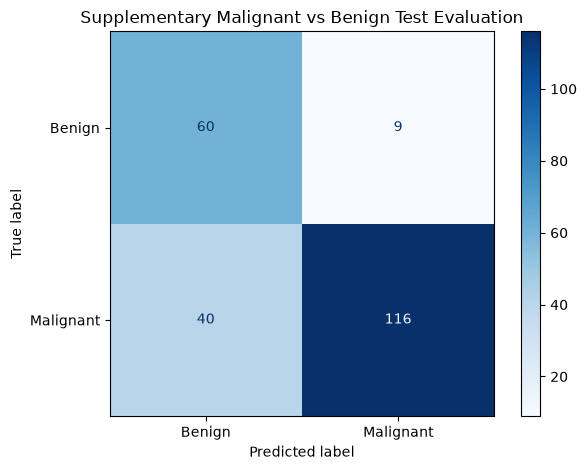


MISSED MALIGNANT CASES BY ORIGINAL SIX-CLASS LABEL


Predicted diagnosis,ACK,NEV,SEK
True diagnosis,,,
BCC,10,6,7
MEL,2,1,2
SCC,7,2,3



SECTION 15.3 COMPLETED SUCCESSFULLY


In [61]:
#Section 15.3  Supplementary malignant-lesion sensitivity
#Existing selected model only; no retraining or model selection

import numpy as np
import pandas as pd

from sklearn.metrics import confusion_matrix,recall_score,precision_score,f1_score,ConfusionMatrixDisplay
import matplotlib.pyplot as plt

MALIGNANT_CLASSES= {"BCC", "MEL", "SCC"}
BENIGN_CLASSES= {"NEV", "SEK"}

#Use existing final test labels and predictions
binary_true_classes= test_df["diagnostic"].to_numpy()
binary_pred_classes= np.asarray(test_early_pred)

assert len(binary_true_classes)== len(binary_pred_classes)==329
assert set(binary_true_classes).issubset(set(CLASSES))
assert set(binary_pred_classes).issubset(set(CLASSES))

#Exclude true ACK cases, as ACK is precancerous
eligible_mask= np.isin(binary_true_classes,list(MALIGNANT_CLASSES | BENIGN_CLASSES))

eligible_true= binary_true_classes[eligible_mask]
eligible_pred= binary_pred_classes[eligible_mask]

#A predicted ACK is negative for the defined malignant categories
y_true_binary=np.isin(eligible_true, list(MALIGNANT_CLASSES)).astype(int)

y_pred_binary= np.isin(eligible_pred, list(MALIGNANT_CLASSES)).astype(int)

cm= confusion_matrix(y_true_binary,y_pred_binary,labels=[0, 1])

tn,fp,fn,tp= cm.ravel()

sensitivity= recall_score( y_true_binary,y_pred_binary,pos_label=1)

specificity= tn/(tn+fp)

precision= precision_score(y_true_binary,y_pred_binary,pos_label=1,zero_division=0)

binary_f1= f1_score(y_true_binary,y_pred_binary,pos_label=1)

print("SUPPLEMENTARY MALIGNANT-LESION EVALUATION")


print("Total test images:",len(binary_true_classes))
print("Excluded true ACK images:",int((~eligible_mask).sum()))
print("Eligible images:",len(eligible_true))
print("Malignant reference cases:",int(y_true_binary.sum()))
print("Benign reference cases:",int((1-y_true_binary).sum()))

print("\nConfusion matrix:")
print("TN:",tn, "| FP:",fp)
print("FN:",fn, "| TP:",tp)

print(f"\nSensitivity:{sensitivity:.4f}")
print(f"Specificity:{specificity:.4f}")
print(f"Precision:{precision:.4f}")
print(f"Binary F1:{binary_f1:.4f}")


#Plot supplementary malignant-versus-benign confusion matrix

disp= ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Benign", "Malignant"])
disp.plot(cmap="Blues")
disp.ax_.set_title("Supplementary Malignant vs Benign Test Evaluation")
plt.tight_layout()
plt.show()

# Inspect the six-class predictions for missed malignant cases
missed_malignant=pd.crosstab(
    eligible_true[(y_true_binary== 1) & (y_pred_binary== 0)],
    eligible_pred[(y_true_binary== 1) & (y_pred_binary== 0)],
    rownames= ["True diagnosis"],
    colnames= ["Predicted diagnosis"]
)

print("\nMISSED MALIGNANT CASES BY ORIGINAL SIX-CLASS LABEL")
display(missed_malignant)

print("\nSECTION 15.3 COMPLETED SUCCESSFULLY")

#### 15.3.2 Interpretation of Malignant-Lesion Sensitivity
The supplementary analysis examines the early-fusion classifier by deriving a malignant-versus-benign decision from its original six-class predictions.

The malignant classes are BCC, MEL  and SCC, while NEV and SEK are benign. The 104 test images with the true ACK labels were excluded because ACK is a precancerous condition and does not fit unambiguously into the selected binary reference groups. Predicted ACK labels for eligible cases were treated as negative for defined malignant categories.

Therefore, the total number of test images included in the analysis were 225: 156 reference cases with malignant and 69 refrence cases with benign labels.

The classifier correctly classified 116 malignant cases and misclassified 40 which gives the sensitivity of 74.36%. On the other hand, out of 69 benign cases 60 were correctly classified and remaining nine cases were misclassified as malignant leading to the specificty of 86.96%.

The precision for malignant-class is 92.80% and binary F1-score is 0.8256. Despite above performance it is essential to emphasize 40 malignant cases that were missed.

In the false negative group there were 23 BCCS, five MELS and 12 SCCS. The missed malignant cases were assigned original six-class predictions of ACK, NEV or SEK.

Even though the binary sensitivity was higher than the six-class balanced accuracy the two metrics represent different approaches and cannot be substituted for each other. The binary analysis combines several diagnostic classes and excludes true ACK cases making the task less granular than the original six-class classification.

The high malignant precision must also be interpreted in the context of the evaluated class distribution which contained 156 malignant and 69 benign reference observations. Predictive values may differ in populations with different disease prevalence.

Importantly, this experiment did not train or independently validate a binary cancer-detection model. It retrospectively grouped predictions of the selected six-class classifier without threshold optimisation.

Thus, the presented results bring the safety approach to the evaluation of the six-class classifier. However, missing malignant cancers, low number of melanomas, limited diagnostic mapping and lack of validation preclude the use of the results in the clinical practice.

Our developed classifier remains an educational research prototype and must not be used for clinical diagnosis or treatment decisions.

## 16. Conclusions and Reproducibility
### 16.1 Project Conclusions
This project developed and evaluated a multimodal skin-lesion classification pipeline using PAD-UFES-20 clinical photographs and structured patient metadata. The primary goal of this work is to investigate whether combining two modalities results in better six-classification compared to sinle-modal methods.

There are five types of models to consider: logistic regression for metadata-only, image-only classification using frozen EfficientNet-B0 embeddings, early feature-level-fusion, late probability-level fusion and intermediate metadata-conditioned gated fusion.

The Early fusion achieved the highest original validation macro-F1 (0.6681) and balanced accuracy of 0.7131 moreover outperforming both unimodal baselines and late fusion. Its macro-F1 improvement over metadata-only classification was 0.1429 with a patient-clustered 95% bootstrap interval of 0.0709-0.2072. However, its advantage over intermediate gated fusion was small (0.0145) with a bootstrap interval spanning zero.

The conservative early fusion model achieved the accuracy of 64.44%, 53.96% balanced accuracy and macro-F1 of 0.5241 on the held-out patient-disjoint test partition. This represented a macro-F1 decrease of 0.1440 relative to the original validation partition. Melanoma recall was only about 28.57% (2/7) indicating limited generalisation and substantial uncertainty for rare diagnostic categories.

Three key supplementary analyses are briefly described below: patient-grouped cross-validation, conservative versus fuller metadata ablation and malignant versus benign sensitivity estimation. Configuration sensitivity (Section 7.6), demographic subgroup performance (Section 7.7) and the gated-fusion training stability (Section 9.3A) are discussed separately in the concluding synthesis.

First, five-fold cross-vlaidation of the development set by patients showed that early fusion scored 0.6133 macro-F1 (standard deviation=0.0281) while image-only and metadata-only classifiers scored 0.5169 and 0.5007 respectively. Early fusion outperformed both models in each fold.

Second, the metadata feature ablation showed that by adding gender, skin-cancer history and lesion-diameter attributes increased early-fusion mean cross-validation macro-F1 from 0.6133 to 0.6576. However, metadata missingness was found to be assosciated with diagnosis and biopsy status thus gained improvement can be caused by dataset-related documentation rather than clinically generalisable information.

Third, supplementary analysis of the model's test predictions on malignant versus benign classes showed 74.36% sensitivity and 86.96% specificity for 225 test images suitable for the analysis exluding 104 actinic keratosis cases. 40 out of 156 malignant reference cases could not be detected by the model using the specified grouping criteria which highlights some important limitatiosn despite the high bianry F1-score.

Further analyses revealed informative contribution of both modalities, metadata missingness related to diagnosis and overfitting of the intermediate gated model.

Overall, early fusion improved development-stage performance but its held-out advantage over image-only classification was negligible (0.5241 versus 0.5223; Section 14.8). Supplementary analyses showed sensitivity to fusion scaling and regularisation (Section 7.6), gated-fusion variability across seeds (Section 9.3A) and descriptive subgroup differences (Section 7.7). These findings do not establish improved clinical generalisability. Classifier remains an educational research prototype unsuitable for clinical diagnosis.



### 16.2 Limitations and Future Work

The major limitations include the small sample size means small dataset, severe class imbalance, limited melanoma representation, variation in clinical image acquisition and possible assosciations between diagnosis, biopsy and metadata availability.

The visual pipeline utilized frozen ImageNet-pretrained EfficientNet-B0 representatiosn rather than task-specific fine tuning. Stochastic training-time image augmentation was not implemented limiting direct evaluation of robustness to image appearance variation.

While patient-grouped cross-validation was performed for metadata-only, image-only and early fusion models no late and intermediate gated fusion models were included in this supplementary cross-validation experiment. The presented reuslts do not confirm the relative stability of all five methods under multiple random partitions of patients.

The fuller-metadata ablation added the multiple attributes simultaneously and incorporated the missing-value representations. Consequently, experiment could not distinguish predictive value fo clinical attributes from influence of systematic documentation patterns. Improvements within the development dataset should not be interpreted as evidence of improved external clinical generalisability.

The supplementary analysis of malignant and benign lesions did not include true instances of actinic keratosis and assumed that predicted keratosis was a negative case in the chosen malignant groups. Hence, it depends on particular diagnostic group and is not comparable to an independent cancer classifier trained separately.

Without an independent external clinical dataset all experiments were based on PAD-UFES-20. The grouped cross-validation assessed the variation acorss development partitions, whereas Patient-clustered bootstrap intervals quantified evaluation uncertainty conditional on fitted models. Neither of the approach established generalisability acorss healthcare settings or the demographic populations.

Future work should focus on independent external validation, increased data size and representation, assesment across patient subgroups and clinical image acquisition conditions adn improved minority-class performance.

Further investigations could compare clinical-value features against the missingness-only indicators, apply controlled training-time augmentation and backbone fine-tuning, evaluate calibrated uncertainty and extend grouped cross-validation to late and intermediate fusion.

Before any clinical consideration the system would require substantially stronger malignant-lesion sensitivity, rigorous external validation, appropriate governance and prospective clinical evaluation.

In [62]:
#Section 16.3  Saved model reproducibility audit

import joblib
import numpy as np
from pathlib import Path

model_path= FINAL_DIR/"early_fusion_model.joblib"
weights_path= FINAL_DIR/"efficientnet_feature_extractor.pt"
selection_path= FINAL_DIR/"model_selection.json"

assert model_path.is_file(),"Saved classifier not found"
assert weights_path.is_file(),"Saved image encoder not found"
assert selection_path.is_file(),"Selection record not found"

#Reload saved model artifacts
reloaded_artifacts= joblib.load(model_path)

required_keys= ["metadata_preprocessor","image_scaler","metadata_scaler","classifier","classes","selected_features","image_dim","metadata_dim"]

assert all(key in reloaded_artifacts for key in required_keys)

#Independently transform test features using saved components
reloaded_meta= reloaded_artifacts[
    "metadata_preprocessor"
].transform(
    test_df[reloaded_artifacts["selected_features"]]
)

reloaded_meta= reloaded_artifacts["metadata_scaler"].transform(reloaded_meta)

reloaded_img= reloaded_artifacts["image_scaler"].transform(X_test_img)

reloaded_fusion= np.concatenate(
    [
        reloaded_img/np.sqrt(
            reloaded_artifacts["image_dim"]
        ),
        reloaded_meta/np.sqrt(
            reloaded_artifacts["metadata_dim"]
        )
    ],
    axis= 1
)

reloaded_predictions= reloaded_artifacts["classifier"].predict(reloaded_fusion)

#Confirm identical predictions
assert np.array_equal(reloaded_predictions,test_early_pred), "Saved model predictions differ!"

print("SAVED MODEL REPRODUCIBILITY AUDIT")

print("Classifier artifact exists: True")
print("Encoder weights exist: True")
print("Selection record exists: True")

print("\nReloaded feature shape:", reloaded_fusion.shape)

print("Predictions identical:",np.array_equal( reloaded_predictions,test_early_pred))

print("\nSECTION 16.3 COMPLETED SUCCESSFULLY")

SAVED MODEL REPRODUCIBILITY AUDIT
Classifier artifact exists: True
Encoder weights exist: True
Selection record exists: True

Reloaded feature shape: (329, 1307)
Predictions identical: True

SECTION 16.3 COMPLETED SUCCESSFULLY


In [63]:
#Section 16.4  Environment and experiment documentation

import json
import platform
import sys
import sklearn
import torchvision
import matplotlib
import numpy as np
import pandas as pd

#Summarise the completed supplementary experiments
cv_early= cv_results_df[
    cv_results_df["Model"]== "Early fusion"
]["Macro-F1"]

fuller_early= ablation_results_df[
    (ablation_results_df["Model"]== "Early fusion")
    & (ablation_results_df["Configuration"]== "Fuller")
]["Macro-F1"]

conservative_early= ablation_results_df[
    (ablation_results_df["Model"]== "Early fusion")
    & (ablation_results_df["Configuration"]== "Conservative")
]["Macro-F1"]

assert len(cv_early)== 5
assert len(fuller_early)== 5
assert len(conservative_early)== 5

experiment_manifest= {
    "project": "PAD-UFES-20 Multimodal Classification",
    "dataset_images":2298,
    "training_images":len(train_df),
    "validation_images":len(val_df),
    "test_images":len(test_df),
    "random_seed":SEED,

    #Original validation-selected final model
    "selected_model":"Early fusion",
    "image_backbone":"EfficientNet-B0",
    "image_dimensions":int(image_dim),
    "metadata_dimensions":int(metadata_dim),
    "fusion_dimensions":int(image_dim + metadata_dim),
    "validation_macro_f1":float(early_macro_f1),
    "test_macro_f1":float(test_macro_f1),
    "test_accuracy":float(test_accuracy),
    "test_balanced_accuracy":float(test_balanced_accuracy),

    #Supplementary development-set experiments
    "supplementary_experiments": [
        "Five-fold patient-grouped cross-validation",
        "Conservative versus fuller metadata ablation",
        "Derived malignant-versus-benign sensitivity analysis"
    ],
    "cross_validation_folds": 5,
    "cross_validation_early_fusion_macro_f1_mean": float(
        cv_early.mean()
    ),
    "cross_validation_early_fusion_macro_f1_std": float(
        cv_early.std()
    ),
    "conservative_early_fusion_cv_macro_f1_mean": float(
        conservative_early.mean()
    ),
    "fuller_early_fusion_cv_macro_f1_mean": float(
        fuller_early.mean()
    ),

    #Derived analysis of existing test predictions
    "binary_analysis_type": "Post hoc malignant-versus-benign",
    "binary_true_ACK_excluded":True,
    "binary_eligible_test_images":int(len(eligible_true)),
    "binary_sensitivity":float(sensitivity),
    "binary_specificity":float(specificity),
    "binary_precision":float(precision),
    "binary_f1":float(binary_f1),
    "binary_false_negatives":int(fn),

    #Execution environment
    "python":sys.version.split()[0],
    "pytorch":torch.__version__,
    "torchvision":torchvision.__version__,
    "numpy":np.__version__,
    "pandas":pd.__version__,
    "scikit_learn":sklearn.__version__,
    "matplotlib":matplotlib.__version__,
    "operating_system":platform.system(),
    "compute_device":str(DEVICE)
}

manifest_path= FINAL_DIR/"experiment_manifest.json"

with open(manifest_path,"w") as file:
    json.dump(experiment_manifest,file,indent=4)

print("EXPERIMENT CONFIGURATION")


for key, value in experiment_manifest.items():
    print(f"{key}:{value}")

print("\nManifest saved:", manifest_path)
print("\nSECTION 16.4 COMPLETED SUCCESSFULLY")

EXPERIMENT CONFIGURATION
project:PAD-UFES-20 Multimodal Classification
dataset_images:2298
training_images:1640
validation_images:329
test_images:329
random_seed:42
selected_model:Early fusion
image_backbone:EfficientNet-B0
image_dimensions:1280
metadata_dimensions:27
fusion_dimensions:1307
validation_macro_f1:0.6680725162776784
test_macro_f1:0.524097401127678
test_accuracy:0.6443768996960486
test_balanced_accuracy:0.5396364108262505
supplementary_experiments:['Five-fold patient-grouped cross-validation', 'Conservative versus fuller metadata ablation', 'Derived malignant-versus-benign sensitivity analysis']
cross_validation_folds:5
cross_validation_early_fusion_macro_f1_mean:0.6133431920945698
cross_validation_early_fusion_macro_f1_std:0.028141518844803728
conservative_early_fusion_cv_macro_f1_mean:0.6133431920945698
fuller_early_fusion_cv_macro_f1_mean:0.6575663684198931
binary_analysis_type:Post hoc malignant-versus-benign
binary_true_ACK_excluded:True
binary_eligible_test_images:225

In [64]:
#Section 16.5  Final output-file verification

from pathlib import Path

required_artifacts= [
    FINAL_DIR/"early_fusion_model.joblib",
    FINAL_DIR/"efficientnet_feature_extractor.pt",
    FINAL_DIR/"model_selection.json",
    FINAL_DIR/"experiment_manifest.json",
    OUTPUT_DIR/"efficientnet_b0_train_val_features.npz"
]

print("FINAL PROJECT ARTIFACT CHECK")

all_present= True

for path in required_artifacts:
    exists= path.is_file()
    all_present= all_present and exists

    print(
        f"{'PASS' if exists else 'MISSING'} — "
        f"{path.name}"
    )

assert all_present, "Required project artifacts are missing."

print("\nAll required saved artifacts are present.")
print("SECTION 16.5 COMPLETED SUCCESSFULLY")

FINAL PROJECT ARTIFACT CHECK
PASS — early_fusion_model.joblib
PASS — efficientnet_feature_extractor.pt
PASS — model_selection.json
PASS — experiment_manifest.json
PASS — efficientnet_b0_train_val_features.npz

All required saved artifacts are present.
SECTION 16.5 COMPLETED SUCCESSFULLY


### 16.6 End-to-End Saved-Model Verification

The saved EfficientNet-B0 encoder, metadata preprocessing, modality scalers and early-fusion classifier are reloaded independently.

Raw held-out photographs are processesd again to generate fresh image embeddings. Reconstructed predictions are compared with the original held-out predictions without retraining or model selection.

This evaluates reproducibility of saved prediction pipeline, not external clinical generalisability.

In [65]:
#Section 16.6  End-to-End Saved-Model Verification
#Fresh raw-image extraction using the SAVED encoder weights.
#No retraining or model selection.

import numpy as np
import joblib
import torch
import torch.nn as nn

from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.models import efficientnet_b0
from sklearn.metrics import accuracy_score,balanced_accuracy_score,f1_score


#1. Load the saved classifier and preprocessing components.
saved_artifacts= joblib.load(
    FINAL_DIR / "early_fusion_model.joblib"
)

#2. Create a fresh EfficientNet-B0 without downloading weights.
fresh_backbone= efficientnet_b0(weights=None)

fresh_encoder= nn.Sequential(
    fresh_backbone.features,
    fresh_backbone.avgpool,
    nn.Flatten(1)
)

#Load the exact frozen encoder saved in Section 14.1.
saved_encoder_state= torch.load(
    FINAL_DIR/"efficientnet_feature_extractor.pt",
    map_location= "cpu",
    weights_only= True
)

fresh_encoder.load_state_dict(
    saved_encoder_state,
    strict= True
)

fresh_encoder= fresh_encoder.to("cpu")
fresh_encoder.eval()

for parameter in fresh_encoder.parameters():
    parameter.requires_grad=False

#3. Reconstruct the original deterministic transformations.
fresh_transform= transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

#SkinLesionDataset was defined in Section 6.2.1.
#It handles RGBA-to-RGB conversion on a white background.
fresh_test_dataset= SkinLesionDataset(test_df,image_paths, fresh_transform)

fresh_test_loader= DataLoader(fresh_test_dataset,batch_size=16,shuffle=False,num_workers=0)

#4. Generate new embeddings directly from raw test photographs.
fresh_embeddings= []
fresh_labels= []

with torch.inference_mode():
    for batch_images, batch_labels in fresh_test_loader:
        features=fresh_encoder(batch_images)

        fresh_embeddings.append(
            features.cpu().numpy()
        )

        fresh_labels.append(
            batch_labels.numpy()
        )

fresh_embeddings= np.concatenate(fresh_embeddings,axis=0)

fresh_labels= np.concatenate(fresh_labels,axis=0)

assert fresh_embeddings.shape== (329, 1280)
assert np.isfinite(fresh_embeddings).all()

assert np.array_equal(
    fresh_labels,
    test_df["diagnostic"].map(
        CLASS_TO_IDX
    ).to_numpy()
)

#5. Reload and apply the original metadata preprocessing.
fresh_metadata_raw= test_df[saved_artifacts["selected_features"]].copy()

fresh_metadata= saved_artifacts["metadata_preprocessor"].transform(fresh_metadata_raw)

fresh_metadata_scaled= saved_artifacts["metadata_scaler"].transform(fresh_metadata)

#6. Apply the saved image scaling.
fresh_image_scaled= saved_artifacts["image_scaler"].transform(fresh_embeddings)

#7. Reconstruct the original early-fusion representation.
fresh_fusion= np.concatenate(
    [
        fresh_image_scaled / np.sqrt(
            saved_artifacts["image_dim"]
        ),
        fresh_metadata_scaled / np.sqrt(
            saved_artifacts["metadata_dim"]
        )
    ],
    axis=1
)

assert fresh_fusion.shape== (329, 1307)
assert np.isfinite(fresh_fusion).all()

#8. Predict using the independently reloaded classifier.
fresh_predictions= saved_artifacts["classifier"].predict(fresh_fusion)

#9. Compare with the original Section 14.4 predictions.
matches= np.array_equal(fresh_predictions,test_early_pred)

num_mismatches= int(np.sum(fresh_predictions!= test_early_pred))

agreement= float(np.mean(fresh_predictions== test_early_pred))
max_embedding_difference= float(
    np.max(
        np.abs(fresh_embeddings-X_test_img)
    )
)

#10. Calculate the reproduced metrics.
fresh_accuracy= accuracy_score(y_test,fresh_predictions)

fresh_balanced_accuracy= balanced_accuracy_score(y_test,fresh_predictions)

fresh_macro_f1= f1_score(
    y_test,
    fresh_predictions,
    labels=CLASSES,
    average="macro",
    zero_division=0
)

print("END-TO-END SAVED-MODEL VERIFICATION")


print("Raw test images:",len(fresh_test_dataset))
print("Fresh embeddings:",fresh_embeddings.shape)
print("Reconstructed fusion:",fresh_fusion.shape)

print("\nPrediction agreement:",f"{agreement:.2%}")
print("Prediction mismatches:",num_mismatches)
print( "Maximum embedding difference:",f"{max_embedding_difference:.8f}")

print("\nReproduced accuracy:", f"{fresh_accuracy:.4f}")
print( "Reproduced balanced accuracy:",f"{fresh_balanced_accuracy:.4f}")
print("Reproduced macro-F1:", f"{fresh_macro_f1:.4f}")

if matches:
    print("\nPASS: All 329 original predictions reproduced.")
else:
    print("\nCHECK: Predictions differ. Investigate ""device precision and preprocessing.")

print("\nSECTION 16.6 COMPLETED SUCCESSFULLY")

END-TO-END SAVED-MODEL VERIFICATION
Raw test images: 329
Fresh embeddings: (329, 1280)
Reconstructed fusion: (329, 1307)

Prediction agreement: 100.00%
Prediction mismatches: 0
Maximum embedding difference: 0.00001609

Reproduced accuracy: 0.6444
Reproduced balanced accuracy: 0.5396
Reproduced macro-F1: 0.5241

PASS: All 329 original predictions reproduced.

SECTION 16.6 COMPLETED SUCCESSFULLY


### 16.6.1 Interpretation of End-to-End Reproducibility

End-to-end verification has been successfully performed to reproduce predictions on 329 original held-out test photographs with independently loading of EfficientNet-B0 encoder weights, saved metadata preprocessing, modality scalers and selected early fusion classifier.

The newly generated image embedings had shape of (329,1280) and the reconstructed multimodal representations had shape of (329,1307).

There were no discrepancies in predictions made with original and loaded inference pipeline since all 329 predictions matched original predictions thus resulting in prediction agreement of 100% with maximum discrepancy between new and original predictions equal to 0.00001609.

The reproduced classification metrics were accuracy 0.6444, balanced accuracy of 0.5396 and macro-F1 of 0.5241, identical to originally reported values at four decimal places.

These findings provide the evidence that the saved inference pipeline can reconstruct original test predictions from the raw photographs without classifiers re-training and tuning.

However, this verification was conducted within the existing project environment and used the original dataset and patient partitions. Independent reporduction in a newly configured environment and external clinical validation remain separate requirements.

### 16.7 Reproducibility and Execution Requirements

#### Environment and dependencies
Experiments were implemented in Python 3.12.14 using PyTorch 2.14.1,  torchvision 0.29.1, scikit-learn 1.9.0, NumPy 1.26.4, pandas 3.0.5 and Matplotlib 3.11.0.

Originial execution used the Apple's MPS acceleration. The model-reloading verification in Section 16.6 successfully reproduced the held-out predictions on CPU.


#### Required project inputs

This notebook expects the following files and folders within the project directory:

- `metadata.csv`: Original PAD-UFES-20 metadata.
- `metadata_with_patient_split.csv`: Metadata containing existing patient-disjoint train, validation and test assignments.
- `images/`: Corresponding PAD-UFES-20 photographs.

**Patient-split reproducibility:** The experiments use a fixed patient-disjoint partition stored in `metadata_with_patient_split.csv`, created before Project 2.2. The generated manifest records the file's SHA-256 checksum and partition summaries but does not contain the individual image-to-split assignments. Reproducing the reported results therefore requires the original split CSV, the PAD-UFES-20 dataset and the documented software environment. Creating a new split may produce different experimental results.

The patient-split CSV must contain same assignments used throughout this study. Regenerating different splits would change experimental results.

#### Execution procedure

1. Install the documented dependencies in a compatible Python environment.
2. Download and organise the PAD-UFES-20 dataset.
3. Place `metadata.csv`, `metadata_with_patient_split.csv` and the `images/` directory in the project folder.
4.Open `COMP1013_Project_2_2_AvinashSalvadoreMonteiro_a1984953.ipynb`.
5. Restart the kernel and execute all notebook cells sequentially.
6. Verify the patient-disjoint split, image–metadata alignment and preprocessing integrity checks before interpreting model results.
7. Review Sections 14–16 for held-out test evaluation, saved model artifacts and reproducibility verification.

#### Expected verification results

Selected early-fusion classifer achieved:

- Test accuracy: 0.6444
- Test balanced accuracy: 0.5396
- Test macro-F1: 0.5241

The end-to-end verification in Section 16.6 reproduced all 329 held-out predictions with zero mismatches.


#### Reproducibility limitations

The verification was conducted in original project environment. Fresh installation on a separate computer has not yet been independently tested.

The original patient-disjoint split assignments must be preserved to reproduce the reported numerical analysis.


## References

Pacheco, AGC et al. (2020) 'PAD-UFES-20: A skin lesion dataset composed of patient data and clinical images collected from smartphones', *Data in Brief*, 32, article 106221. https://doi.org/10.1016/j.dib.2020.106221


Pacheco, AGC and Krohling, RA (2021) 'An attention-based mechanism to combine images and metadata in deep learning models applied to skin cancer classification', *IEEE Journal of Biomedical and Health Informatics*, 25(9), pp. 3554–3563. https://doi.org/10.1109/JBHI.2021.3062002


Pedregosa, F et al. (2011) 'Scikit-learn: Machine learning in Python', *Journal of Machine Learning Research*, 12, pp. 2825–2830. https://www.jmlr.org/papers/v12/pedregosa11a.html

Tan, M and Le, QV (2019) 'EfficientNet: Rethinking model scaling for convolutional neural networks', *Proceedings of the 36th International Conference on Machine Learning*, 97, pp. 6105–6114. https://proceedings.mlr.press/v97/tan19a.html
